# Speaker-independent topic classification of spontaneous Dholuo speech transcripts

This notebook asks a simple question with a hard setting: **when a Dholuo-speaking farmer answers a question about agriculture, can a model tell which agricultural topic the answer is about, for a speaker it has never heard before?**

The data is the Utavu Foundation Dholuo Speech Dataset (`MCAA1-MSU/twb_luo_ke` on Hugging Face), collected by the Utavu Foundation and CLEAR Global on the TWB Voice platform and stewarded by the Maseno Centre for Applied AI. It is gated and released under the NOODL-1.0 licence. I use the 1,359 editor-approved transcripts of the free-form subset, recorded by 23 speakers.

**Research question.** How accurately can classical, recurrent and pretrained multilingual models assign transcribed, spontaneously spoken Dholuo answers to their agricultural sub-domain when every test speaker is unseen during training, and how does that accuracy change with training-set size, text normalisation, dialect, code-switching, fine-tuning strategy, prompt overlap, and compared with what existing machine-translation tools can already do?

| | |
|---|---|
| **Input** | The Dholuo transcript of one spontaneous spoken answer (10–60 s of speech) |
| **Output** | One of 23 agricultural sub-domains (e.g. poultry farming, irrigation) with class probabilities |
| **Primary metric** | Macro-F1 on speaker-disjoint test data, because the classes are imbalanced and every topic matters equally |
| **Also reported** | Accuracy, macro precision/recall, weighted F1, per-class scores, confusion matrix, bootstrap 95% intervals, seed-to-seed variation |
| **Baselines** | Majority class, stratified random, TF-IDF + logistic regression (word and character n-grams), TF-IDF + linear SVM |
| **Stronger models** | BiLSTM with attention; AfroXLMR-large-114L (full fine-tuning, LoRA, frozen encoder); XLM-R-large for comparison |
| **Experiments** | A data size · B normalisation · C model family · D dialect · E code-switching · F speaker vs random split · G fine-tuning strategy · H prompt overlap · I existing tools (translate to English) · class-weighting ablation |

**What I found, in brief.**
* Every trained model except XLM-R is far above chance (majority-class macro-F1 0.005). The best validation score belongs to a linear SVM on word and character TF-IDF features (0.432), which is therefore the deployed model. On the unseen test speakers it reaches macro-F1 **0.413** (95% interval 0.345–0.459) and accuracy 0.448.
* LoRA-tuned AfroXLMR has the best mean test score (0.416 over three seeds), but it is statistically tied with the SVM (difference −0.007, interval −0.074 to +0.056), with word-level logistic regression (0.396) and with fully fine-tuned AfroXLMR (0.404). On 810 training examples a well-tuned linear model matches a 560M-parameter pretrained model.
* African-language pretraining matters: with identical architecture and tokenizer, AfroXLMR reaches 0.404 under full fine-tuning while XLM-R averages 0.046 and never learns the task.
* The largest effect in the project is **prompt overlap**. Speakers often repeat the question in their answer (median 60% of the prompt's words), and 101 of the 250 test answers respond to a prompt that also appears in training. The SVM scores 0.501 on those answers but 0.344 on answers to new prompts, and removing the shared prompts from training drops logistic regression from 0.396 to 0.311. The realistic figure for genuinely new questions is therefore around 0.31–0.34.
* Existing tools do not solve the task: translating to English with NLLB-200 and classifying with a zero-shot English model reaches only 0.181, and training on the English translations reaches 0.318. Both are significantly below the Dholuo-trained SVM.

**Running it.** Use a GPU T4 ×1 accelerator with internet on, and add a secret `HF_TOKEN` from the account that accepted the dataset's terms (a Kaggle secret, or a Colab secret when running on Google Colab). Run top to bottom. The full run that produced these results took about 174 minutes on a T4; setting `RUN_PROFILE = "fast"` in §1 gives a shorter single-seed check.

**Data handling.** Transcripts stay in a temporary folder; only identifiers, metrics, figures and models are written to the output folder. The qualitative section prints short transcript excerpts, which remain under the dataset's gated access terms.

## 0. Install
Kaggle already ships most libraries. I only pin `huggingface_hub` below 2.0 (newer versions break Kaggle's preinstalled `transformers`), add `peft` for LoRA, and remove Kaggle's old `torchao`, which the current `peft` refuses to load alongside.

In [1]:
# @install
!pip install -q "huggingface_hub<2.0" datasets
!pip install -q --no-deps peft
!pip uninstall -y -q torchao   # Kaggle's torchao 0.10 is too old for current peft (LoRA fails); nothing here needs it

## 1. Configuration, seeds and environment
Every setting used anywhere in the notebook lives in one dictionary, `CFG`, which is saved to `config.json` before training; the values chosen on the validation set are saved afterwards to `config_resolved.json`. Seeds are fixed for Python, NumPy and PyTorch. The run below used a Tesla T4 (15.6 GB), PyTorch 2.11, transformers 5.18 and scikit-learn 1.6.1.

In [1]:
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")   # less GPU memory fragmentation
import re, gc, io, json, math, time, copy, random, shutil, inspect, platform, importlib, unicodedata, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_selection import chi2
from scipy.stats import spearmanr

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 200)

RUN_PROFILE = os.environ.get("DHOLUO_PROFILE", "full")   # "full" | "fast"

CFG = {
    "run_profile": RUN_PROFILE,
    "dataset_id": "MCAA1-MSU/twb_luo_ke",
    "out_dir": os.environ.get("DHOLUO_OUT", "/kaggle/working/dholuo_topic"),
    "private_dir": os.environ.get("DHOLUO_PRIVATE", "/kaggle/tmp/dholuo_private"),
    "seed": 42,                       # data split, bootstrap, sampling
    "seeds": [13, 42, 2026],          # model training seeds (repeated runs)
    # --- label eligibility (fixed before looking at any model result) ---
    "min_class_count": 25,            # recordings per sub-domain
    "min_class_speakers": 5,          # distinct speakers per sub-domain
    # --- speaker-disjoint split ---
    "test_frac": 0.20,
    "val_frac": 0.15,
    "split_trials": 20000,
    "cv_folds": 5,
    # --- evaluation ---
    "bootstrap_iters": 2000,
    "data_fractions": [0.10, 0.25, 0.50, 0.75, 1.00],
    "random_split_reps": 5,
    "class_weighting": "balanced",    # main runs; the ablation turns it off
    # --- classical ---
    "tfidf_grids": {
        "lr_word": {"ngram": [[1, 1], [1, 2]], "min_df": [1, 2], "C": [0.5, 1, 2, 5, 10, 20]},
        "lr_char": {"ngram": [[2, 5]], "min_df": [2], "C": [0.5, 1, 2, 5, 10, 20]},
        "svm_wordchar": {"C": [0.02, 0.05, 0.1, 0.5, 1.0]},
    },
    # --- BiLSTM ---
    "bilstm": {"emb_dim": 128, "hidden": 128, "dropout": 0.4, "lr": 2e-3, "weight_decay": 1e-4,
               "batch_size": 32, "epochs": 40, "patience": 6, "min_freq": 2, "max_len": 200,
               "grad_clip": 1.0, "optimizer": "AdamW", "scheduler": "none (constant LR)",
               "early_stopping": "val macro-F1, patience=6"},
    # --- transformers ---
    "transformers": {
        "models": {
            "afroxlmr_large_114L": "Davlan/afro-xlmr-large-114L",   # model card lists Luo (luo)
            "xlmr_large": "FacebookAI/xlm-roberta-large",           # same architecture, no African adaptation
        },
        "primary": "afroxlmr_large_114L",
        "max_len": 256, "batch_size": 8, "grad_accum": 2, "eval_batch_size": 32,
        # Memory (T4 = 15 GB): XLM-R-large is 560M parameters, ~250M of them in the 250k-token embedding matrix.
        # Full fine-tuning freezes that matrix (saves ~3 GB of gradients + Adam state, and stops rare-token embeddings
        # drifting on ~1k examples) and uses gradient checkpointing. On OOM a run is retried with half the batch
        # and double the accumulation, so the effective batch size (16) never changes.
        "freeze_embeddings": True, "gradient_checkpointing": True, "oom_retries": 2,
        "lr_full": 2e-5, "lr_lora": 2e-4, "weight_decay": 0.01, "warmup_ratio": 0.1,
        # 12 epochs / lr 1e-5 left full fine-tuning still improving on validation at the last epoch (first full run),
        # so the budget is raised; early stopping on validation macro-F1 still decides the epoch actually used.
        "epochs": 20, "patience": 5, "grad_clip": 1.0, "fp16": True,
        "optimizer": "AdamW", "scheduler": "linear warmup + linear decay",
        "early_stopping": "val macro-F1, patience=5",
        "lora": {"r": 16, "alpha": 32, "dropout": 0.1, "target_modules": ["query", "value"]},
        "frozen_pooling": "masked mean of last hidden layer",
    },
    "translate": {                         # Experiment I: does an existing MT system already solve the task?
        "mt_model": "facebook/nllb-200-distilled-600M",          # NLLB-200 lists Luo as luo_Latn
        "src_lang": "luo_Latn", "tgt_lang": "eng_Latn",
        "chunk_words": 40, "batch_size": 32, "num_beams": 2, "max_src_tokens": 128, "max_new_tokens": 128,
        "zero_shot_model": "facebook/bart-large-mnli",
        "zero_shot_template": "This text is about {}.",
    },
    "run": {
        "transformers": True,
        "xlmr_comparison": True,          # Experiment C/G: does African/Luo pretraining help?
        "lora": True,                     # Experiment G
        "frozen": True,                   # Experiment G
        "transformer_learning_curve": True,   # Experiment A for the primary transformer (1 seed)
        "transformer_class_weight_ablation": False,
        "occlusion_examples": True,
        "translate_baselines": True,      # Experiment I (needs GPU + internet; ~10-15 min)
    },
}
if RUN_PROFILE == "fast":
    CFG["seeds"] = [42]
    CFG["bootstrap_iters"] = 500
    CFG["split_trials"] = 5000
    CFG["transformers"]["epochs"] = 4; CFG["transformers"]["patience"] = 2
    CFG["run"].update({"xlmr_comparison": False, "transformer_learning_curve": False})

OUT = Path(CFG["out_dir"]); PRIVATE = Path(CFG["private_dir"])
for d in [OUT, OUT / "results", OUT / "figures", OUT / "models", PRIVATE, PRIVATE / "runs"]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if not torch.cuda.is_available() and CFG["run"]["transformers"]:
    print("No GPU detected: large-transformer runs are disabled. Turn on a GPU accelerator to run them.")
    CFG["run"]["transformers"] = False

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

set_seed(CFG["seed"])

def env_report():
    info = {"python": platform.python_version(), "platform": platform.platform(),
            "cpu_count": os.cpu_count(), "device": str(DEVICE)}
    for pkg in ["numpy", "pandas", "sklearn", "scipy", "torch", "transformers", "datasets",
                "huggingface_hub", "peft", "tokenizers", "matplotlib"]:
        try:
            info[pkg] = importlib.import_module(pkg).__version__
        except Exception:
            info[pkg] = None
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        info["gpu"] = p.name; info["gpu_mem_gb"] = round(p.total_memory / 1e9, 1)
    try:
        info["ram_gb"] = round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9, 1)
    except Exception:
        pass
    return info

ENV = env_report()
json.dump(ENV, open(OUT / "results" / "environment.json", "w"), indent=2)
json.dump(CFG, open(OUT / "config.json", "w"), indent=2)
NOTEBOOK_START = time.time()
pd.Series(ENV)

,0
python,3.13.15
platform,Linux-6.6.122+-x86_64-with-glibc2.39
cpu_count,2
device,cuda
numpy,2.1.3
pandas,2.2.3
sklearn,1.6.1
scipy,1.16.3
torch,2.11.0+cu130
transformers,5.18.0


## 2. Data acquisition
The dataset is gated, so I log in with the `HF_TOKEN` secret and download the four small CSV tables (free-form transcripts and speaker metadata, image-prompt transcripts and speaker metadata) rather than the 5.85 GB of audio. The repository's real layout (`<subset>/Files/transcripts.csv` and `meta.csv`) differs from its README, so the loader finds the files from the repository listing instead of hard-coding paths. Every download is pinned to revision `5cbcd61d…`, so the results can be reproduced against exactly this version of the data.

In [2]:
def hf_login():
    token = None
    try:
        from kaggle_secrets import UserSecretsClient          # Kaggle
        token = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        try:
            from google.colab import userdata                # Colab
            token = userdata.get("HF_TOKEN")
        except Exception:
            token = os.environ.get("HF_TOKEN")
    if token:
        from huggingface_hub import login
        login(token=token)
        print("Logged in to Hugging Face.")
    else:
        print("No HF_TOKEN secret found; using the existing Hugging Face login on this machine.")

hf_login()

from datasets import load_dataset
from huggingface_hub import HfApi, hf_hub_download

DS = CFG["dataset_id"]
# Each table: (folder in the repo, kind of CSV, named config to fall back on, audio config of last resort).
# The repository's real layout (revision 5cbcd61) is  <folder>/Files/transcripts.csv  and  <folder>/Files/meta.csv,
# which differs from the README (lower-case "files/", "freeform_transcripts.csv", "metadata.csv"). The CSV is
# therefore located from the repository file list rather than hard-coded.
TABLE_SOURCES = {
    "ff_tx":    ("utavu-freeform_prompts_data", "transcripts", "freeform_prompts_transcripts",  "freeform_prompts"),
    "ff_meta":  ("utavu-freeform_prompts_data", "meta",        "freeform_prompts_contributors", None),
    "img_tx":   ("utavu-image_prompts_data",    "transcripts", "image_prompts_transcripts",     "image_prompts"),
    "img_meta": ("utavu-image_prompts_data",    "meta",        "image_prompts_contributors",    None),
}

def find_csv(repo_files, folder, kind):
    """Pick the CSV in `folder` whose file name contains 'transcript' (kind='transcripts') or 'meta' (kind='meta')."""
    key = "transcript" if kind == "transcripts" else "meta"
    cands = [f for f in repo_files if f.lower().startswith(folder.lower() + "/") and f.lower().endswith(".csv")
             and key in f.rsplit("/", 1)[-1].lower()]
    return sorted(cands, key=len)[0] if cands else None

def load_table(repo_files, folder, kind, config_name, audio_config):
    errors = []
    csv_path = find_csv(repo_files, folder, kind)
    if csv_path:
        try:
            return pd.read_csv(hf_hub_download(DS, csv_path, repo_type="dataset", revision=DATASET_REVISION)), f"csv:{csv_path}"
        except Exception as e:
            errors.append(f"csv {csv_path}: {type(e).__name__}")
    else:
        errors.append(f"no {kind} CSV found under {folder}/")
    try:
        return load_dataset(DS, config_name, split="train").to_pandas(), f"config:{config_name}"
    except Exception as e:
        errors.append(f"config {config_name}: {type(e).__name__}")
    if audio_config:
        try:
            print(f"Falling back to audio config '{audio_config}' (downloads audio parquet)...")
            ds = load_dataset(DS, audio_config, split="train")
            ds = ds.remove_columns([c for c in ds.column_names if c == "audio"])
            return ds.to_pandas(), f"audio_config:{audio_config} (audio dropped)"
        except Exception as e:
            errors.append(f"audio {audio_config}: {type(e).__name__}")
    return None, "UNAVAILABLE: " + "; ".join(errors)

def acquire():
    global DATASET_REVISION
    info = HfApi().dataset_info(DS)            # fails here if access was not granted
    DATASET_REVISION = info.sha
    repo_files = [s.rfilename for s in (info.siblings or [])]
    print("CSV files in repo:", [f for f in repo_files if f.lower().endswith(".csv")])
    raw, log = {}, {}
    for key, (folder, kind, cfg_name, audio_cfg) in TABLE_SOURCES.items():
        raw[key], log[key] = load_table(repo_files, folder, kind, cfg_name, audio_cfg)
        print(f"{key:9s} <- {log[key]}" + (f"  shape={raw[key].shape}" if raw[key] is not None else ""))
    return raw, log, DATASET_REVISION, repo_files

DATASET_REVISION = None
RAW, ACQ_LOG, DATASET_REVISION, REPO_FILES = acquire()
assert RAW["ff_tx"] is not None, "Freeform transcripts could not be loaded: HF_TOKEN missing or dataset terms not accepted."
print("Dataset revision:", DATASET_REVISION)
print("Repository files:", len(REPO_FILES))
json.dump({"dataset": DS, "revision": DATASET_REVISION, "sources": ACQ_LOG, "n_repo_files": len(REPO_FILES)},
          open(OUT / "results" / "acquisition.json", "w"), indent=2)

No HF_TOKEN secret found; using the existing Hugging Face login on this machine.
CSV files in repo: ['utavu-freeform_prompts_data/Files/meta.csv', 'utavu-freeform_prompts_data/Files/transcripts.csv', 'utavu-image_prompts_data/Files/meta.csv', 'utavu-image_prompts_data/Files/transcripts.csv']


transcripts.csv:   0%|          | 0.00/1.13M [00:00<?, ?B/s]

ff_tx     <- csv:utavu-freeform_prompts_data/Files/transcripts.csv  shape=(1359, 15)


meta.csv:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

ff_meta   <- csv:utavu-freeform_prompts_data/Files/meta.csv  shape=(23, 11)


transcripts.csv:   0%|          | 0.00/954k [00:00<?, ?B/s]

img_tx    <- csv:utavu-image_prompts_data/Files/transcripts.csv  shape=(1029, 15)


meta.csv:   0%|          | 0.00/3.17k [00:00<?, ?B/s]

img_meta  <- csv:utavu-image_prompts_data/Files/meta.csv  shape=(21, 11)
Dataset revision: 5cbcd61d844e29e80e5e574fa14a7c54603052c3
Repository files: 21


In [3]:
# Raw schema of every table as downloaded, before any renaming
for key, frame in RAW.items():
    print(f"\n=== {key}: {ACQ_LOG[key]} ===")
    if frame is None:
        print("not loaded"); continue
    print("shape:", frame.shape)
    print("columns:", list(frame.columns))
    display(frame.drop(columns=[c for c in frame.columns if c == "audio"]).head(2))


=== ff_tx: csv:utavu-freeform_prompts_data/Files/transcripts.csv ===
shape: (1359, 15)
columns: ['file_name', 'contributor_id', 'duration_sec', 'transcript', 'original_transcription', 'was_edited', 'prompt', 'prompt_id', 'domain', 'sub_domain', 'language', 'source', 'recorded_date', 'recording_approval_status', 'transcription_approval_status']


,file_name,contributor_id,duration_sec,transcript,original_transcription,was_edited,prompt,prompt_id,domain,sub_domain,language,source,recorded_date,recording_approval_status,transcription_approval_status
0,6a26aed32c2be.wav,0153257c,19.08,"ng'ado kendo keto gik ma dongo e rang'iny mopogore opogore, konyo jopur mondo ochop e chiro mabeyo kaluwore ni ka gitimo kamano, to gibi...","ng'ado kendo keto gik ma dongo e rang'iny mopogore opogore, konyo jopur mondo ochop e chiro mabeyo kaluwore ni ka gitimo kamano, to gibi...",yes,Ere kaka ng'ado kendo keto gik ma dongo e rang'iny mopogore opogore konyo jopur mondo ochop e chiro mabeyo?,AGR-TEXT-1282,Agriculture,"Value addition (processing, packaging)",luo,utavu,2026-06-08,approved,approved
1,6a26af6edee9f.wav,0153257c,26.58,Jopur timo gik ma opogore opogore mondo girit masinde ma itiyo godo e puothe oti maber. Mokuongo giolo ne masinde moo mondo giring mayom...,"Jopur timo gik ma opogore opogore mondo girit masinde ma itiyo godo e puothe oti maber, mokuongo giolo ne masinde moo mondo giring mayom...",yes,Ang'o ma jopur timo mondo girit masinde mitiyo godo e puothe oti maber?,AGR-TEXT-845,Agriculture,Use of machinery and equipment,luo,utavu,2026-06-08,approved,approved



=== ff_meta: csv:utavu-freeform_prompts_data/Files/meta.csv ===
shape: (23, 11)
columns: ['contributor_id', 'gender', 'age_category', 'country_of_origin', 'education_level', 'highest_level_of_education', 'employment_status', 'language_variant', 'primary_dholuo_variant', 'num_recordings', 'total_duration_sec']


,contributor_id,gender,age_category,country_of_origin,education_level,highest_level_of_education,employment_status,language_variant,primary_dholuo_variant,num_recordings,total_duration_sec
0,0153257c,Male,18-29,Kenya,High School Graduate,"Tertiary (College diploma, certificate)",Self-employed,Nyandwat,Nyanduat (North – Siaya/Kisumu),83,1753.86
1,0afe28a2,Female,30-39,Kenya,"Some College, No Degree","Tertiary (College diploma, certificate)",Self-employed,Nyandwat,Nyanduat (North – Siaya/Kisumu),51,1809.42



=== img_tx: csv:utavu-image_prompts_data/Files/transcripts.csv ===
shape: (1029, 15)
columns: ['file_name', 'contributor_id', 'duration_sec', 'transcript', 'original_transcription', 'was_edited', 'prompt', 'prompt_id', 'image_filename', 'domain', 'language', 'source', 'recorded_date', 'recording_approval_status', 'transcription_approval_status']


,file_name,contributor_id,duration_sec,transcript,original_transcription,was_edited,prompt,prompt_id,image_filename,domain,language,source,recorded_date,recording_approval_status,transcription_approval_status
0,6a285a2e3ed8a.wav,0153257c,21.12,"Ber rito puodho maler mondo mi obed kod maonge kod buya e kinde duto mar dongo mar cham, kaluwore ni ka otim kamae to cham biro dongo ma...","Ber rito puodho maler mondo mi obed kod maonge kod buya e kinde duto mar dongo mar cham, kaluwore ni ka otim kamae to cham biro dongo ma...",no,Range pichani mar puodh kabich. Ang'o momiyo ber rito puodho maler ka onge gi buya e kinde duto mar dongo mar cham?,TWB_IMG_592,7e4f2450a62563ce11239f72589aa3e469.jpg,Agriculture,luo,utavu,2026-06-09,approved,approved
1,6a285af05ff7f.wav,0153257c,21.90,Irito nyithi gwen chakre chieng' ma oto gi ka iketo gi e ot maler kendo man gi ler moromo mamiyo gidongo kendo gibedo maber. Ka achiel k...,Irito nyithi gwen chakre chieng' ma oto gi ka iketo gi e ot maler kendo man gi ler moromo mamiyo gidongo kendo gibedo maber. Ka achiel k...,no,"E pichani mar nyathi gweno, ler ane kaka onego orit nyathi gweno chakre chieng' ma otoye.",TWB_IMG_813,3d8d8d148f5287d3827b2a92ae4e8b8469.jpg,Agriculture,luo,utavu,2026-06-09,approved,approved



=== img_meta: csv:utavu-image_prompts_data/Files/meta.csv ===
shape: (21, 11)
columns: ['contributor_id', 'gender', 'age_category', 'country_of_origin', 'education_level', 'highest_level_of_education', 'employment_status', 'language_variant', 'primary_dholuo_variant', 'num_recordings', 'total_duration_sec']


,contributor_id,gender,age_category,country_of_origin,education_level,highest_level_of_education,employment_status,language_variant,primary_dholuo_variant,num_recordings,total_duration_sec
0,0153257c,Male,18-29,Kenya,High School Graduate,"Tertiary (College diploma, certificate)",Self-employed,Nyandwat,Nyanduat (North – Siaya/Kisumu),65,1598.82
1,0afe28a2,Female,30-39,Kenya,"Some College, No Degree","Tertiary (College diploma, certificate)",Self-employed,Nyandwat,Nyanduat (North – Siaya/Kisumu),43,1815.18


### 2.1 Column harmonisation
The four tables already use the names in the dataset card, so this step only lower-cases column names and maps a few alternative spellings that the audio configs use (`filename`, `subdomain`, `serial`). Nothing about the values changes here.

In [4]:
COL_ALIASES = {"filename": "file_name", "subdomain": "sub_domain", "serial": "prompt_id", "sub-domain": "sub_domain",
               "speaker_id": "contributor_id", "contributor": "contributor_id", "transcription": "transcript", "text": "transcript"}
# Candidate names for the audio-file column, in priority order (never the photo column `image_filename`)
FILE_COL_CANDIDATES = ["file_name", "filename", "audio_filename", "audio_file_name", "audio_file", "audio_path",
                       "audio_name", "file", "path", "recording", "recording_id", "id"]

def harmonise(df):
    if df is None:
        return None
    df = df.copy()
    df.columns = [str(c).strip().lower() for c in df.columns]
    for a, b in COL_ALIASES.items():
        if a in df.columns and b not in df.columns:
            df = df.rename(columns={a: b})
    if "file_name" not in df.columns:
        found = next((c for c in FILE_COL_CANDIDATES if c in df.columns), None)
        if found is None:   # fall back to any column that looks like an audio file reference
            found = next((c for c in df.columns if c != "image_filename" and df[c].astype(str).str.contains(r"\.(?:wav|mp3|flac|ogg|m4a)$", case=False, regex=True).mean() > 0.5), None)
        if found is not None:
            print(f"  using column '{found}' as file_name")
            df = df.rename(columns={found: "file_name"})
    if "audio" in df.columns:
        df = df.drop(columns=["audio"])
    for c in df.columns:
        if df[c].dtype == object:
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    return df

ff_raw = harmonise(RAW["ff_tx"])
img_raw = harmonise(RAW["img_tx"])
if img_raw is not None and "file_name" not in img_raw.columns:
    img_raw["file_name"] = [f"img_row_{i}" for i in range(len(img_raw))]   # audit only; the image subset is never modelled
    print("  image table has no audio-file column; using row ids for the audit")
meta_parts = [harmonise(RAW[k]).assign(_subset=k) for k in ["ff_meta", "img_meta"] if RAW[k] is not None]
meta_raw = pd.concat(meta_parts, ignore_index=True) if meta_parts else pd.DataFrame(columns=["contributor_id"])

REQUIRED = ["file_name", "contributor_id", "transcript", "sub_domain"]
missing = [c for c in REQUIRED if c not in ff_raw.columns]
assert not missing, (f"Freeform table is missing required columns {missing}; columns are {list(ff_raw.columns)}. "
                     "Add the right name to COL_ALIASES above.")
if "prompt_id" not in ff_raw.columns:
    ff_raw["prompt_id"] = ff_raw["prompt"] if "prompt" in ff_raw.columns else np.nan

print("freeform columns:", list(ff_raw.columns))
print("image columns:   ", list(img_raw.columns) if img_raw is not None else None)
print("metadata columns:", list(meta_raw.columns))

freeform columns: ['file_name', 'contributor_id', 'duration_sec', 'transcript', 'original_transcription', 'was_edited', 'prompt', 'prompt_id', 'domain', 'sub_domain', 'language', 'source', 'recorded_date', 'recording_approval_status', 'transcription_approval_status']
image columns:    ['file_name', 'contributor_id', 'duration_sec', 'transcript', 'original_transcription', 'was_edited', 'prompt', 'prompt_id', 'image_filename', 'domain', 'language', 'source', 'recorded_date', 'recording_approval_status', 'transcription_approval_status']
metadata columns: ['contributor_id', 'gender', 'age_category', 'country_of_origin', 'education_level', 'highest_level_of_education', 'employment_status', 'language_variant', 'primary_dholuo_variant', 'num_recordings', 'total_duration_sec', '_subset']


## 3. Dataset audit
Before choosing a task or a model I audit both subsets. The free-form subset turns out to be clean at the record level: 1,359 recordings from 23 speakers, no missing values, no duplicate files or transcripts, every recording and transcription approved, and 10.64 hours of audio. Editors corrected 586 of the transcripts (43%).

The text itself is less tidy, in ways that matter for preprocessing: the code-switching marker appears as `[cs]`, `[CS]` and `[[cs]`; pause markers appear as `[pause]` and `[Pause]`; one transcript has an unclosed tag; 144 transcripts lack a space after punctuation; and capitalisation is inconsistent (1,334 transcripts contain capital letters, used irregularly). 225 transcripts (17%) contain at least one code-switched span into English or Kiswahili. Speech rates (median 2.1 words per second) contain no outliers, so there is no sign of transcripts that are cut short or attached to the wrong audio.

In [5]:
BRACKET_RE = re.compile(r"\[[^\]]*\]")
CS_TAG_RE = re.compile(r"\[\s*cs\s*\]", re.I)
UNCLOSED_TAG_RE = re.compile(r"\[(?:cs|pause|\?)(?!\s*\])", re.I)
APOS_VARIANTS = ["’", "‘", "`", "´", "ʼ"]
NOSPACE_PUNCT_RE = re.compile(r"[,.;:!?][^\s\d,.;:!?\]\)]")

def word_count(t):
    return len(BRACKET_RE.sub(" ", str(t)).split())

def audit_transcripts(df, name):
    a = {"subset": name, "n_rows": int(len(df)), "columns": list(df.columns)}
    a["nulls"] = {c: int(v) for c, v in df.isna().sum().items() if v}
    tx = df["transcript"].fillna("")
    a["empty_transcripts"] = int((tx.str.strip() == "").sum())
    if "file_name" in df:
        a["dup_file_name"] = int(df["file_name"].duplicated().sum())
    a["dup_transcript_exact"] = int(tx[tx.str.strip() != ""].duplicated(keep=False).sum())
    if "contributor_id" in df:
        a["dup_transcript_same_speaker"] = int(df.duplicated(["contributor_id", "transcript"], keep=False).sum())
        a["n_speakers"] = int(df["contributor_id"].nunique())
        rps = df["contributor_id"].value_counts()
        a["recordings_per_speaker"] = {"min": int(rps.min()), "median": float(rps.median()), "max": int(rps.max())}
    if "prompt_id" in df and "contributor_id" in df:
        pc = df["prompt_id"].value_counts()
        a["n_unique_prompts"] = int(pc.size)
        a["prompts_answered_more_than_once"] = int((pc > 1).sum())
        a["rows_whose_prompt_repeats"] = int(pc[pc > 1].sum())
        spp = df.groupby("prompt_id")["contributor_id"].nunique()
        a["prompts_with_multiple_speakers"] = int((spp > 1).sum())
    for col in ["domain", "language", "source"]:
        if col in df:
            a[f"values_{col}"] = df[col].value_counts(dropna=False).to_dict()
    for col in ["recording_approval_status", "transcription_approval_status", "was_edited"]:
        if col in df:
            a[col] = df[col].value_counts(dropna=False).to_dict()
    nw = tx.map(word_count)
    a["words_per_transcript"] = {k: float(v) for k, v in nw.describe().round(1).items()}
    a["transcripts_under_5_words"] = int((nw < 5).sum())
    if "duration_sec" in df:
        d = pd.to_numeric(df["duration_sec"], errors="coerce")
        a["duration_sec"] = {k: float(v) for k, v in d.describe().round(2).items()}
        a["total_hours"] = round(float(d.sum()) / 3600, 2)
        rate = nw / d
        a["words_per_sec"] = {k: float(v) for k, v in rate.describe().round(2).items()}
        a["speech_rate_outliers(<0.5 or >4.5 w/s)"] = int(((rate < 0.5) | (rate > 4.5)).sum())
    tags = Counter(t for s in tx for t in BRACKET_RE.findall(s))
    a["bracket_tag_variants"] = dict(tags.most_common(25))
    n_cs = tx.map(lambda s: len(CS_TAG_RE.findall(s)))
    a["transcripts_with_cs_tag"] = int((n_cs > 0).sum())
    a["transcripts_with_odd_cs_tag_count"] = int((n_cs % 2 == 1).sum())
    a["transcripts_with_unclosed_tag"] = int(tx.map(lambda s: bool(UNCLOSED_TAG_RE.search(s))).sum())
    a["transcripts_with_nonstraight_apostrophe"] = int(tx.map(lambda s: any(c in s for c in APOS_VARIANTS)).sum())
    a["transcripts_with_straight_apostrophe"] = int(tx.str.contains("'", regex=False).sum())
    a["transcripts_with_missing_space_after_punct"] = int(tx.map(lambda s: bool(NOSPACE_PUNCT_RE.search(s))).sum())
    a["transcripts_with_uppercase"] = int(tx.map(lambda s: any(c.isupper() for c in s)).sum())
    non_ascii = Counter(c for s in tx for c in s if ord(c) > 127)
    a["non_ascii_chars"] = {f"U+{ord(c):04X} {c}": n for c, n in non_ascii.most_common(15)}
    return a

AUDIT = {"freeform": audit_transcripts(ff_raw, "freeform")}
if img_raw is not None and "transcript" in img_raw:
    AUDIT["image"] = audit_transcripts(img_raw, "image")
for k, v in AUDIT.items():
    print(f"\n===== {k} =====")
    for kk, vv in v.items():
        if kk != "columns":
            print(f"{kk:45s} {vv}")


===== freeform =====
subset                                        freeform
n_rows                                        1359
nulls                                         {}
empty_transcripts                             0
dup_file_name                                 0
dup_transcript_exact                          0
dup_transcript_same_speaker                   0
n_speakers                                    23
recordings_per_speaker                        {'min': 10, 'median': 55.0, 'max': 151}
n_unique_prompts                              1019
prompts_answered_more_than_once               340
rows_whose_prompt_repeats                     680
prompts_with_multiple_speakers                340
values_domain                                 {'Agriculture': 1359}
values_language                               {'luo': 1359}
values_source                                 {'utavu': 1359}
recording_approval_status                     {'approved': 1359}
transcription_approval_status           

### 3.1 Contributors, dialect and demographics
The 23 speakers are almost balanced by gender (12 male, 11 female) but young: 18 of them are aged 18–29 and only one is over 40. Fourteen speak the northern Nyanduat variety and nine the southern Milambo variety, according to the project survey.

The two dialect fields in the metadata disagree for 14 of the 23 speakers - for example, nine people who chose "Milambo" on the registration form describe themselves as Nyanduat speakers in the survey. I follow the dataset card and use the more detailed survey field, but this disagreement is itself a reason to treat dialect results cautiously.

In [6]:
def canon_dialect(v):
    s = str(v).lower()
    if "nyand" in s:  # Nyanduat / Nyandwat
        return "Nyanduat"
    if "milambo" in s:
        return "Milambo"
    return "Unknown"

DEMO_COLS = [c for c in ["contributor_id", "gender", "age_category", "country_of_origin", "education_level",
                         "highest_level_of_education", "employment_status", "language_variant",
                         "primary_dholuo_variant"] if c in meta_raw.columns]
meta = meta_raw.drop_duplicates("contributor_id")[DEMO_COLS].copy()
meta["dialect"] = meta["primary_dholuo_variant"].map(canon_dialect) if "primary_dholuo_variant" in meta else "Unknown"

speakers_ff = set(ff_raw["contributor_id"])
AUDIT["contributors"] = {
    "n_in_metadata": int(meta["contributor_id"].nunique()),
    "freeform_speakers_missing_metadata": int(len(speakers_ff - set(meta["contributor_id"]))),
    "image_speakers_not_in_freeform": int(len(set(img_raw["contributor_id"]) - speakers_ff)) if img_raw is not None and "contributor_id" in img_raw else None,
}
for col in ["gender", "age_category", "dialect", "employment_status", "highest_level_of_education"]:
    if col in meta:
        AUDIT["contributors"][col] = meta[col].value_counts(dropna=False).to_dict()
if {"language_variant", "primary_dholuo_variant"} <= set(meta.columns):
    xt = pd.crosstab(meta["language_variant"], meta["primary_dholuo_variant"])
    print("Dialect field agreement (rows = registration form, cols = project survey):")
    display(xt)
    AUDIT["contributors"]["dialect_fields_disagree"] = int(
        (meta["language_variant"].map(canon_dialect) != meta["dialect"]).sum())
print(json.dumps(AUDIT["contributors"], indent=1, default=str))

Dialect field agreement (rows = registration form, cols = project survey):


primary_dholuo_variant,Milambo (South – Homa Bay/Migori),Nyanduat (North – Siaya/Kisumu)
language_variant,,
I am learning,2,0
Milambo,4,9
Nyandwat,2,5
Other,1,0


{
 "n_in_metadata": 23,
 "freeform_speakers_missing_metadata": 0,
 "image_speakers_not_in_freeform": 0,
 "gender": {
  "Male": 12,
  "Female": 11
 },
 "age_category": {
  "18-29": 18,
  "30-39": 4,
  "50-59": 1
 },
 "dialect": {
  "Nyanduat": 14,
  "Milambo": 9
 },
 "employment_status": {
  "Self-employed": 7,
  "Employed": 6,
  "Student": 5,
  "Unemployed": 4,
  "Student, Self-employed": 1
 },
 "highest_level_of_education": {
  "Graduate (Bachelors)": 10,
  "Tertiary (College diploma, certificate)": 9,
  "Secondary": 3,
  "Post-graduate (Masters, PhD)": 1
 },
 "dialect_fields_disagree": 14
}


### 3.2 Is `sub_domain` a usable target?
A field existing does not make it a valid label, so I check four things: how many recordings each class has, how many different speakers produced them, whether each prompt maps to exactly one sub-domain, and whether the label describes the question or the answer.

The table shows 30 sub-domains. Seven are too small to learn or to evaluate on unseen speakers (fewer than 25 recordings), so I keep the **23 sub-domains with at least 25 recordings and at least 5 speakers**, covering 1,248 of the 1,359 recordings. The kept classes are reasonably balanced (largest to smallest ratio 3.3) and no class is dominated by one person - the most any single speaker contributes to a class is 25%. Every prompt maps to exactly one sub-domain, so the labels are internally consistent. The remaining caveat is that the label belongs to the *question*: I assume speakers answer on topic, and §15 shows a few cases where that assumption is strained.

In [7]:
cls_tab = ff_raw.groupby("sub_domain").agg(
    n=("file_name", "size"),
    n_speakers=("contributor_id", "nunique"),
    n_prompts=("prompt_id", "nunique"),
)
cls_tab["top_speaker_share"] = ff_raw.groupby("sub_domain")["contributor_id"].agg(
    lambda s: s.value_counts(normalize=True).iloc[0]).round(2)
cls_tab["eligible"] = (cls_tab["n"] >= CFG["min_class_count"]) & (cls_tab["n_speakers"] >= CFG["min_class_speakers"])
cls_tab = cls_tab.sort_values("n", ascending=False)
display(cls_tab)

prompt_label_conflicts = int((ff_raw.groupby("prompt_id")["sub_domain"].nunique() > 1).sum())
AUDIT["label"] = {
    "n_classes_total": int(len(cls_tab)),
    "n_classes_eligible": int(cls_tab["eligible"].sum()),
    "rows_in_eligible_classes": int(cls_tab.loc[cls_tab["eligible"], "n"].sum()),
    "rows_in_excluded_classes": int(cls_tab.loc[~cls_tab["eligible"], "n"].sum()),
    "prompts_mapping_to_more_than_one_sub_domain": prompt_label_conflicts,
    "imbalance_ratio_eligible(max/min)": round(float(cls_tab.loc[cls_tab["eligible"], "n"].max() /
                                                    max(cls_tab.loc[cls_tab["eligible"], "n"].min(), 1)), 2),
}
print(json.dumps(AUDIT["label"], indent=1))
if AUDIT["label"]["n_classes_eligible"] < 5:
    print("WARNING: fewer than 5 eligible classes; the eligibility thresholds in CFG are too strict "
          "for this data (thresholds are fixed before any test result is seen).")

,n,n_speakers,n_prompts,top_speaker_share,eligible
sub_domain,,,,,
Livestock production and productivity,89,21,67,0.13,True
Access to government programs and subsidies,83,21,58,0.13,True
Poultry farming,75,22,53,0.15,True
Contemporary issues in Agriculture,68,22,49,0.13,True
Effect of climate change on Agriculture,65,19,52,0.17,True
Use of machinery and equipment,64,20,50,0.12,True
Personal Agricultural day to day experience,62,18,43,0.15,True
Land ownership and tenure issues,59,18,48,0.12,True
Storage and Transportation,56,19,43,0.11,True


{
 "n_classes_total": 30,
 "n_classes_eligible": 23,
 "rows_in_eligible_classes": 1248,
 "rows_in_excluded_classes": 111,
 "prompts_mapping_to_more_than_one_sub_domain": 0,
 "imbalance_ratio_eligible(max/min)": 3.3
}


### 3.3 Leakage risks in the raw data
Three features of this dataset could make a model look better than it is:

* **The same 23 people produce every recording.** A row-level random split would put each speaker's voice, vocabulary and habits on both sides of the split. I therefore split by speaker (§6), and Experiment F measures how much a random split would have inflated the scores.
* **The prompt text determines the label.** The `prompt` column is the question shown to the speaker; it is never used as model input.
* **Prompts repeat across speakers, and answers repeat prompts.** 340 prompts were answered by more than one speaker. If a training speaker and a test speaker answered the same question, and both echoed the question's wording, the test answer becomes easier for reasons that have nothing to do with understanding it. The next cell measures how much echoing happens; Experiment H measures its effect.

The image-prompt subset has no topic labels and shares its speakers with the free-form subset, so it is used only for vocabulary statistics.

### 3.3a Prompt echo - how much of each answer repeats the question?
Speakers often start by restating the question. The result is striking: **the median answer contains 60% of its prompt's word types, a third of answers (33.5%) open by restating the prompt, and 15% contain at least 80% of the prompt's words.** Part of what a classifier sees is therefore the question's wording, not only the speaker's own answer. This is the main reason Experiment H exists.

{
 "median_share_of_prompt_words_in_transcript": 0.6,
 "share_of_transcripts_covering_>=80%_of_prompt_words": 0.149,
 "share_of_transcripts_opening_with_the_prompt": 0.335
}


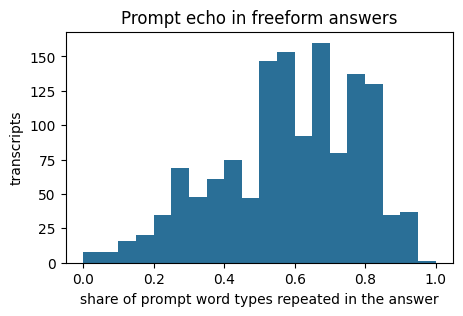

In [8]:
def _words(t):
    return re.findall(r"[\w']+", unicodedata.normalize("NFC", str(t)).lower().replace("\u2019", "'"))

def prompt_echo(row):
    pw, tw = _words(row["prompt"]), _words(row["transcript"])
    if not pw or not tw:
        return pd.Series({"prompt_coverage": np.nan, "opens_with_prompt": False})
    ps = set(pw)
    cov = len(ps & set(tw)) / len(ps)
    head = tw[:10]
    return pd.Series({"prompt_coverage": cov, "opens_with_prompt": np.mean([w in ps for w in head]) >= 0.7})

if "prompt" in ff_raw:
    echo = ff_raw.apply(prompt_echo, axis=1)
    ff_raw["prompt_coverage"] = echo["prompt_coverage"]; ff_raw["opens_with_prompt"] = echo["opens_with_prompt"].astype(bool)
    AUDIT["prompt_echo"] = {
        "median_share_of_prompt_words_in_transcript": round(float(ff_raw["prompt_coverage"].median()), 3),
        "share_of_transcripts_covering_>=80%_of_prompt_words": round(float((ff_raw["prompt_coverage"] >= 0.8).mean()), 3),
        "share_of_transcripts_opening_with_the_prompt": round(float(ff_raw["opens_with_prompt"].mean()), 3),
    }
    print(json.dumps(AUDIT["prompt_echo"], indent=1))
    fig, ax = plt.subplots(figsize=(5, 3)) if "plt" in globals() else (None, None)
    if ax is not None:
        ax.hist(ff_raw["prompt_coverage"].dropna(), bins=20, color="#2a6f97")
        ax.set_xlabel("share of prompt word types repeated in the answer"); ax.set_ylabel("transcripts")
        ax.set_title("Prompt echo in freeform answers"); plt.show()

In [9]:
json.dump(AUDIT, open(OUT / "results" / "audit.json", "w"), indent=2, default=str)
print("Saved results/audit.json")

Saved results/audit.json


### 3.4 Data provenance: facts, processing and assumptions
The brief asks me to keep three things apart: what the dataset itself provides, what this project did to it, and what I assume without being able to prove it. The cell below lists all three and saves them to `results/data_provenance.json` for the report.

In [10]:
fa = AUDIT["freeform"]
PROVENANCE = {
    "A_facts_from_dataset": [
        "Source: Hugging Face dataset MCAA1-MSU/twb_luo_ke, revision " + str(DATASET_REVISION),
        "Creators: Utavu Foundation and CLEAR Global; collected on the TWB Voice platform; steward: Maseno Centre for Applied AI (dataset card)",
        "Licence: Nwulite Obodo Open Data License NOODL-1.0 (dataset card); access gated behind accepting conditions",
        "Language: Dholuo (luo); dialect groups Nyanduat (North: Siaya, Kisumu) and Milambo (South: Homa Bay, Migori) (dataset card)",
        "Domain: agriculture; spontaneous answers to Dholuo prompts; recorded 16 May - 16 June 2026 (dataset card)",
        f"Freeform subset as loaded: {fa['n_rows']} rows, {fa['n_speakers']} speakers, {fa.get('n_unique_prompts')} unique prompts, {AUDIT['label']['n_classes_total']} sub-domains",
        f"Transcripts with [cs] code-switch tags: {fa['transcripts_with_cs_tag']}; with an odd number of [cs] tags: {fa['transcripts_with_odd_cs_tag_count']}",
        f"Bracket tag variants observed: {list(fa['bracket_tag_variants'].keys())[:10]}",
        f"Prompts that map to more than one sub-domain: {AUDIT['label']['prompts_mapping_to_more_than_one_sub_domain']}",
        "Transcripts were editor-reviewed; the card reports no separate third-person quality check",
    ],
    "B_processing_by_this_project": [
        "Column names lower-cased and mapped to dataset-card names (filename->file_name, subdomain->sub_domain, serial->prompt_id)",
        "Rows with empty transcripts or transcription_approval_status == 'rejected' removed",
        "Duplicate file_name rows and exact duplicate (speaker, transcript) pairs removed (first kept)",
        f"Target restricted to sub-domains with >= {CFG['min_class_count']} recordings and >= {CFG['min_class_speakers']} speakers",
        "Three text variants built: minimal (NFC + whitespace), normalized (+ apostrophes, lower-case, canonical <cs>/<pause>/<unclear> tokens, punctuation spacing), normalized_notags (tag markers removed, code-switched words kept)",
        "Dialect taken from primary_dholuo_variant (project survey), mapped to Nyanduat / Milambo / Unknown",
        "Speaker-disjoint train/validation/test split by constrained random search over speakers (seed " + str(CFG["seed"]) + ")",
        "Transcripts cached only in /kaggle/tmp; outputs contain IDs, metrics and models, not raw text files",
    ],
    "C_assumptions": [
        "The sub_domain of the prompt is a valid label for the spoken answer (answers stay on topic); checked qualitatively, not guaranteed",
        "The editor-approved transcript is treated as the ground-truth text; transcription errors are label-independent noise",
        "contributor_id identifies one person consistently across subsets (stated by the card) and is the right grouping unit for leakage control",
        "[cs] spans are a usable (if imperfect) indicator of code-switching for subgroup analysis",
        "Performance on unseen speakers is the condition that matters for deployment",
        "Speakers' dialect is constant across their recordings (taken from their survey answer)",
    ],
}
for k, items in PROVENANCE.items():
    display(Markdown(f"**{k}**\n" + "\n".join(f"- {i}" for i in items)))
json.dump(PROVENANCE, open(OUT / "results" / "data_provenance.json", "w"), indent=2)

**A_facts_from_dataset**
- Source: Hugging Face dataset MCAA1-MSU/twb_luo_ke, revision 5cbcd61d844e29e80e5e574fa14a7c54603052c3
- Creators: Utavu Foundation and CLEAR Global; collected on the TWB Voice platform; steward: Maseno Centre for Applied AI (dataset card)
- Licence: Nwulite Obodo Open Data License NOODL-1.0 (dataset card); access gated behind accepting conditions
- Language: Dholuo (luo); dialect groups Nyanduat (North: Siaya, Kisumu) and Milambo (South: Homa Bay, Migori) (dataset card)
- Domain: agriculture; spontaneous answers to Dholuo prompts; recorded 16 May - 16 June 2026 (dataset card)
- Freeform subset as loaded: 1359 rows, 23 speakers, 1019 unique prompts, 30 sub-domains
- Transcripts with [cs] code-switch tags: 225; with an odd number of [cs] tags: 1
- Bracket tag variants observed: ['[cs]', '[?]', '[pause]', '[[cs]', '[CS]', '[saa]', '[Pause]']
- Prompts that map to more than one sub-domain: 0
- Transcripts were editor-reviewed; the card reports no separate third-person quality check

**B_processing_by_this_project**
- Column names lower-cased and mapped to dataset-card names (filename->file_name, subdomain->sub_domain, serial->prompt_id)
- Rows with empty transcripts or transcription_approval_status == 'rejected' removed
- Duplicate file_name rows and exact duplicate (speaker, transcript) pairs removed (first kept)
- Target restricted to sub-domains with >= 25 recordings and >= 5 speakers
- Three text variants built: minimal (NFC + whitespace), normalized (+ apostrophes, lower-case, canonical <cs>/<pause>/<unclear> tokens, punctuation spacing), normalized_notags (tag markers removed, code-switched words kept)
- Dialect taken from primary_dholuo_variant (project survey), mapped to Nyanduat / Milambo / Unknown
- Speaker-disjoint train/validation/test split by constrained random search over speakers (seed 42)
- Transcripts cached only in /kaggle/tmp; outputs contain IDs, metrics and models, not raw text files

**C_assumptions**
- The sub_domain of the prompt is a valid label for the spoken answer (answers stay on topic); checked qualitatively, not guaranteed
- The editor-approved transcript is treated as the ground-truth text; transcription errors are label-independent noise
- contributor_id identifies one person consistently across subsets (stated by the card) and is the right grouping unit for leakage control
- [cs] spans are a usable (if imperfect) indicator of code-switching for subgroup analysis
- Performance on unseen speakers is the condition that matters for deployment
- Speakers' dialect is constant across their recordings (taken from their survey answer)

## 4. Task decision
The table compares the two tasks the data could support. Topic classification wins on almost every practical criterion: every free-form transcript has a label, the classical → recurrent → pretrained ladder required by the brief applies directly, and all experiments fit in the Kaggle GPU budget with three seeds each. Speech recognition is the obvious next step and can reuse the same speaker-disjoint split, but it would allow at most one seed per configuration here and has no meaningful TF-IDF or BiLSTM baseline.

In [11]:
hours = AUDIT["freeform"].get("total_hours")
hours_img = AUDIT.get("image", {}).get("total_hours")
decision = pd.DataFrame([
    {"criterion": "Labels / paired data",
     "topic classification": f"sub_domain on all {fa['n_rows']} freeform rows",
     "ASR": f"audio+transcript pairs, ~{hours} h freeform + ~{hours_img} h image"},
    {"criterion": "Examples after eligibility filter",
     "topic classification": f"{AUDIT['label']['rows_in_eligible_classes']} rows / {AUDIT['label']['n_classes_eligible']} classes",
     "ASR": "all rows usable"},
    {"criterion": "Speaker-independent evaluation",
     "topic classification": f"{fa['n_speakers']} speakers -> test set of ~5 unseen speakers",
     "ASR": "same constraint"},
    {"criterion": "Classical / RNN / pretrained ladder (brief §8)",
     "topic classification": "all three levels apply directly",
     "ASR": "no meaningful TF-IDF or BiLSTM level"},
    {"criterion": "Experiments A-G within Kaggle GPU quota",
     "topic classification": "all, with 3 seeds",
     "ASR": "1 seed per config at most; ~1 GPU-hour per fine-tune"},
    {"criterion": "Deployable component",
     "topic classification": "text -> topic + confidence (routing farmer questions)",
     "ASR": "audio -> transcript"},
])
display(decision)
display(Markdown(
    "**Decision:** primary task = speaker-independent sub-domain classification of transcripts. "
    "ASR is out of scope for the evaluated system and is listed as future work; the speaker-disjoint split saved "
    "in `results/splits.csv` can be reused for it."))

,criterion,topic classification,ASR
0,Labels / paired data,sub_domain on all 1359 freeform rows,"audio+transcript pairs, ~10.64 h freeform + ~8.93 h image"
1,Examples after eligibility filter,1248 rows / 23 classes,all rows usable
2,Speaker-independent evaluation,23 speakers -> test set of ~5 unseen speakers,same constraint
3,Classical / RNN / pretrained ladder (brief §8),all three levels apply directly,no meaningful TF-IDF or BiLSTM level
4,Experiments A-G within Kaggle GPU quota,"all, with 3 seeds",1 seed per config at most; ~1 GPU-hour per fine-tune
5,Deployable component,text -> topic + confidence (routing farmer questions),audio -> transcript


**Decision:** primary task = speaker-independent sub-domain classification of transcripts. ASR is out of scope for the evaluated system and is listed as future work; the speaker-disjoint split saved in `results/splits.csv` can be reused for it.

### 4.1 Who would use this, and why it matters
The model takes a farmer's Dholuo question or comment - typed, or transcribed from speech - and assigns it an agricultural topic so it can be routed to the right information or person. Three groups would use it:

* **Agricultural extension services and farmer call or SMS lines** in Dholuo-speaking counties such as Kisumu, Siaya, Homa Bay and Migori, to send incoming questions to the right officer or FAQ (poultry, fish farming, irrigation, subsidies and so on).
* **Builders of voice services**, including the TWB Voice / CLEAR Global ecosystem that collected this data, as a topic layer after speech recognition.
* **Researchers in African-language NLP**, as a speaker-independent benchmark for fine-grained topic classification of spontaneous spoken Dholuo, with the speaker and prompt leakage analyses that most benchmarks do not report.

Dholuo is used mostly in informal settings, while formal domains such as government, education and commerce run largely in English and Kiswahili (*Building low-resource African language corpora: A case study of Kidawida, Kalenjin and Dholuo*, arXiv:2501.11003). Farmers who are most comfortable in Dholuo are therefore the least served by text-based agricultural information systems. The system is meant as a **low-stakes routing aid**: a wrong topic sends a question to the wrong queue, where a person can correct it; it is never used to decide anything about a person.

### 4.2 Is the task already solved?
| Resource | Covers Dholuo? | What it does | Why it does not answer my question |
|---|---|---|---|
| **Google Translate** | Yes, since July 2024 | Machine translation | Translation, not topic classification; closed, so it cannot be evaluated reproducibly here |
| **NLLB-200** (NLLB Team, 2022) | Yes (`luo_Latn`) | Open machine translation | Same limitation, but open - so Experiment I tests directly whether translating to English and classifying there already works |
| **SIB-200** (Adelani et al., 2024) | Yes, through Flores-200 | 7 broad topics on about 1,000 sentences translated from English Wikipedia | Written, translated, general-domain text; no agriculture, no spontaneous speech, no speakers |
| **MasakhaNEWS** (Adelani et al., 2023) | No - its 16 languages do not include Luo | News topic classification | Language not covered |
| **AfroXLMR-large-114L** (Alabi et al., 2022) | Luo is listed among its pretraining languages | Pretrained encoder with no task head | Needs labelled task data, which is what this project provides |

To my knowledge, no public dataset or model covers fine-grained agricultural topic classification of spontaneous Dholuo evaluated on unseen speakers. Experiment I backs this up with numbers: the best "existing tools" route reaches a macro-F1 of 0.318, significantly below the 0.413 of the Dholuo-trained SVM.

## 5. Cleaning and text normalisation
The cleaning steps (empty transcripts, rejected transcriptions, duplicate files, duplicate speaker–transcript pairs) removed nothing, which confirms the audit; the only rows dropped are the 111 recordings in the seven classes that are too small to evaluate fairly. That leaves **1,248 transcripts, 23 speakers and 23 classes**.

I build three text versions so that Experiment B can test whether normalisation helps:
* **minimal** - Unicode NFC and whitespace only;
* **normalized** - also straight apostrophes, lower case, consistent spacing around punctuation, and one canonical token each for code-switching (`<cs>`), pauses (`<pause>`) and unclear speech (`<unclear>`), whatever spelling the transcriber used;
* **normalized_notags** - as above, but with the markers removed while keeping the code-switched words themselves.

I deliberately do not remove stop words, stem, "correct" spellings, strip apostrophes inside words such as *ng'ado*, or delete English and Kiswahili words - these carry real linguistic information. The preprocessing code is written once and saved to `models/preprocess.py`, so the deployed app applies exactly the same steps as the evaluated model.

In [12]:
PREPROC_SRC = r'''
import re, unicodedata

TAG_RE = re.compile(r"\[\s*([^\]\[]{0,20}?)\s*\]")
APOS_MAP = str.maketrans({"’": "'", "‘": "'", "`": "'", "´": "'", "ʼ": "'"})
_WS = re.compile(r"\s+")
_SPACE_BEFORE_PUNCT = re.compile(r"\s+([,.;:!?])")
_NO_SPACE_AFTER_PUNCT = re.compile(r"([,.;:!?])(?=[^\s\d,.;:!?<'\"])")

def canonical_tag(inner):
    """Map transcription markers to one canonical token each; unknown markers become <tag>."""
    t = inner.strip().lower().replace(" ", "")
    if t in ("cs", "codeswitch", "code-switch"):
        return " <cs> "
    if t in ("pause", "pauses"):
        return " <pause> "
    if t in ("?", "??", "unclear", "inaudible"):
        return " <unclear> "
    return " <tag> "

def normalize_minimal(text):
    """Control condition for Experiment B: Unicode NFC + whitespace only."""
    t = unicodedata.normalize("NFC", str(text))
    return _WS.sub(" ", t).strip()

def normalize_full(text, keep_tags=True):
    """NFC, straight apostrophes, canonical markers, lower-case, consistent punctuation spacing."""
    t = unicodedata.normalize("NFC", str(text)).translate(APOS_MAP)
    t = TAG_RE.sub(lambda m: canonical_tag(m.group(1)) if keep_tags else " ", t)
    t = t.lower()
    t = _SPACE_BEFORE_PUNCT.sub(r"\1", t)
    t = _NO_SPACE_AFTER_PUNCT.sub(r"\1 ", t)
    return _WS.sub(" ", t).strip()

TEXT_VARIANTS = {
    "minimal": normalize_minimal,
    "normalized": lambda t: normalize_full(t, keep_tags=True),
    "normalized_notags": lambda t: normalize_full(t, keep_tags=False),
}

TOKEN_RE = re.compile(r"<[a-z_]+>|\[[^\]]*\]|[\w']+|[^\w\s]")
WORD_PATTERN = r"<[a-z_]+>|\[[^\]]*\]|[\w']+"

def tokenize(text):
    return TOKEN_RE.findall(text)
'''
exec(PREPROC_SRC)
(OUT / "models").mkdir(exist_ok=True)
(OUT / "models" / "preprocess.py").write_text(PREPROC_SRC)

for s in ["Nyithindo ipuonjo yore mag pur ,koro [CS]net[cs] ok?",
          "Jopur  gi’ jopith [pause] maber [?] ahinya.",
          "Ng'ado cham 2.5 kg [cs]fertilizer[cs]"]:
    print(repr(s))
    for k, f in TEXT_VARIANTS.items():
        print(f"   {k:18s} -> {f(s)!r}")

'Nyithindo ipuonjo yore mag pur ,koro [CS]net[cs] ok?'
   minimal            -> 'Nyithindo ipuonjo yore mag pur ,koro [CS]net[cs] ok?'
   normalized         -> 'nyithindo ipuonjo yore mag pur, koro <cs> net <cs> ok?'
   normalized_notags  -> 'nyithindo ipuonjo yore mag pur, koro net ok?'
'Jopur  gi’ jopith [pause] maber [?] ahinya.'
   minimal            -> 'Jopur gi’ jopith [pause] maber [?] ahinya.'
   normalized         -> "jopur gi' jopith <pause> maber <unclear> ahinya."
   normalized_notags  -> "jopur gi' jopith maber ahinya."
"Ng'ado cham 2.5 kg [cs]fertilizer[cs]"
   minimal            -> "Ng'ado cham 2.5 kg [cs]fertilizer[cs]"
   normalized         -> "ng'ado cham 2.5 kg <cs> fertilizer <cs>"
   normalized_notags  -> "ng'ado cham 2.5 kg fertilizer"


In [13]:
clean_log = []
def keep(df, mask, step, reason):
    mask = mask.fillna(False) if hasattr(mask, "fillna") else mask
    clean_log.append({"step": step, "reason": reason, "rows_before": len(df), "removed": int((~mask).sum()),
                      "rows_after": int(mask.sum())})
    return df[mask].copy()

df = ff_raw.copy()
df = keep(df, df["transcript"].fillna("").str.strip() != "", "empty transcript", "nothing to classify")
if "transcription_approval_status" in df:
    df = keep(df, df["transcription_approval_status"].fillna("").str.lower() != "rejected",
              "rejected transcription", "validators rejected the text")
df = keep(df, ~df["file_name"].duplicated(), "duplicate file_name", "one recording must appear once")
df = keep(df, ~df.duplicated(["contributor_id", "transcript"]), "duplicate (speaker, transcript)",
          "identical rows add no information and can straddle splits")
cross_speaker_dupes = int(df["transcript"].duplicated(keep=False).sum())
print("Identical transcripts from different speakers (kept, flagged):", cross_speaker_dupes)

_c = df.groupby("sub_domain").agg(n=("file_name", "size"), s=("contributor_id", "nunique"))
eligible = _c.index[(_c["n"] >= CFG["min_class_count"]) & (_c["s"] >= CFG["min_class_speakers"])].tolist()
if set(eligible) != set(cls_tab.index[cls_tab["eligible"]]):
    print("Eligibility changed after cleaning:", sorted(set(eligible) ^ set(cls_tab.index[cls_tab["eligible"]])))
df = keep(df, df["sub_domain"].isin(eligible), "class not eligible",
          f"<{CFG['min_class_count']} rows or <{CFG['min_class_speakers']} speakers")

for name, fn in TEXT_VARIANTS.items():
    df[f"text_{name}"] = df["transcript"].map(fn)
TEXT_COL = {k: f"text_{k}" for k in TEXT_VARIANTS}

df["n_words"] = df["transcript"].map(word_count)
df["n_cs"] = df["transcript"].map(lambda s: len(CS_TAG_RE.findall(s)))
df["has_cs"] = df["n_cs"] > 0
df = df.merge(meta[[c for c in ["contributor_id", "dialect", "gender", "age_category"] if c in meta]],
              on="contributor_id", how="left")
df["dialect"] = df["dialect"].fillna("Unknown")
if "duration_sec" in df:
    df["duration_sec"] = pd.to_numeric(df["duration_sec"], errors="coerce")
    _rate = df["n_words"] / df["duration_sec"]
    df["rate_outlier"] = ((_rate < 0.5) | (_rate > 4.5)).fillna(False)
else:
    df["rate_outlier"] = False

LABELS = sorted(df["sub_domain"].unique())
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
df["y"] = df["sub_domain"].map(LABEL2ID)
K = len(LABELS)

clean_log = pd.DataFrame(clean_log)
display(clean_log)
clean_log.to_csv(OUT / "results" / "cleaning_log.csv", index=False)
print(f"Modelling set: {len(df)} rows, {df['contributor_id'].nunique()} speakers, {K} classes")

Identical transcripts from different speakers (kept, flagged): 0


,step,reason,rows_before,removed,rows_after
0,empty transcript,nothing to classify,1359,0,1359
1,rejected transcription,validators rejected the text,1359,0,1359
2,duplicate file_name,one recording must appear once,1359,0,1359
3,"duplicate (speaker, transcript)",identical rows add no information and can straddle splits,1359,0,1359
4,class not eligible,<25 rows or <5 speakers,1359,111,1248


Modelling set: 1248 rows, 23 speakers, 23 classes


## 6. Speaker-disjoint split and leakage checks
With only 23 speakers, picking test speakers at random can easily leave a class or a dialect missing from the test set. I therefore searched 20,000 random speaker groupings (seed 42) and kept the one whose class distribution best matched the whole dataset, at roughly 20% of rows for test and 15% for validation, with every class and both dialects present. The choice used only labels and metadata, never model results.

The result is **810 training transcripts from 13 speakers, 188 validation transcripts from 5 speakers and 250 test transcripts from 5 speakers**. All 23 classes appear in every split, both dialects appear in validation and test, and no speaker appears in more than one split. There are no exact or near-duplicate transcripts across splits. The one remaining overlap is by design and is measured rather than hidden: **101 of the 250 test answers respond to a prompt that a training speaker also answered** (Experiment H).

One imbalance is worth noting for the dialect analysis: only 3 of the 13 training speakers are Milambo speakers, while 3 of the 5 test speakers are.

In [14]:
def jsd(p, q):
    p = np.asarray(p, float) + 1e-12; q = np.asarray(q, float) + 1e-12
    p /= p.sum(); q /= q.sum(); m = (p + q) / 2
    return 0.5 * (np.sum(p * np.log(p / m)) + np.sum(q * np.log(q / m)))

def search_holdout(frame, candidate_speakers, target_rows, rng, n_trials, required_dialects):
    sub = frame[frame["contributor_id"].isin(candidate_speakers)]
    counts = sub.groupby(["contributor_id", "y"]).size().unstack(fill_value=0).reindex(columns=range(K), fill_value=0)
    spk = counts.index.to_numpy()
    mat = counts.to_numpy()
    overall = frame.groupby("y").size().reindex(range(K), fill_value=0).to_numpy()
    dia = sub.groupby("contributor_id")["dialect"].agg(lambda s: s.mode().iloc[0]).reindex(spk).to_numpy()
    best = None
    for _ in range(n_trials):
        order = rng.permutation(len(spk))
        tot = np.zeros(K); chosen = []
        for i in order:
            if tot.sum() >= target_rows:
                break
            chosen.append(i); tot = tot + mat[i]
        size_pen = abs(tot.sum() - target_rows) / target_rows
        missing = float((tot == 0).mean())
        dia_pen = 0.0 if set(required_dialects) <= set(dia[chosen]) else 1.0
        score = jsd(tot, overall) + 0.5 * size_pen + 0.5 * missing + dia_pen
        if best is None or score < best[0]:
            best = (score, sorted(str(x) for x in spk[chosen]),
                    {"jsd": round(jsd(tot, overall), 4), "rows": int(tot.sum()), "missing_classes": int((tot == 0).sum()),
                     "dialects": sorted(set(dia[chosen]))})
    return best

rng = np.random.default_rng(CFG["seed"])
spk_dialect = df.groupby("contributor_id")["dialect"].agg(lambda s: s.mode().iloc[0])
dialect_spk_counts = spk_dialect[spk_dialect != "Unknown"].value_counts()
REQUIRED_DIALECTS = dialect_spk_counts[dialect_spk_counts >= 3].index.tolist()
all_spk = sorted(df["contributor_id"].unique())

score_t, test_spk, info_t = search_holdout(df, all_spk, CFG["test_frac"] * len(df), rng, CFG["split_trials"], REQUIRED_DIALECTS)
rest = [s for s in all_spk if s not in test_spk]
score_v, val_spk, info_v = search_holdout(df, rest, CFG["val_frac"] * len(df), rng, CFG["split_trials"], REQUIRED_DIALECTS)
df["split"] = np.where(df["contributor_id"].isin(test_spk), "test",
               np.where(df["contributor_id"].isin(val_spk), "val", "train"))
print("test speakers:", test_spk, info_t)
print("val speakers: ", val_spk, info_v)

TR = df[df["split"] == "train"].reset_index(drop=True)
VA = df[df["split"] == "val"].reset_index(drop=True)
TE = df[df["split"] == "test"].reset_index(drop=True)
DEV = df[df["split"] != "test"].reset_index(drop=True)      # train+val, used for speaker-grouped CV

df[["file_name", "contributor_id", "split"]].to_csv(OUT / "results" / "splits.csv", index=False)
df.to_pickle(PRIVATE / "modelling_data.pkl")   # contains transcripts -> private cache only

test speakers: ['2c528070', '44583d89', '58a66fc4', '5971d88c', 'd3a663cb'] {'jsd': np.float64(0.0044), 'rows': 250, 'missing_classes': 0, 'dialects': ['Milambo', 'Nyanduat']}
val speakers:  ['1682355b', '25110697', '54eb4538', '89f0a13b', 'dcbf6f84'] {'jsd': np.float64(0.0075), 'rows': 188, 'missing_classes': 0, 'dialects': ['Milambo', 'Nyanduat']}


In [15]:
def split_summary():
    rows = []
    for name, part in [("train", TR), ("val", VA), ("test", TE)]:
        rows.append({"split": name, "rows": len(part), "speakers": part["contributor_id"].nunique(),
                     "classes_present": part["y"].nunique(), "Nyanduat_spk": part.loc[part.dialect == "Nyanduat", "contributor_id"].nunique(),
                     "Milambo_spk": part.loc[part.dialect == "Milambo", "contributor_id"].nunique(),
                     "female_spk": part.loc[part["gender"] == "Female", "contributor_id"].nunique() if "gender" in part else None,
                     "cs_rows": int(part["has_cs"].sum()), "mean_words": round(part["n_words"].mean(), 1)})
    return pd.DataFrame(rows)

SPLIT_SUMMARY = split_summary()
display(SPLIT_SUMMARY)

per_class = pd.crosstab(df["sub_domain"], df["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
display(per_class)

# --- leakage checks ---
assert not (set(TR.contributor_id) & set(TE.contributor_id)), "speaker leakage train/test"
assert not (set(TR.contributor_id) & set(VA.contributor_id)), "speaker leakage train/val"
assert not (set(VA.contributor_id) & set(TE.contributor_id)), "speaker leakage val/test"

train_prompts = set(TR["prompt_id"].dropna())
TE["prompt_seen_in_train"] = TE["prompt_id"].isin(train_prompts)
VA["prompt_seen_in_train"] = VA["prompt_id"].isin(train_prompts)
exact_text_overlap = int(TE["text_normalized"].isin(set(TR["text_normalized"])).sum())

near_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit(df["text_normalized"])
sim = cosine_similarity(near_vec.transform(TE["text_normalized"]), near_vec.transform(TR["text_normalized"]))
TE["max_sim_to_train"] = sim.max(axis=1)
LEAKAGE = {
    "speaker_overlap_train_test": 0, "speaker_overlap_train_val": 0, "speaker_overlap_val_test": 0,
    "test_rows_whose_prompt_appears_in_train": int(TE["prompt_seen_in_train"].sum()),
    "test_rows_total": int(len(TE)),
    "exact_transcript_overlap_test_train": exact_text_overlap,
    "test_rows_with_char_cosine_gt_0.9_to_a_train_row": int((TE["max_sim_to_train"] > 0.9).sum()),
    "classes_missing_in_val": [LABELS[i] for i in range(K) if i not in set(VA.y)],
    "classes_missing_in_test": [LABELS[i] for i in range(K) if i not in set(TE.y)],
    "dialects_in_test": sorted(TE["dialect"].unique()),
}
print(json.dumps(LEAKAGE, indent=1))
json.dump({"leakage": LEAKAGE, "test_speakers": test_spk, "val_speakers": val_spk,
           "split_search": {"test": info_t, "val": info_v}, "split_summary": SPLIT_SUMMARY.to_dict("records")},
          open(OUT / "results" / "split_report.json", "w"), indent=2, default=str)

,split,rows,speakers,classes_present,Nyanduat_spk,Milambo_spk,female_spk,cs_rows,mean_words
0,train,810,13,23,10,3,6,113,52.0
1,val,188,5,23,2,3,2,38,79.6
2,test,250,5,23,2,3,3,52,70.9


split,train,val,test
sub_domain,,,
Access to government programs and subsidies,52,12,19
Agricultural education,39,6,7
Animal feeding and nutrition,34,7,13
Automation and AI in farming,28,4,8
Climate resilience and adaptation strategies,29,5,11
Contemporary issues in Agriculture,43,12,13
Crop Yield and quality,19,4,4
"Distribution channels (local, regional, international)",28,5,11
Economic impact of agricultural practices,27,9,9


{
 "speaker_overlap_train_test": 0,
 "speaker_overlap_train_val": 0,
 "speaker_overlap_val_test": 0,
 "test_rows_whose_prompt_appears_in_train": 101,
 "test_rows_total": 250,
 "exact_transcript_overlap_test_train": 0,
 "test_rows_with_char_cosine_gt_0.9_to_a_train_row": 0,
 "classes_missing_in_val": [],
 "classes_missing_in_test": [],
 "dialects_in_test": [
  "Milambo",
  "Nyanduat"
 ]
}


## 7. Exploratory data analysis
Each figure answers one question that affects a modelling or evaluation decision. Statistics that could guide modelling choices are computed on the training split only.

* **Q1** - the class sizes behind the eligibility rule in §3.2.
* **Q2** - the five most prolific speakers produce 35% of the modelling data, which is why every split decision is made at the speaker level.
* **Q3** - no topic is dominated by a single speaker, so a model cannot simply learn "who is talking".
* **Q4** - transcripts average about 60 words and 95% are under 109 words, so the BiLSTM's 200-token and the transformers' 256-subword limits truncate almost nothing.
* **Q5** - no transcript has an implausible speech rate.
* **Q6** - code-switching rates are similar in the two dialects (17.5% of Milambo and 15.6% of Nyanduat transcripts) but vary a lot between individual speakers.
* **Q7** - the vocabulary is long-tailed: half of the 3,608 word types in the training data occur only once. Unseen words make up 5.2% of test tokens under the speaker split versus 4.8% under a random split, a small but real speaker effect.
* **Q8** - the most class-indicative words are exactly what a Dholuo speaker would expect (*rech* "fish" for fish farming, *gweno/gwen* "chicken" for poultry, *sirikal* "government" for government programmes, *drone* and *robot* as English loanwords), so the label is genuinely recoverable from the wording.

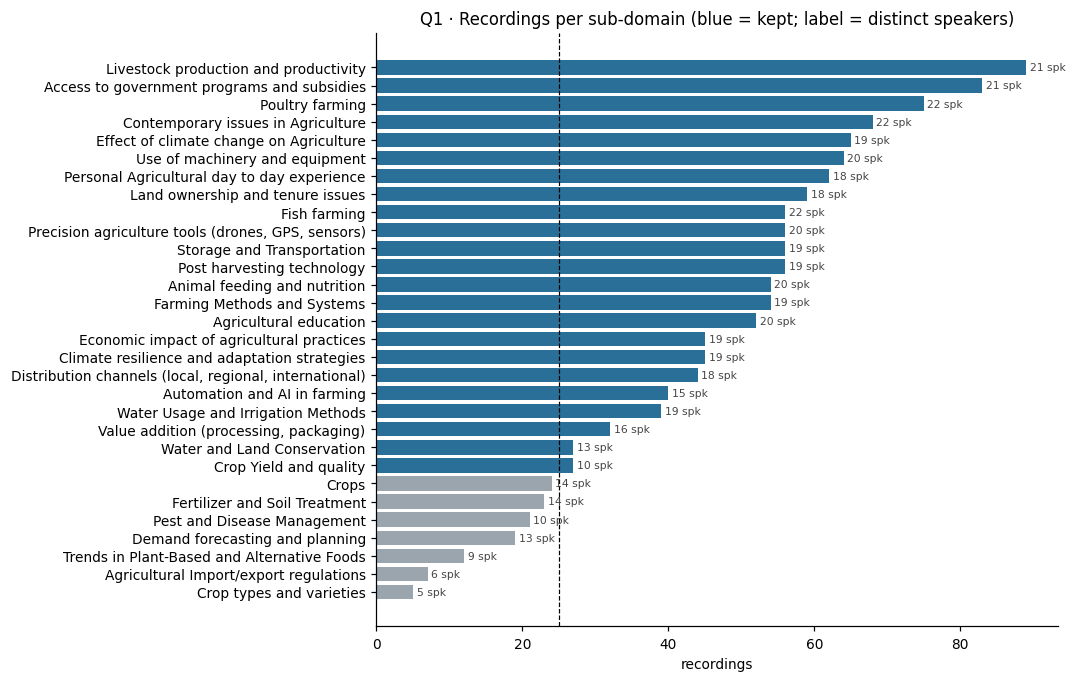

In [16]:
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
C_MAIN, C_ALT, C_MUTED = "#2a6f97", "#e07a5f", "#9aa5ad"

def savefig(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

# Q1: Which sub-domains have enough data and enough speakers to be learnt and evaluated?
fig, ax = plt.subplots(figsize=(8, 7))
ct = cls_tab.sort_values("n")
ax.barh(ct.index, ct["n"], color=[C_MAIN if e else C_MUTED for e in ct["eligible"]])
ax.axvline(CFG["min_class_count"], color="k", ls="--", lw=0.8)
for i, (n, s) in enumerate(zip(ct["n"], ct["n_speakers"])):
    ax.text(n + 0.5, i, f"{s} spk", va="center", fontsize=7, color="#444")
ax.set_xlabel("recordings"); ax.set_title("Q1 · Recordings per sub-domain (blue = kept; label = distinct speakers)")
savefig(fig, "q1_class_distribution")

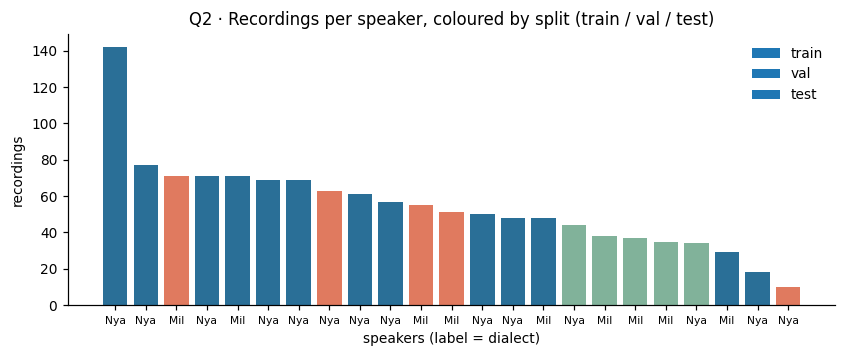

Share of modelling rows from the 5 most prolific speakers: 0.346


In [17]:
# Q2: How concentrated is the data in a few speakers, and which speakers carry the test set?
spk_tab = df.groupby("contributor_id").agg(n=("y", "size"), dialect=("dialect", "first"), split=("split", "first")).sort_values("n", ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.2))
cols = {"train": C_MAIN, "val": "#81b29a", "test": C_ALT}
ax.bar(range(len(spk_tab)), spk_tab["n"], color=[cols[s] for s in spk_tab["split"]])
ax.set_xticks(range(len(spk_tab)))
ax.set_xticklabels([f"{d[:3]}" for d in spk_tab["dialect"]], fontsize=7)
ax.set_ylabel("recordings"); ax.set_xlabel("speakers (label = dialect)")
ax.set_title("Q2 · Recordings per speaker, coloured by split (train / val / test)")
for s, c in cols.items():
    ax.bar([], [], color=c, label=s)
ax.legend(frameon=False)
savefig(fig, "q2_speaker_distribution")
print("Share of modelling rows from the 5 most prolific speakers:", round(spk_tab["n"].head(5).sum() / len(df), 3))

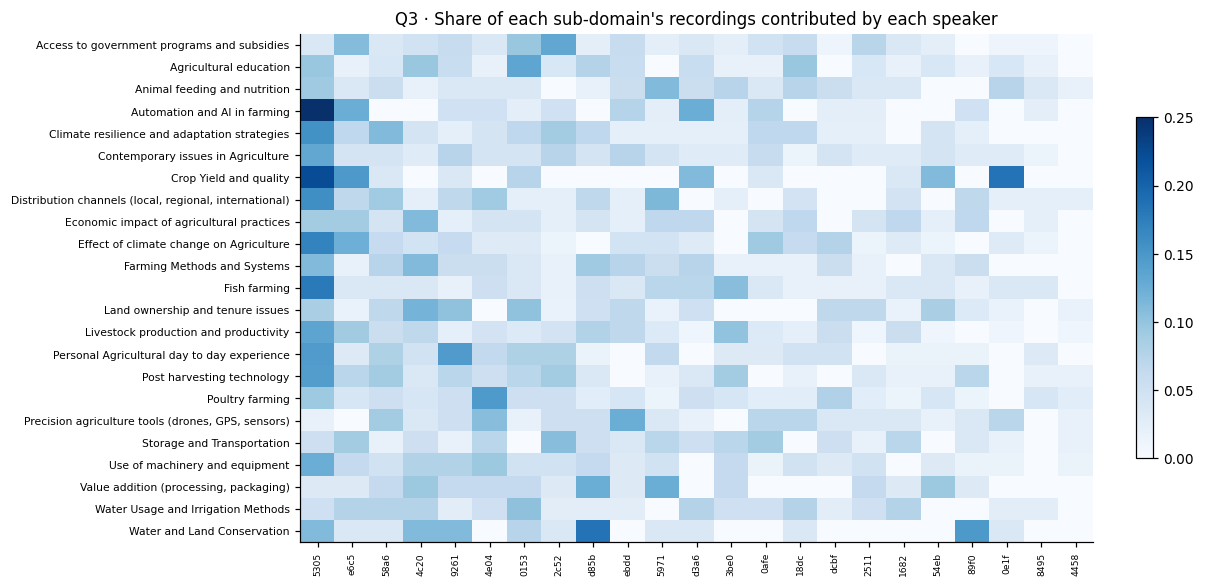

In [18]:
# Q3: Are topics confounded with speakers? (If a class comes mostly from one person, a model can learn the person.)
mat = pd.crosstab(df["sub_domain"], df["contributor_id"]).reindex(columns=spk_tab.index)
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(mat.div(mat.sum(axis=1), axis=0).values, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index, fontsize=7)
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels([s[:4] for s in mat.columns], rotation=90, fontsize=6)
ax.set_title("Q3 · Share of each sub-domain's recordings contributed by each speaker")
fig.colorbar(im, ax=ax, fraction=0.02)
savefig(fig, "q3_class_by_speaker")

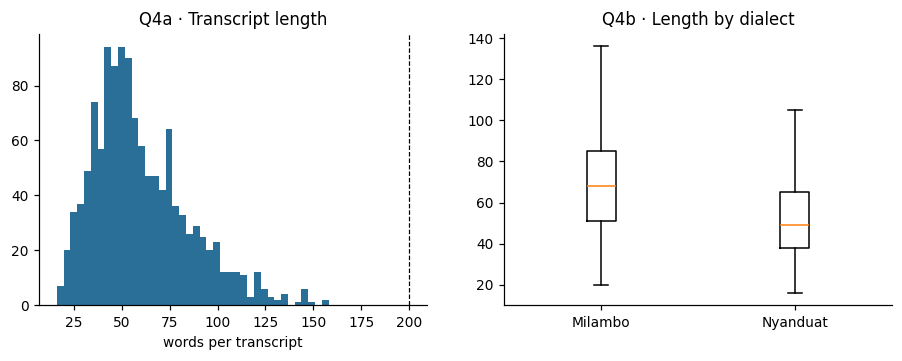

95th percentile words: 108.64999999999986 | max: 158


In [19]:
# Q4: How long are inputs? (sets max sequence length) Do dialect groups differ?
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(df["n_words"], bins=40, color=C_MAIN)
axes[0].axvline(CFG["bilstm"]["max_len"], color="k", ls="--", lw=0.8)
axes[0].set_xlabel("words per transcript"); axes[0].set_title("Q4a · Transcript length")
groups = [g["n_words"].values for _, g in df.groupby("dialect")]
axes[1].boxplot(groups, showfliers=False)
axes[1].set_xticks(range(1, len(groups) + 1)); axes[1].set_xticklabels([d for d, _ in df.groupby("dialect")])
axes[1].set_title("Q4b · Length by dialect")
savefig(fig, "q4_length")
print("95th percentile words:", np.percentile(df["n_words"], 95), "| max:", df["n_words"].max())

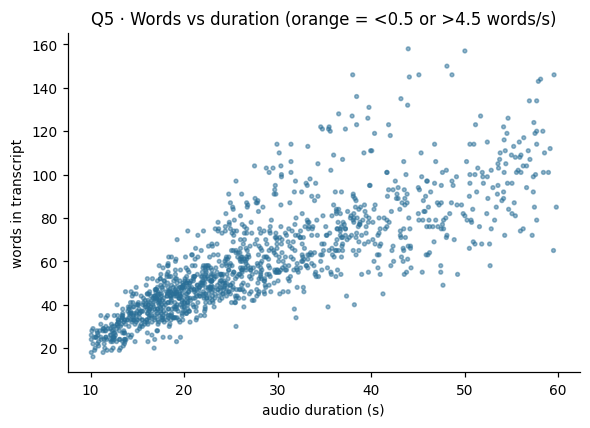

Speech-rate outliers in modelling set: 0


In [20]:
# Q5: Are some transcripts incomplete or misaligned with their audio? (speech rate outliers)
if "duration_sec" in df and df["duration_sec"].notna().any():
    rate = df["n_words"] / df["duration_sec"]
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(df["duration_sec"], df["n_words"], s=6, alpha=0.5, c=np.where((rate < 0.5) | (rate > 4.5), C_ALT, C_MAIN))
    ax.set_xlabel("audio duration (s)"); ax.set_ylabel("words in transcript")
    ax.set_title("Q5 · Words vs duration (orange = <0.5 or >4.5 words/s)")
    savefig(fig, "q5_speech_rate")
    print("Speech-rate outliers in modelling set:", int(df["rate_outlier"].sum()))
else:
    print("No duration column available in the loaded table; Q5 skipped.")

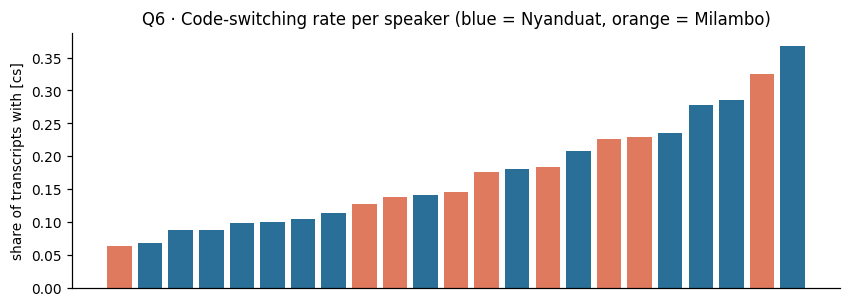

,mean,sum,size
dialect,,,
Milambo,0.175,76,435
Nyanduat,0.156,127,813


In [21]:
# Q6: How common is code-switching, and does it vary by speaker / dialect?
cs_spk = df.groupby("contributor_id").agg(cs_rate=("has_cs", "mean"), dialect=("dialect", "first")).sort_values("cs_rate")
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(cs_spk)), cs_spk["cs_rate"], color=[C_MAIN if d == "Nyanduat" else C_ALT for d in cs_spk["dialect"]])
ax.set_ylabel("share of transcripts with [cs]"); ax.set_xticks([])
ax.set_title("Q6 · Code-switching rate per speaker (blue = Nyanduat, orange = Milambo)")
savefig(fig, "q6_code_switching")
display(df.groupby("dialect")["has_cs"].agg(["mean", "sum", "size"]).round(3))

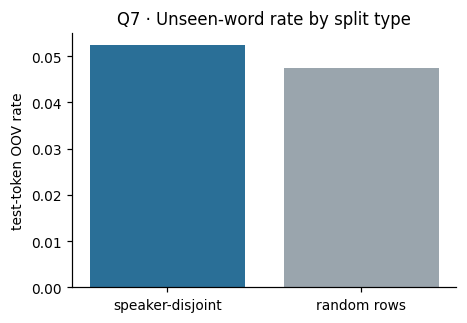

{
 "train_types": 3608,
 "train_tokens": 42106,
 "train_hapax_share": 0.512,
 "test_token_oov_rate_speaker_split": 0.0523,
 "test_token_oov_rate_random_split": 0.0475,
 "image_subset_types": 5254,
 "image_types_unseen_in_freeform_train": 0.606
}
Most frequent training tokens: [('ma', 1743), ('e', 1634), ('gi', 1471), ('ka', 866), ('ni', 783), ('to', 763), ('kata', 746), ('kendo', 662), ('mar', 655), ('cham', 546), ('jopur', 487), ('mondo', 472), ('kod', 466), ('bende', 439), ('nyalo', 421), ('maber', 406), ('mag', 391), ('go', 391), ('ok', 348), ('pur', 300), ('kaka', 299), ('miyo', 295), ("mang'eny", 276), ('en', 274), ('bedo', 265)]


In [22]:
# Q7: How much vocabulary is speaker-specific? Compare unseen-word rates for a speaker-disjoint vs a random split.
def vocab(texts):
    return Counter(t for s in texts for t in tokenize(s) if re.match(r"[\w']", t))

def oov_rate(train_texts, eval_texts):
    v = set(vocab(train_texts))
    toks = [t for s in eval_texts for t in tokenize(s) if re.match(r"[\w']", t)]
    return float(np.mean([t not in v for t in toks]))

tv = vocab(TR["text_normalized"])
hapax = sum(1 for c in tv.values() if c == 1)
rnd = df.sample(frac=1, random_state=CFG["seed"])
n_te = len(TE)
oov_spk = oov_rate(TR["text_normalized"], TE["text_normalized"])
oov_rnd = oov_rate(rnd["text_normalized"].iloc[n_te:n_te + len(TR)], rnd["text_normalized"].iloc[:n_te])
img_vocab = vocab(img_raw["transcript"].fillna("").map(TEXT_VARIANTS["normalized"])) if img_raw is not None and "transcript" in img_raw else Counter()
VOCAB_STATS = {"train_types": len(tv), "train_tokens": int(sum(tv.values())), "train_hapax_share": round(hapax / len(tv), 3),
               "test_token_oov_rate_speaker_split": round(oov_spk, 4), "test_token_oov_rate_random_split": round(oov_rnd, 4),
               "image_subset_types": len(img_vocab),
               "image_types_unseen_in_freeform_train": round(float(np.mean([w not in tv for w in img_vocab])), 3) if img_vocab else None}
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(["speaker-disjoint", "random rows"], [oov_spk, oov_rnd], color=[C_MAIN, C_MUTED])
ax.set_ylabel("test-token OOV rate"); ax.set_title("Q7 · Unseen-word rate by split type")
savefig(fig, "q7_oov_by_split")
print(json.dumps(VOCAB_STATS, indent=1))
print("Most frequent training tokens:", tv.most_common(25))

In [23]:
# Q8: Is the label recoverable from wording at all? Most class-associated words (chi2, training split only).
cv = TfidfVectorizer(token_pattern=WORD_PATTERN, lowercase=False, min_df=2)
Xtr = cv.fit_transform(TR["text_normalized"])
feat = np.array(cv.get_feature_names_out())
rows = []
for k in range(K):
    if (TR["y"] == k).sum() == 0:
        continue
    scores, _ = chi2(Xtr, (TR["y"] == k).astype(int))
    top = feat[np.argsort(np.nan_to_num(scores))[::-1][:8]]
    rows.append({"sub_domain": LABELS[k], "train_n": int((TR["y"] == k).sum()), "top chi2 words": ", ".join(top)})
display(pd.DataFrame(rows))
json.dump(VOCAB_STATS, open(OUT / "results" / "vocab_stats.json", "w"), indent=2)

,sub_domain,train_n,top chi2 words
0,Access to government programs and subsidies,52,"sirikal, ogore, bechgi, gikelo, chenro, kothe, hola, tingni"
1,Agricultural education,39,"tiegruok, anguro, puonj, ichiwo, ohand, ng'eyo, lonyo, otieg"
2,Animal feeding and nutrition,34,"lum, chiemo, jambgi, ocham, jamni, lumb, chumbi, ging'ado"
3,Automation and AI in farming,28,"niang', lando, robot, internet, ong'weyamo, komputa, yugi, mapuro"
4,Climate resilience and adaptation strategies,29,"yiende, ywer, bath, ging'iew, mtaro, kochwe, gisegolo, pige"
5,Contemporary issues in Agriculture,43,"ge, kome, gwenge, pur, modak, nyamburko, ipuro, bombe"
6,Crop Yield and quality,19,"ng'ima, buya, koponi, nyak, opitho, okenge, oduma, opuodh"
7,"Distribution channels (local, regional, international)",28,"ginyago, riwruoge, ang'o, store, chamni, gik, oken, use"
8,Economic impact of agricultural practices,27,"ochul, kouso, skul, tij, chando, nie, gikayo, iyudoni"
9,Effect of climate change on Agriculture,46,"thiro, olokore, moingo, ochele, lwasi, dag, olemo, kor"


## 8. Evaluation utilities and the results registry
Every model run, in every experiment and with every seed, is appended to `results/all_runs.csv` with its validation and test metrics; re-running a cell replaces its rows instead of duplicating them. Macro metrics average over the classes present in the evaluated split.

Test scores are recorded for every run so they can be reported, but **only validation scores are ever used to make a choice** - hyperparameters, the text variant and the final model. Confidence intervals come from bootstrap resampling of test rows and, more conservatively, of whole test speakers; model comparisons use a paired bootstrap on the same resamples.

In [24]:
LABEL_IDS = list(range(K))
RUNS, PREDS, MODEL_OBJECTS, RUN_DIRS = [], {}, {}, {}
Y = {"train": TR["y"].to_numpy(), "val": VA["y"].to_numpy(), "test": TE["y"].to_numpy()}

def clf_metrics(y, p):
    labs = np.unique(y)
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=labs, average="macro", zero_division=0)
    return {"acc": accuracy_score(y, p), "macro_p": pr, "macro_r": rc, "macro_f1": f1,
            "weighted_f1": f1_score(y, p, labels=labs, average="weighted", zero_division=0)}

def macro_f1(y, p):
    return f1_score(y, p, labels=np.unique(y), average="macro", zero_division=0)

def bootstrap_ci(y, p, fn=macro_f1, iters=None, groups=None, seed=0):
    iters = iters or CFG["bootstrap_iters"]; rng_b = np.random.default_rng(seed)
    y = np.asarray(y); p = np.asarray(p); vals = []
    if groups is None:
        for _ in range(iters):
            idx = rng_b.integers(0, len(y), len(y)); vals.append(fn(y[idx], p[idx]))
    else:
        groups = np.asarray(groups); ug = np.unique(groups); gi = {g: np.where(groups == g)[0] for g in ug}
        for _ in range(iters):
            idx = np.concatenate([gi[g] for g in rng_b.choice(ug, len(ug), replace=True)])
            vals.append(fn(y[idx], p[idx]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))

def paired_bootstrap(y, p_a, p_b, fn=macro_f1, iters=None, seed=0):
    """CI of fn(a) - fn(b) on identical resamples, and share of resamples where a beats b."""
    iters = iters or CFG["bootstrap_iters"]; rng_b = np.random.default_rng(seed)
    y, p_a, p_b = map(np.asarray, (y, p_a, p_b)); d = []
    for _ in range(iters):
        idx = rng_b.integers(0, len(y), len(y)); d.append(fn(y[idx], p_a[idx]) - fn(y[idx], p_b[idx]))
    d = np.array(d)
    return {"diff": float(fn(y, p_a) - fn(y, p_b)), "ci_lo": float(np.percentile(d, 2.5)),
            "ci_hi": float(np.percentile(d, 97.5)), "p_a_better": float((d > 0).mean())}

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    ph = k / n; den = 1 + z * z / n
    c = (ph + z * z / (2 * n)) / den; h = z * math.sqrt(ph * (1 - ph) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))

def log_run(experiment, model, variant, seed, val_pred, test_pred, val_proba=None, test_proba=None,
            extra=None, y_val=None, y_test=None, test_index=None):
    y_val = Y["val"] if y_val is None else y_val
    y_test = Y["test"] if y_test is None else y_test
    run_id = f"{experiment}|{model}|{variant}|{seed}" + (f"|{extra.get('tag')}" if extra and extra.get("tag") else "")
    row = {"run_id": run_id, "experiment": experiment, "model": model, "variant": variant, "seed": seed}
    if val_pred is not None:
        row.update({f"val_{k}": v for k, v in clf_metrics(y_val, val_pred).items()})
        row["val_n_pred_classes"] = int(len(np.unique(val_pred)))
    if test_pred is not None:
        row.update({f"test_{k}": v for k, v in clf_metrics(y_test, test_pred).items()})
    if extra:
        row.update({k: v for k, v in extra.items() if k != "tag"})
    RUNS[:] = [r for r in RUNS if r["run_id"] != run_id]   # re-running a cell replaces its runs instead of duplicating them
    RUNS.append(row)
    PREDS[run_id] = {"val_pred": val_pred, "test_pred": test_pred, "val_proba": val_proba, "test_proba": test_proba}
    pd.DataFrame(RUNS).to_csv(OUT / "results" / "all_runs.csv", index=False)
    return run_id

def runs_df():
    return pd.DataFrame(RUNS)

def show(cols_filter=None, experiment=None):
    r = runs_df()
    if experiment:
        r = r[r["experiment"] == experiment]
    cols = ["model", "variant", "seed", "val_macro_f1", "test_macro_f1", "test_acc", "test_weighted_f1"]
    cols += [c for c in (cols_filter or []) if c in r]
    return r[[c for c in cols if c in r]].round(4)

def class_weight_vector(y):
    counts = np.bincount(y, minlength=K)
    return len(y) / (K * np.maximum(counts, 1))

## 9. Level 1 - classical baselines, and Experiment B for TF-IDF
I start with two floors - always predicting the most frequent class, and guessing in proportion to class frequencies - then three TF-IDF models: logistic regression on word 1–2-grams, logistic regression on character 2–5-grams (which can cope with spelling variation and Dholuo's rich word forms), and a linear SVM on both. Each model's regularisation strength (and n-gram settings for the word model) is chosen by grid search on the validation speakers.

**Experiment B** starts here. The word-level logistic regression is tuned on each of the three text versions, and whichever scores best on validation becomes the text version used by every later model. The differences turn out to be tiny (validation macro-F1 0.423–0.427), and the **normalized** version wins narrowly.

All three TF-IDF models land close together on the test speakers - 0.371 to 0.413 macro-F1 - against 0.005 for the majority-class floor. The SVM's raw margins are not probabilities, so a single temperature is fitted on validation data to turn them into calibrated confidences.

In [25]:
def make_tfidf(kind, params, class_weight, seed=0):
    if kind == "lr_word":
        vec = TfidfVectorizer(analyzer="word", token_pattern=WORD_PATTERN, lowercase=False,
                              ngram_range=tuple(params["ngram"]), min_df=params["min_df"], sublinear_tf=True)
        clf = LogisticRegression(C=params["C"], max_iter=5000, class_weight=class_weight)
    elif kind == "lr_char":
        vec = TfidfVectorizer(analyzer="char_wb", lowercase=False, ngram_range=tuple(params["ngram"]),
                              min_df=params["min_df"], sublinear_tf=True)
        clf = LogisticRegression(C=params["C"], max_iter=5000, class_weight=class_weight)
    elif kind == "svm_wordchar":
        vec = FeatureUnion([
            ("w", TfidfVectorizer(analyzer="word", token_pattern=WORD_PATTERN, lowercase=False, ngram_range=(1, 2), min_df=1, sublinear_tf=True)),
            ("c", TfidfVectorizer(analyzer="char_wb", lowercase=False, ngram_range=(2, 5), min_df=2, sublinear_tf=True))])
        clf = LinearSVC(C=params["C"], class_weight=class_weight, random_state=seed, max_iter=20000)
    else:
        raise ValueError(kind)
    return Pipeline([("tfidf", vec), ("clf", clf)])

def grid(kind):
    g = CFG["tfidf_grids"][kind]; keys = list(g)
    out = [{}]
    for k in keys:
        out = [dict(o, **{k: v}) for o in out for v in g[k]]
    return out

def softmax_np(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)

def fit_temperature(scores, y, grid=np.geomspace(0.01, 10, 200)):
    """Temperature for softmax(scores / T) minimising validation log-loss (SVM margins are not probabilities)."""
    y = np.asarray(y); best = None
    for T in grid:
        p = softmax_np(scores / T); nll = -np.mean(np.log(p[np.arange(len(y)), y] + 1e-12))
        if best is None or nll < best[0]:
            best = (nll, T)
    return float(best[1])

def full_proba(pipe, texts):
    """Probabilities over all K classes (a class missing from a training subsample gets 0).
    LinearSVC has no probabilities: its margins are softmaxed after temperature scaling fitted on validation."""
    clf = pipe.named_steps["clf"]
    raw = (pipe.predict_proba(texts) if hasattr(clf, "predict_proba")
           else softmax_np(pipe.decision_function(texts) / getattr(pipe, "temperature_", 1.0)))
    if raw.ndim == 1:
        raw = np.stack([-raw, raw], 1)
    out = np.zeros((len(texts), K)); out[:, clf.classes_] = raw
    return out

def tune_and_fit(kind, train, val, test, text_col, class_weight="balanced"):
    best = None
    for params in grid(kind):
        pipe = make_tfidf(kind, params, class_weight).fit(train[text_col], train["y"])
        f = macro_f1(val["y"].to_numpy(), pipe.predict(val[text_col]))
        if best is None or f > best[0]:
            best = (f, params, pipe)
    _, params, pipe = best
    return pipe, params

TUNED = {}
cw_main = CFG["class_weighting"]

# Majority / stratified floors
for strat in ["most_frequent", "stratified"]:
    dc = DummyClassifier(strategy=strat, random_state=CFG["seed"]).fit(TR["text_normalized"], TR["y"])
    log_run("main", f"dummy_{strat}", "-", 0, dc.predict(VA["text_normalized"]), dc.predict(TE["text_normalized"]))

# Experiment B for the word-LR
t0 = time.time()
for variant, col in TEXT_COL.items():
    pipe, params = tune_and_fit("lr_word", TR, VA, TE, col, cw_main)
    TUNED[("lr_word", variant)] = params
    log_run("B_preprocessing", "lr_word", variant, 0, pipe.predict(VA[col]), pipe.predict(TE[col]),
            extra={"params": json.dumps(params)})
b = runs_df().query("experiment == 'B_preprocessing' and model == 'lr_word'")
PRIMARY_VARIANT = b.sort_values("val_macro_f1", ascending=False)["variant"].iloc[0]
PCOL = TEXT_COL[PRIMARY_VARIANT]
print(f"Experiment B (TF-IDF LR): primary variant chosen on validation = {PRIMARY_VARIANT}  ({time.time()-t0:.0f}s)")
display(show(experiment="B_preprocessing"))

Experiment B (TF-IDF LR): primary variant chosen on validation = normalized  (117s)


,model,variant,seed,val_macro_f1,test_macro_f1,test_acc,test_weighted_f1
2,lr_word,minimal,0,0.4244,0.3918,0.428,0.4056
3,lr_word,normalized,0,0.4271,0.3957,0.424,0.4087
4,lr_word,normalized_notags,0,0.4230,0.3911,0.420,0.4009


In [26]:
# Main classical models on the primary variant
for kind in ["lr_word", "lr_char", "svm_wordchar"]:
    t0 = time.time()
    pipe, params = tune_and_fit(kind, TR, VA, TE, PCOL, cw_main)
    TUNED[(kind, PRIMARY_VARIANT)] = params
    if not hasattr(pipe.named_steps["clf"], "predict_proba"):
        z = np.zeros((len(VA), K)); z[:, pipe.named_steps["clf"].classes_] = pipe.decision_function(VA[PCOL])
        pipe.temperature_ = fit_temperature(z, VA["y"].to_numpy())
        params = dict(params, temperature=round(pipe.temperature_, 4))
        print(f"{kind}: softmax temperature fitted on validation = {pipe.temperature_:.4f}")
    rid = log_run("main", kind, PRIMARY_VARIANT, 0, pipe.predict(VA[PCOL]), pipe.predict(TE[PCOL]),
                  full_proba(pipe, VA[PCOL]), full_proba(pipe, TE[PCOL]),
                  extra={"params": json.dumps(params), "train_time_s": round(time.time() - t0, 1)})
    MODEL_OBJECTS[rid] = ("sklearn", pipe)
display(show(experiment="main"))

svm_wordchar: softmax temperature fitted on validation = 0.0803


,model,variant,seed,val_macro_f1,test_macro_f1,test_acc,test_weighted_f1
0,dummy_most_frequent,-,0,0.0052,0.0046,0.056,0.0059
1,dummy_stratified,-,0,0.0386,0.0354,0.048,0.0432
5,lr_word,normalized,0,0.4271,0.3957,0.424,0.4087
6,lr_char,normalized,0,0.4225,0.3705,0.408,0.3730
7,svm_wordchar,normalized,0,0.4324,0.4129,0.448,0.4144


## 10. Level 2 - BiLSTM with additive attention
The recurrent model learns 128-dimensional word embeddings from scratch (no pretrained Dholuo word vectors exist), reads the transcript with one bidirectional LSTM layer, combines the hidden states with additive attention, and classifies with a linear layer. Words seen fewer than twice in training map to an unknown token. It is trained with class-weighted cross-entropy, AdamW and early stopping on validation macro-F1, with three seeds.

It is clearly weaker than the TF-IDF models: test macro-F1 0.289–0.331 across seeds (mean 0.307). With only 810 training transcripts and half of the vocabulary appearing once, there is not enough data to learn good word embeddings from scratch - the learning curves in Experiment A show it still improving when the data runs out.

,model,variant,seed,val_macro_f1,test_macro_f1,test_acc,test_weighted_f1
0,dummy_most_frequent,-,0,0.0052,0.0046,0.056,0.0059
1,dummy_stratified,-,0,0.0386,0.0354,0.048,0.0432
5,lr_word,normalized,0,0.4271,0.3957,0.424,0.4087
6,lr_char,normalized,0,0.4225,0.3705,0.408,0.3730
7,svm_wordchar,normalized,0,0.4324,0.4129,0.448,0.4144
8,bilstm,normalized,13,0.3414,0.3310,0.356,0.3390
9,bilstm,normalized,42,0.3617,0.2890,0.332,0.3122
10,bilstm,normalized,2026,0.3090,0.2998,0.328,0.3037


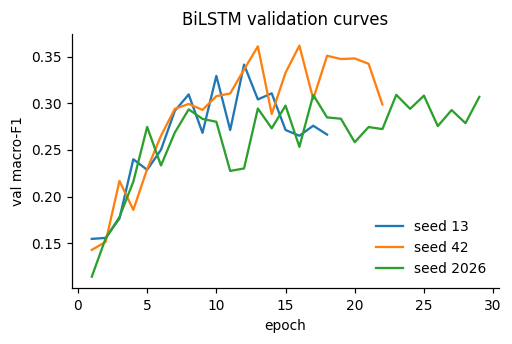

In [27]:
class Vocab:
    def __init__(self, texts, min_freq):
        c = Counter(t for s in texts for t in tokenize(s))
        self.itos = ["<pad>", "<unk>"] + sorted([t for t, n in c.items() if n >= min_freq])
        self.stoi = {t: i for i, t in enumerate(self.itos)}
    def encode(self, text, max_len):
        ids = [self.stoi.get(t, 1) for t in tokenize(text)][:max_len]
        return ids or [1]
    def __len__(self):
        return len(self.itos)

BILSTM_SRC = r'''
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class BiLSTMAttn(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden, n_classes, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.att_proj = nn.Linear(2 * hidden, 2 * hidden)
        self.att_v = nn.Linear(2 * hidden, 1, bias=False)
        self.drop = nn.Dropout(dropout)
        self.out = nn.Linear(2 * hidden, n_classes)
    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=x.size(1))
        scores = self.att_v(torch.tanh(self.att_proj(h))).squeeze(-1).masked_fill(x == 0, -1e4)
        a = torch.softmax(scores, dim=-1)
        ctx = (a.unsqueeze(-1) * h).sum(1)
        return self.out(self.drop(ctx)), a
'''
exec(BILSTM_SRC)   # kept as a string so the exported app gets exactly this class

def _batches(ids, labels, bs, shuffle, gen=None):
    order = torch.randperm(len(ids), generator=gen).tolist() if shuffle else list(range(len(ids)))
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        seqs = [ids[j] for j in idx]; L = max(len(s) for s in seqs)
        x = torch.zeros(len(seqs), L, dtype=torch.long)
        for r, s in enumerate(seqs):
            x[r, :len(s)] = torch.tensor(s)
        lengths = torch.tensor([len(s) for s in seqs])
        yb = torch.tensor([labels[j] for j in idx]) if labels is not None else None
        yield x, lengths, yb

@torch.no_grad()
def bilstm_proba(model, vocab, texts, bs=128):
    model.eval(); ids = [vocab.encode(t, CFG["bilstm"]["max_len"]) for t in texts]; out = []
    for x, lengths, _ in _batches(ids, None, bs, False):
        logits, _ = model(x.to(DEVICE), lengths)
        out.append(torch.softmax(logits, -1).cpu().numpy())
    return np.concatenate(out) if out else np.zeros((0, K))

def train_bilstm(train_texts, train_y, val_texts, val_y, seed, class_weighting=True, cfg=None):
    cfg = cfg or CFG["bilstm"]; set_seed(seed)
    vocab = Vocab(train_texts, cfg["min_freq"])
    model = BiLSTMAttn(len(vocab), cfg["emb_dim"], cfg["hidden"], K, cfg["dropout"]).to(DEVICE)
    w = torch.tensor(class_weight_vector(np.asarray(train_y)), dtype=torch.float32, device=DEVICE) if class_weighting else None
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    tr_ids = [vocab.encode(t, cfg["max_len"]) for t in train_texts]
    gen = torch.Generator().manual_seed(seed)
    best, best_state, best_ep, bad, hist = -1, None, 0, 0, []
    t0 = time.time()
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); tot = 0
        for x, lengths, yb in _batches(tr_ids, list(train_y), cfg["batch_size"], True, gen):
            opt.zero_grad()
            logits, _ = model(x.to(DEVICE), lengths)
            loss = loss_fn(logits, yb.to(DEVICE)); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg["grad_clip"]); opt.step(); tot += loss.item()
        vf = macro_f1(np.asarray(val_y), bilstm_proba(model, vocab, val_texts).argmax(1))
        hist.append({"epoch": ep, "train_loss": tot, "val_macro_f1": vf})
        if vf > best:
            best, best_ep, bad = vf, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    return {"model": model, "vocab": vocab, "best_epoch": best_ep, "history": hist,
            "train_time_s": round(time.time() - t0, 1), "n_params": sum(p.numel() for p in model.parameters())}

BILSTM_HIST = {}
for seed in CFG["seeds"]:
    r = train_bilstm(TR[PCOL].tolist(), TR["y"].tolist(), VA[PCOL].tolist(), VA["y"].tolist(), seed)
    pv, pt = bilstm_proba(r["model"], r["vocab"], VA[PCOL].tolist()), bilstm_proba(r["model"], r["vocab"], TE[PCOL].tolist())
    rid = log_run("main", "bilstm", PRIMARY_VARIANT, seed, pv.argmax(1), pt.argmax(1), pv, pt,
                  extra={"best_epoch": r["best_epoch"], "train_time_s": r["train_time_s"], "n_params": r["n_params"]})
    MODEL_OBJECTS[rid] = ("bilstm", r["model"], r["vocab"]); BILSTM_HIST[seed] = r["history"]
display(show(experiment="main"))

fig, ax = plt.subplots(figsize=(5, 3))
for s, h in BILSTM_HIST.items():
    ax.plot([e["epoch"] for e in h], [e["val_macro_f1"] for e in h], label=f"seed {s}")
ax.set_xlabel("epoch"); ax.set_ylabel("val macro-F1"); ax.set_title("BiLSTM validation curves"); ax.legend(frameon=False)
savefig(fig, "bilstm_val_curves")

## 11. Level 3 - pretrained multilingual transformers
**Which models, and what they know about Dholuo.**
* `Davlan/afro-xlmr-large-114L` is XLM-R-large further trained with masked-language modelling on languages widely spoken in Africa; its model card lists Luo (`luo`) among them. It is not a Dholuo-specific model, and I make no assumption about how much Dholuo it saw.
* `FacebookAI/xlm-roberta-large` has the same architecture without the African adaptation; Luo is not among the 100 languages of its CC-100 pretraining corpus (Conneau et al., 2020).

The tokenizer table below shows that the two models share exactly the same 250,002-piece SentencePiece vocabulary and cut Dholuo words identically (1.7 subwords per word; *jopur* → *jo + pur*). Any difference between them therefore comes from what the encoder learned in pretraining, not from tokenization - which makes this a clean test of African-language adaptation.

**Fine-tuning a 560M-parameter model on 810 examples.** Large encoders trained on very little data are unstable, and some seeds collapse to predicting one or two classes. I guard against this with a low learning rate and warm-up, early stopping on validation macro-F1, three seeds, an automatic collapse flag, and two cheaper alternatives in Experiment G (LoRA adapters and a frozen encoder). To fit a 15 GB T4, full fine-tuning freezes the 250k-row input-embedding matrix (which also stops rare-word embeddings drifting on so little data) and uses gradient checkpointing; peak memory was 7.2 GB. The training loop is plain PyTorch, so its behaviour does not depend on changes in the `transformers` training API.

In [28]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, AutoModel

def load_tokenizer(name):
    return AutoTokenizer.from_pretrained(name)

def load_backbone(name, num_labels):
    return AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=num_labels, id2label={i: l for i, l in enumerate(LABELS)}, label2id=LABEL2ID)

def load_encoder(name):
    return AutoModel.from_pretrained(name)

In [ ]:
# Tokenizer fertility: how finely does each tokenizer cut Dholuo words? (cheap, no GPU)
def fertility(tok, texts):
    words = [w for s in texts for w in s.split() if re.match(r"^[\w']+$", w)]
    counts = Counter(words)
    pieces = {w: len(tok.tokenize(w)) for w in counts}
    n = sum(counts.values())
    return {"subwords_per_word": round(sum(pieces[w] * c for w, c in counts.items()) / n, 3),
            "share_words_split_3plus": round(sum(c for w, c in counts.items() if pieces[w] >= 3) / n, 3),
            "share_words_single_piece": round(sum(c for w, c in counts.items() if pieces[w] == 1) / n, 3)}

FERTILITY = {}
if CFG["run"]["transformers"]:
    for key, name in CFG["transformers"]["models"].items():
        try:
            _tok = load_tokenizer(name)
            FERTILITY[key] = dict(fertility(_tok, TR["text_normalized"].tolist()), vocab_size=len(_tok),
                                  example=" | ".join(" ".join(_tok.tokenize(w)) for w in ["jopur", "nyithindo", "mang'eny"]))
        except Exception as e:
            FERTILITY[key] = {"error": f"{type(e).__name__}: {e}"[:200]}
    display(pd.DataFrame(FERTILITY).T)
    json.dump(FERTILITY, open(OUT / "results" / "tokenizer_fertility.json", "w"), indent=2)

config.json:   0%|          | 0.00/731 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

,subwords_per_word,share_words_split_3plus,share_words_single_piece,vocab_size,example
afroxlmr_large_114L,1.7,0.125,0.448,250002,▁jo pur | ▁ny ithi ndo | ▁mang ' en y
xlmr_large,1.7,0.125,0.448,250002,▁jo pur | ▁ny ithi ndo | ▁mang ' en y


In [29]:
def _encode(tok, texts, max_len):
    enc = tok(list(texts), truncation=True, max_length=max_len)
    return [{"input_ids": ids, "attention_mask": m} for ids, m in zip(enc["input_ids"], enc["attention_mask"])]

def _loader(tok, feats, labels, bs, shuffle, seed=0):
    order = list(range(len(feats)))
    if shuffle:
        random.Random(seed).shuffle(order)
    else:
        order.sort(key=lambda i: len(feats[i]["input_ids"]))     # length-sorted for fast inference
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]
        batch = tok.pad([feats[j] for j in idx], return_tensors="pt")
        if labels is not None:
            batch["labels"] = torch.tensor([labels[j] for j in idx])
        yield idx, batch

@torch.no_grad()
def tf_proba(model, tok, texts, tcfg):
    model.eval(); feats = _encode(tok, texts, tcfg["max_len"]); out = np.zeros((len(feats), K))
    amp = tcfg["fp16"] and DEVICE.type == "cuda"
    for idx, batch in _loader(tok, feats, None, tcfg["eval_batch_size"], False):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
            logits = model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE)).logits
        out[idx] = torch.softmax(logits.float(), -1).cpu().numpy()
    return out

def train_transformer(model_key, train, val, text_col, seed, strategy="full", class_weighting=True, save_dir=None, **overrides):
    tcfg = dict(CFG["transformers"], **overrides); name = tcfg["models"][model_key]
    set_seed(seed)
    tok = load_tokenizer(name)
    model = load_backbone(name, K)
    if strategy == "lora":
        from peft import LoraConfig, get_peft_model, TaskType
        lc = tcfg["lora"]
        model = get_peft_model(model, LoraConfig(task_type=TaskType.SEQ_CLS, r=lc["r"], lora_alpha=lc["alpha"],
                                                 lora_dropout=lc["dropout"], target_modules=lc["target_modules"]))
    if strategy == "full":
        if tcfg["freeze_embeddings"]:
            model.get_input_embeddings().weight.requires_grad_(False)
        if tcfg["gradient_checkpointing"] and DEVICE.type == "cuda":
            # non-reentrant checkpointing: gradients still reach every layer even though the embedding output
            # no longer requires grad (with the old reentrant mode the encoder would silently stop training)
            model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
            model.config.use_cache = False
    model.to(DEVICE)
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    tr_feats = _encode(tok, train[text_col], tcfg["max_len"]); tr_y = train["y"].tolist()
    w = torch.tensor(class_weight_vector(np.asarray(tr_y)), dtype=torch.float32, device=DEVICE) if class_weighting else None
    loss_fn = nn.CrossEntropyLoss(weight=w)
    lr = tcfg["lr_lora"] if strategy == "lora" else tcfg["lr_full"]
    decay, no_decay = [], []
    for n_, p in model.named_parameters():
        if p.requires_grad:
            (no_decay if (n_.endswith("bias") or "LayerNorm" in n_ or "layer_norm" in n_) else decay).append(p)
    opt = torch.optim.AdamW([{"params": decay, "weight_decay": tcfg["weight_decay"]},
                             {"params": no_decay, "weight_decay": 0.0}], lr=lr)
    steps_per_epoch = math.ceil(len(tr_feats) / (tcfg["batch_size"] * tcfg["grad_accum"]))
    total = steps_per_epoch * tcfg["epochs"]; warm = int(tcfg["warmup_ratio"] * total)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / max(1, warm) if s < warm
                                              else max(0.0, (total - s) / max(1, total - warm)))
    amp = tcfg["fp16"] and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    best, best_state, best_ep, bad, hist, t0 = -1, None, 0, 0, [], time.time()
    for ep in range(1, tcfg["epochs"] + 1):
        model.train(); opt.zero_grad(); tot = 0.0
        for step, (_, batch) in enumerate(_loader(tok, tr_feats, tr_y, tcfg["batch_size"], True, seed * 1000 + ep), 1):
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
                logits = model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE)).logits
            loss = loss_fn(logits.float(), batch["labels"].to(DEVICE)) / tcfg["grad_accum"]
            scaler.scale(loss).backward(); tot += loss.item()
            if step % tcfg["grad_accum"] == 0 or step * tcfg["batch_size"] >= len(tr_feats):
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], tcfg["grad_clip"])
                scale_before = scaler.get_scale() if amp else 1.0
                scaler.step(opt); scaler.update(); opt.zero_grad()
                if not amp or scaler.get_scale() >= scale_before:   # skipped (inf/nan) fp16 steps don't advance the schedule
                    sched.step()
        vp = tf_proba(model, tok, val[text_col].tolist(), tcfg).argmax(1)
        vf = macro_f1(val["y"].to_numpy(), vp)
        hist.append({"epoch": ep, "train_loss": tot, "val_macro_f1": vf, "val_pred_classes": int(len(np.unique(vp)))})
        print(f"  [{model_key}/{strategy}/seed {seed}] epoch {ep}: loss {tot:.3f}  val macro-F1 {vf:.4f}  ({time.time()-t0:.0f}s)")
        if vf > best:
            best, best_ep, bad = vf, ep, 0
            best_state = {k: v.detach().to("cpu", copy=True) for k, v in model.state_dict().items()
                          if strategy == "full" or "lora_" in k or "classifier" in k or "modules_to_save" in k}
        else:
            bad += 1
            if bad >= tcfg["patience"]:
                break
    model.load_state_dict(best_state, strict=False)
    info = {"best_epoch": best_ep, "train_time_s": round(time.time() - t0, 1), "n_trainable": int(n_trainable),
            "batch_size_used": tcfg["batch_size"], "grad_accum_used": tcfg["grad_accum"],
            "n_params": int(n_total), "peak_gpu_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE.type == "cuda" else None,
            "history": hist}
    if save_dir is not None:
        save_dir = Path(save_dir); save_dir.mkdir(parents=True, exist_ok=True)
        model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
        json.dump({"base_model": name, "strategy": strategy, "labels": LABELS, "text_variant": text_col},
                  open(save_dir / "run_info.json", "w"))
    return model, tok, info

def free(*objs):
    for o in objs:
        try:
            o.to("cpu")
        except Exception:
            pass
    del objs
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def prune_run_dirs(model_name):
    """Keep only the best-validation run directory of a model (disk budget); others are deleted."""
    r = runs_df()
    r = r[(r["model"] == model_name) & r["run_id"].isin(list(RUN_DIRS))]
    if len(r) <= 1:
        return
    keep_id = r.sort_values("val_macro_f1", ascending=False)["run_id"].iloc[0]
    for rid in r["run_id"]:
        if rid != keep_id:
            shutil.rmtree(RUN_DIRS.pop(rid), ignore_errors=True)

def run_transformer(experiment, model_key, strategy, seed, train=None, text_col=None, class_weighting=True, save=True, tag=None,
                    extra_fields=None):
    train = TR if train is None else train; text_col = text_col or PCOL
    run_name = f"{experiment}_{strategy}_{model_key}_{seed}" + (f"_{tag}" if tag else "")
    sd = PRIVATE / "runs" / run_name if save else None
    bs, acc = CFG["transformers"]["batch_size"], CFG["transformers"]["grad_accum"]
    for attempt in range(CFG["transformers"]["oom_retries"] + 1):
        try:
            model, tok, info = train_transformer(model_key, train, VA, text_col, seed, strategy, class_weighting, sd,
                                                 batch_size=bs, grad_accum=acc)
            break
        except torch.cuda.OutOfMemoryError:
            model = None; gc.collect(); torch.cuda.empty_cache()
            if attempt == CFG["transformers"]["oom_retries"] or bs == 1:
                raise
            bs, acc = max(1, bs // 2), acc * 2
            print(f"  CUDA OOM -> retrying with batch_size={bs}, grad_accum={acc} (same effective batch)")
    tcfg = CFG["transformers"]
    pv = tf_proba(model, tok, VA[text_col].tolist(), tcfg); pt = tf_proba(model, tok, TE[text_col].tolist(), tcfg)
    variant = [k for k, v in TEXT_COL.items() if v == text_col][0]
    hist = info.pop("history")
    extra = dict(info, strategy=strategy, n_train=len(train), class_weighting=class_weighting,
                 collapsed=bool(len(np.unique(pv.argmax(1))) <= 2), tag=tag, **(extra_fields or {}))
    rid = log_run(experiment, f"{strategy}_{model_key}", variant, seed, pv.argmax(1), pt.argmax(1), pv, pt, extra=extra)
    if sd is not None:
        RUN_DIRS[rid] = sd
    free(model)
    return rid, hist

### 11.1 Full fine-tuning, three seeds per model
Full fine-tuning of AfroXLMR works and is stable across seeds: test macro-F1 0.394, 0.391 and 0.427 (mean 0.404), close to the TF-IDF models. XLM-R, with the same architecture and settings, never learns the task: its validation macro-F1 stays below 0.05 in every epoch, and its three seeds reach only 0.041, 0.090 and 0.007 on test (mean 0.046), around the level of the stratified random baseline (0.035). None of the runs trips the automatic collapse flag, but none learns anything useful either. The only difference between the two models is African-language pretraining, and it decides whether fine-tuning works at all on this amount of data.

In [30]:
TF_HIST = {}
if CFG["run"]["transformers"]:
    keys = [CFG["transformers"]["primary"]] + ([k for k in CFG["transformers"]["models"] if k != CFG["transformers"]["primary"]]
                                               if CFG["run"]["xlmr_comparison"] else [])
    for key in keys:
        for seed in CFG["seeds"]:
            rid, hist = run_transformer("main", key, "full", seed)
            TF_HIST[rid] = hist
            prune_run_dirs(f"full_{key}")
    display(show(["collapsed", "best_epoch", "train_time_s", "peak_gpu_gb"], experiment="main"))

config.json:   0%|          | 0.00/731 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [xlmr_large/full/seed 2026] epoch 1: loss 162.963  val macro-F1 0.0052  (31s)
  [xlmr_large/full/seed 2026] epoch 2: loss 161.770  val macro-F1 0.0052  (64s)
  [xlmr_large/full/seed 2026] epoch 3: loss 161.890  val macro-F1 0.0056  (97s)
  [xlmr_large/full/seed 2026] epoch 4: loss 161.188  val macro-F1 0.0048  (131s)
  [xlmr_large/full/seed 2026] epoch 5: loss 160.850  val macro-F1 0.0113  (165s)
  [xlmr_large/full/seed 2026] epoch 6: loss 161.007  val macro-F1 0.0068  (199s)
  [xlmr_large/full/seed 2026] epoch 7: loss 161.252  val macro-F1 0.0052  (233s)
  [xlmr_large/full/seed 2026] epoch 8: loss 161.014  val macro-F1 0.0056  (267s)
  [xlmr_large/full/seed 2026] epoch 9: loss 160.919  val macro-F1 0.0040  (301s)
  [xlmr_large/full/seed 2026] epoch 10: loss 160.532  val macro-F1 0.0040  (335s)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,model,variant,seed,val_macro_f1,test_macro_f1,test_acc,test_weighted_f1,collapsed,best_epoch,train_time_s,peak_gpu_gb
0,dummy_most_frequent,-,0,0.0052,0.0046,0.056,0.0059,NaN,NaN,NaN,NaN
1,dummy_stratified,-,0,0.0386,0.0354,0.048,0.0432,NaN,NaN,NaN,NaN
5,lr_word,normalized,0,0.4271,0.3957,0.424,0.4087,NaN,NaN,37.3,NaN
6,lr_char,normalized,0,0.4225,0.3705,0.408,0.3730,NaN,NaN,20.0,NaN
7,svm_wordchar,normalized,0,0.4324,0.4129,0.448,0.4144,NaN,NaN,5.6,NaN
8,bilstm,normalized,13,0.3414,0.3310,0.356,0.3390,NaN,12.0,13.0,NaN
9,bilstm,normalized,42,0.3617,0.2890,0.332,0.3122,NaN,16.0,13.1,NaN
10,bilstm,normalized,2026,0.3090,0.2998,0.328,0.3037,NaN,23.0,17.6,NaN
11,full_afroxlmr_large_114L,normalized,13,0.3447,0.3942,0.416,0.4065,False,13.0,622.7,7.15
12,full_afroxlmr_large_114L,normalized,42,0.3651,0.3912,0.416,0.4083,False,12.0,590.5,7.15


### 11.2 Experiment G - which fine-tuning strategy gives the best performance for the compute?
All three strategies use the same AfroXLMR backbone, text and split:
* **Frozen encoder:** average the final hidden states and train only a logistic-regression head (23,575 trainable parameters). Test macro-F1 **0.227**: the general-purpose representation is not enough on its own.
* **LoRA:** freeze the encoder and train rank-16 adapters on the attention query and value matrices plus the classification head (2.6M trainable parameters, under 0.5% of the model). Test macro-F1 **0.416 ± 0.005** (seeds 0.417, 0.410, 0.420), using 4.5 GB of GPU memory and about 6 minutes per run.
* **Full fine-tuning:** update everything except the embedding matrix (304M trainable parameters). Test macro-F1 **0.404 ± 0.020**, using 7.2 GB and about 10 minutes per run.

LoRA gives the best and the most stable result with roughly 60% of the training time and memory of full fine-tuning. It is also the best transformer on validation (0.430 against 0.360 for full fine-tuning). A likely reason is that updating 2.6M rather than 304M parameters leaves far less room to overfit 810 examples.

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: Davlan/afro-xlmr-large-114L
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large-114L
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [afroxlmr_large_114L/lora/seed 13] epoch 1: loss 162.956  val macro-F1 0.0205  (16s)
  [afroxlmr_large_114L/lora/seed 13] epoch 2: loss 160.683  val macro-F1 0.0299  (32s)
  [afroxlmr_large_114L/lora/seed 13] epoch 3: loss 156.834  val macro-F1 0.0493  (48s)
  [afroxlmr_large_114L/lora/seed 13] epoch 4: loss 144.257  val macro-F1 0.1969  (64s)
  [afroxlmr_large_114L/lora/seed 13] epoch 5: loss 122.589  val macro-F1 0.2448  (80s)
  [afroxlmr_large_114L/lora/seed 13] epoch 6: loss 104.710  val macro-F1 0.2905  (97s)
  [afroxlmr_large_114L/lora/seed 13] epoch 7: loss 90.836  val macro-F1 0.3466  (114s)
  [afroxlmr_large_114L/lora/seed 13] epoch 8: loss 82.230  val macro-F1 0.3738  (131s)
  [afroxlmr_large_114L/lora/seed 13] epoch 9: loss 71.105  val macro-F1 0.3860  (147s)
  [afroxlmr_large_114L/lora/seed 13] epoch 10: loss 66.963  val macro-F1 0.3899  (164s)
  [afroxlmr_large_114L/lora/seed 13] epoch 11: loss 61.213  val macro-F1 0.3401  (181s)
  [afroxlmr_large_114L/lora/seed 13] epoc

...

  [afroxlmr_large_114L/lora/seed 42] epoch 1: loss 161.906  val macro-F1 0.0221  (17s)
  [afroxlmr_large_114L/lora/seed 42] epoch 2: loss 159.564  val macro-F1 0.0343  (35s)
  [afroxlmr_large_114L/lora/seed 42] epoch 3: loss 151.963  val macro-F1 0.0402  (52s)
  [afroxlmr_large_114L/lora/seed 42] epoch 4: loss 135.530  val macro-F1 0.2396  (70s)
  [afroxlmr_large_114L/lora/seed 42] epoch 5: loss 114.437  val macro-F1 0.2701  (87s)
  [afroxlmr_large_114L/lora/seed 42] epoch 6: loss 97.545  val macro-F1 0.2929  (105s)
  [afroxlmr_large_114L/lora/seed 42] epoch 7: loss 84.320  val macro-F1 0.3018  (122s)
  [afroxlmr_large_114L/lora/seed 42] epoch 8: loss 75.292  val macro-F1 0.3293  (139s)
  [afroxlmr_large_114L/lora/seed 42] epoch 9: loss 67.182  val macro-F1 0.4004  (157s)
  [afroxlmr_large_114L/lora/seed 42] epoch 10: loss 61.260  val macro-F1 0.3743  (175s)
  [afroxlmr_large_114L/lora/seed 42] epoch 11: loss 52.450  val macro-F1 0.3907  (192s)
  [afroxlmr_large_114L/lora/seed 42] epoc

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large-114L
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [afroxlmr_large_114L/lora/seed 2026] epoch 1: loss 162.374  val macro-F1 0.0135  (17s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 2: loss 160.322  val macro-F1 0.0287  (35s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 3: loss 155.530  val macro-F1 0.0699  (52s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 4: loss 148.333  val macro-F1 0.1130  (69s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 5: loss 126.793  val macro-F1 0.2530  (87s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 6: loss 106.322  val macro-F1 0.3114  (104s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 7: loss 94.364  val macro-F1 0.3686  (122s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 8: loss 81.180  val macro-F1 0.3046  (139s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 9: loss 73.712  val macro-F1 0.3912  (157s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 10: loss 66.988  val macro-F1 0.3827  (174s)
  [afroxlmr_large_114L/lora/seed 2026] epoch 11: loss 64.454  val macro-F1 0.4060  (191s)
  [afroxlmr_large_

,val_f1,val_f1_sd,test_f1,test_f1_sd,trainable_params,train_time_s,peak_gpu_gb,runs
model,,,,,,,,
frozen_afroxlmr_large_114L,0.2904,NaN,0.2273,NaN,23575.0,58.9000,NaN,1
full_afroxlmr_large_114L,0.3604,0.0140,0.4041,0.0199,303911959.0,577.1667,7.15,3
lora_afroxlmr_large_114L,0.4301,0.0177,0.4155,0.0051,2646039.0,346.0333,4.51,3


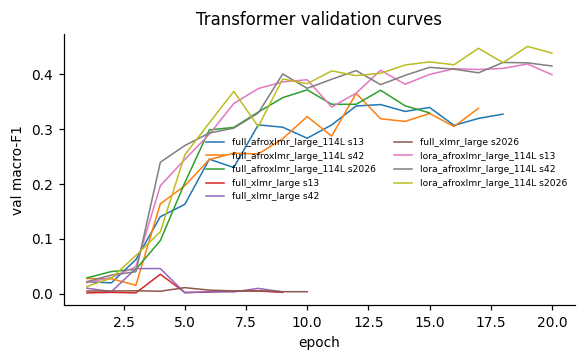

In [35]:
import sys
# Forcefully remove torchao from the active Python session's module cache to prevent PEFT from crashing
for mod in list(sys.modules.keys()):
    if mod.startswith("torchao"):
        sys.modules.pop(mod, None)

# Mask package distribution metadata to ensure importlib/pkg_resources checks for torchao also fail gracefully
try:
    import sys, importlib.metadata
    sys.modules['torchao'] = None
    # Prevent importlib.metadata from finding torchao metadata
    _orig_metadata = importlib.metadata.metadata
    def _patched_metadata(distribution_name):
        if "torchao" in distribution_name.lower():
            raise importlib.metadata.PackageNotFoundError(distribution_name)
        return _orig_metadata(distribution_name)
    importlib.metadata.metadata = _patched_metadata
except Exception:
    pass

_ENCODERS = {}
def get_encoder(name):
    if name not in _ENCODERS:
        _ENCODERS.clear(); gc.collect()
        _ENCODERS[name] = (load_tokenizer(name), load_encoder(name).to(DEVICE).eval())
    return _ENCODERS[name]

@torch.no_grad()
def embed_texts(name, texts, tcfg):
    tok, enc_model = get_encoder(name)
    feats = _encode(tok, texts, tcfg["max_len"]); out = np.zeros((len(feats), enc_model.config.hidden_size), dtype=np.float32)
    amp = tcfg["fp16"] and DEVICE.type == "cuda"
    for idx, batch in _loader(tok, feats, None, tcfg["eval_batch_size"], False):
        m = batch["attention_mask"].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp):
            h = enc_model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=m).last_hidden_state.float()
        out[idx] = ((h * m.unsqueeze(-1)).sum(1) / m.sum(1, keepdim=True)).cpu().numpy()
    return out

if CFG["run"]["transformers"] and CFG["run"]["frozen"]:
    key = CFG["transformers"]["primary"]; name = CFG["transformers"]["models"][key]; tcfg = CFG["transformers"]
    t0 = time.time()
    E = {s: embed_texts(name, part[PCOL].tolist(), tcfg) for s, part in [("train", TR), ("val", VA), ("test", TE)]}
    best = None
    for C in [0.01, 0.1, 1, 10]:
        lr = LogisticRegression(C=C, max_iter=5000, class_weight=cw_main).fit(E["train"], Y["train"])
        f = macro_f1(Y["val"], lr.predict(E["val"]))
        if best is None or f > best[0]:
            best = (f, C, lr)
    _, C, lr = best
    pv = np.zeros((len(VA), K)); pv[:, lr.classes_] = lr.predict_proba(E["val"])
    pt = np.zeros((len(TE), K)); pt[:, lr.classes_] = lr.predict_proba(E["test"])
    rid = log_run("main", f"frozen_{key}", PRIMARY_VARIANT, 0, pv.argmax(1), pt.argmax(1), pv, pt,
                  extra={"strategy": "frozen", "params": json.dumps({"C": C}), "train_time_s": round(time.time() - t0, 1),
                         "n_trainable": int(lr.coef_.size + lr.intercept_.size)})
    MODEL_OBJECTS[rid] = ("frozen", name, lr)
    if CFG["run"]["lora"] or CFG["run"]["transformer_learning_curve"]:
        _ENCODERS.clear(); gc.collect(); torch.cuda.empty_cache()   # free GPU for further fine-tuning

if CFG["run"]["transformers"] and CFG["run"]["lora"]:
    for seed in CFG["seeds"]:
        rid, hist = run_transformer("main", CFG["transformers"]["primary"], "lora", seed)
        TF_HIST[rid] = hist
        prune_run_dirs(f"lora_{CFG['transformers']['primary']}")

if CFG["run"]["transformers"]:
    g = runs_df()
    g = g[(g["experiment"] == "main") & g["model"].str.contains(CFG["transformers"]["primary"])]
    EXP_G = g.groupby("model").agg(val_f1=("val_macro_f1", "mean"), val_f1_sd=("val_macro_f1", "std"),
                                   test_f1=("test_macro_f1", "mean"), test_f1_sd=("test_macro_f1", "std"),
                                   trainable_params=("n_trainable", "first"), train_time_s=("train_time_s", "mean"),
                                   peak_gpu_gb=("peak_gpu_gb", "max"), runs=("seed", "size")).round(4)
    display(EXP_G); EXP_G.to_csv(OUT / "results" / "exp_G_finetuning_strategy.csv")

if TF_HIST:
    fig, ax = plt.subplots(figsize=(6, 3.2))
    for rid, h in TF_HIST.items():
        ax.plot([e["epoch"] for e in h], [e["val_macro_f1"] for e in h], label=rid.split("|")[1] + " s" + rid.split("|")[3], lw=1)
    ax.set_xlabel("epoch"); ax.set_ylabel("val macro-F1"); ax.set_title("Transformer validation curves")
    ax.legend(fontsize=6, frameon=False, ncol=2)
    savefig(fig, "transformer_val_curves")

### 11.3 Model summary - architecture, input, output and parameters
| Model | Input | Representation | Architecture | Output | Training |
|---|---|---|---|---|---|
| Majority / stratified | - | - | constant class, or random by class frequency | class | none |
| TF-IDF + logistic regression | normalised transcript | sparse TF-IDF of word 1–2-grams or character 2–5-grams | multinomial logistic regression, L2, class-weighted | probabilities over 23 classes | L-BFGS; C chosen on validation |
| TF-IDF + SVM | same | word and character TF-IDF combined | one-vs-rest linear SVM | margins turned into probabilities by a temperature fitted on validation | liblinear; C chosen on validation |
| BiLSTM + attention | word tokens (training vocabulary, frequency ≥ 2) | 128-d embeddings learned from scratch | one BiLSTM layer (2×128) → additive attention → dropout → linear | softmax | AdamW, weighted cross-entropy, early stopping |
| AfroXLMR / XLM-R, full | SentencePiece subwords (up to 256) | pretrained 1024-d contextual embeddings | 24-layer Transformer encoder, 16 heads → `<s>` token → dense + tanh → linear | softmax | all layers except input embeddings updated; AdamW with warm-up and linear decay; fp16; gradient checkpointing |
| LoRA | same | same | frozen encoder with rank-16 adapters on attention query/value, trainable head | softmax | only adapters and head updated |
| Frozen encoder | same | mean of final hidden states | frozen encoder → logistic regression | softmax | encoder not trained |

The computed table below gives the actual parameter counts, training times and GPU memory for each model, followed by the configurations of the two pretrained checkpoints.

In [36]:
_r = runs_df()
for _c in ["n_params", "n_trainable", "train_time_s", "peak_gpu_gb"]:
    if _c not in _r:
        _r[_c] = np.nan
summ = _r.query("experiment == 'main'").groupby("model").agg(
    runs=("seed", "size"), total_params=("n_params", "max"), trainable_params=("n_trainable", "max"),
    mean_train_time_s=("train_time_s", "mean"), peak_gpu_gb=("peak_gpu_gb", "max")).reset_index()
cfg_rows = []
for key, name in CFG["transformers"]["models"].items():
    try:
        from transformers import AutoConfig
        c = AutoConfig.from_pretrained(name)
        cfg_rows.append({"checkpoint": name, "layers": c.num_hidden_layers, "hidden": c.hidden_size,
                         "heads": c.num_attention_heads, "vocab": c.vocab_size, "max_positions": c.max_position_embeddings})
    except Exception as e:
        cfg_rows.append({"checkpoint": name, "note": f"config unavailable ({type(e).__name__})"})
MODEL_SUMMARY = summ
display(summ.round(1)); display(pd.DataFrame(cfg_rows))
summ.to_csv(OUT / "results" / "model_summary.csv", index=False)
pd.DataFrame(cfg_rows).to_csv(OUT / "results" / "transformer_configs.csv", index=False)

,model,runs,total_params,trainable_params,mean_train_time_s,peak_gpu_gb
0,bilstm,3,563095.0,NaN,14.6,NaN
1,dummy_most_frequent,1,NaN,NaN,NaN,NaN
2,dummy_stratified,1,NaN,NaN,NaN,NaN
3,frozen_afroxlmr_large_114L,1,NaN,23575.0,58.9,NaN
4,full_afroxlmr_large_114L,3,559914007.0,303911959.0,577.2,7.2
5,full_xlmr_large,3,559914007.0,303911959.0,312.8,7.2
6,lora_afroxlmr_large_114L,3,562560046.0,2646039.0,346.0,4.5
7,lr_char,1,NaN,NaN,20.0,NaN
8,lr_word,1,NaN,NaN,37.3,NaN
9,svm_wordchar,1,NaN,NaN,5.6,NaN


,checkpoint,layers,hidden,heads,vocab,max_positions
0,Davlan/afro-xlmr-large-114L,24,1024,16,250002,514
1,FacebookAI/xlm-roberta-large,24,1024,16,250002,514


## 12. Experiment C - does more sophisticated modelling pay off? Choosing the final model
**The selection rule was fixed before looking at test scores:** rank models by mean validation macro-F1; among those within one standard deviation of the best, choose the least complex (majority < logistic regression < SVM < BiLSTM < frozen encoder < LoRA < full fine-tuning). The brief asks me to prefer simple models when they perform competitively, and this rule puts that into practice.

**What happened.** The TF-IDF + linear SVM is best on validation (0.432). Because the SVM is deterministic, it has a single run and a standard deviation of zero, so the one-standard-deviation band around it contains no other model and the rule selects the **SVM**, which is the deployed model. The runners-up are very close: LoRA AfroXLMR 0.430 ± 0.018, word-level logistic regression 0.427 and character-level logistic regression 0.423. The SVM is also the second-simplest model in the ranking, so the choice is consistent with the spirit of the rule.

**What the test set says.** LoRA has the best *mean* test score over its three seeds (0.416 ± 0.005), but it is statistically tied with the SVM (SVM minus LoRA: −0.007, interval −0.074 to +0.056). The SVM is also tied with word-level logistic regression (+0.017, interval −0.031 to +0.061) and with full AfroXLMR fine-tuning (−0.014, interval −0.073 to +0.041). It is significantly better than character-level logistic regression (+0.042, interval +0.006 to +0.076), the BiLSTM (+0.124), the frozen encoder (+0.186) and XLM-R (+0.323). In short, **on 810 training examples the strongest pretrained model matches but does not beat a well-tuned linear model, which is smaller, faster and easier to deploy and explain.**

A note on reading the table: the mean columns average all seeds, while the confidence-interval columns describe the single best-validation run of each model, which is the run that would be deployed. For models with several seeds the two can differ; for XLM-R, for example, the mean (0.046) covers all three seeds while the interval belongs to its best-validation seed, which scored 0.090.

In [37]:
def complexity(model):
    if model.startswith("dummy"): return 0
    if model.startswith("lr_"): return 1
    if model.startswith("svm"): return 2
    if model == "bilstm": return 3
    if model.startswith("frozen"): return 4
    if model.startswith("lora"): return 5
    return 6

main = runs_df().query("experiment == 'main'")
EXP_C = main.groupby("model").agg(
    runs=("seed", "size"), val_macro_f1=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
    test_macro_f1=("test_macro_f1", "mean"), test_sd=("test_macro_f1", "std"),
    test_acc=("test_acc", "mean"), test_macro_p=("test_macro_p", "mean"), test_macro_r=("test_macro_r", "mean"),
    test_weighted_f1=("test_weighted_f1", "mean")).fillna({"val_sd": 0, "test_sd": 0})
EXP_C["complexity"] = [complexity(m) for m in EXP_C.index]
EXP_C = EXP_C.sort_values("val_macro_f1", ascending=False)

cand = EXP_C[~EXP_C.index.str.startswith("dummy")]
best_model = cand.index[0]
threshold = cand.loc[best_model, "val_macro_f1"] - cand.loc[best_model, "val_sd"]
within = cand[cand["val_macro_f1"] >= threshold]
FINAL_MODEL = within.sort_values(["complexity", "val_macro_f1"], ascending=[True, False]).index[0]
FINAL_RUN = main[main["model"] == FINAL_MODEL].sort_values("val_macro_f1", ascending=False)["run_id"].iloc[0]
print(f"Best on validation: {best_model}  (threshold {threshold:.4f})")
print(f"Models within one SD of best: {list(within.index)}")
print(f"SELECTED FINAL MODEL: {FINAL_MODEL}  | deployed run: {FINAL_RUN}")

# test CIs for every main model (deployed/best-val run of each)
rows = []
for m in EXP_C.index:
    rid = main[main["model"] == m].sort_values("val_macro_f1", ascending=False)["run_id"].iloc[0]
    p = PREDS[rid]["test_pred"]
    lo, hi = bootstrap_ci(Y["test"], p, seed=CFG["seed"])
    slo, shi = bootstrap_ci(Y["test"], p, groups=TE["contributor_id"].to_numpy(), seed=CFG["seed"])
    rows.append({"model": m, "run": rid, "test_macro_f1": macro_f1(Y["test"], p), "row_boot_95ci": f"[{lo:.3f}, {hi:.3f}]",
                 "speaker_boot_95ci": f"[{slo:.3f}, {shi:.3f}]"})
CI_TABLE = pd.DataFrame(rows).set_index("model")
EXP_C = EXP_C.join(CI_TABLE[["row_boot_95ci", "speaker_boot_95ci"]])
display(EXP_C.round(4))
EXP_C.to_csv(OUT / "results" / "exp_C_model_family.csv")

# Paired comparison: final model vs the best classical model and vs the BiLSTM
cls_best = EXP_C[EXP_C.index.str.startswith(("lr_", "svm"))].index[0]
comparisons = {}
for other in [m for m in EXP_C.index if not m.startswith("dummy")]:
    if other == FINAL_MODEL or other not in EXP_C.index:
        continue
    o_rid = CI_TABLE.loc[other, "run"]
    comparisons[f"{FINAL_MODEL} - {other}"] = paired_bootstrap(Y["test"], PREDS[FINAL_RUN]["test_pred"], PREDS[o_rid]["test_pred"], seed=CFG["seed"])
display(pd.DataFrame(comparisons).T.round(4))
json.dump({"final_model": FINAL_MODEL, "final_run": FINAL_RUN, "best_val_model": best_model, "threshold": threshold,
           "within_one_sd": list(within.index), "paired_bootstrap": comparisons},
          open(OUT / "results" / "model_selection.json", "w"), indent=2)

Best on validation: svm_wordchar  (threshold 0.4324)
Models within one SD of best: ['svm_wordchar']
SELECTED FINAL MODEL: svm_wordchar  | deployed run: main|svm_wordchar|normalized|0


,runs,val_macro_f1,val_sd,test_macro_f1,test_sd,test_acc,test_macro_p,test_macro_r,test_weighted_f1,complexity,row_boot_95ci,speaker_boot_95ci
model,,,,,,,,,,,,
svm_wordchar,1,0.4324,0.0000,0.4129,0.0000,0.4480,0.4202,0.4674,0.4144,2,"[0.345, 0.459]","[0.367, 0.425]"
lora_afroxlmr_large_114L,3,0.4301,0.0177,0.4155,0.0051,0.4360,0.4203,0.4332,0.4198,5,"[0.352, 0.470]","[0.394, 0.454]"
lr_word,1,0.4271,0.0000,0.3957,0.0000,0.4240,0.4298,0.4240,0.4087,1,"[0.329, 0.442]","[0.375, 0.425]"
lr_char,1,0.4225,0.0000,0.3705,0.0000,0.4080,0.3736,0.4210,0.3730,1,"[0.306, 0.414]","[0.329, 0.396]"
full_afroxlmr_large_114L,3,0.3604,0.0140,0.4041,0.0199,0.4307,0.4147,0.4280,0.4172,6,"[0.362, 0.472]","[0.376, 0.453]"
bilstm,3,0.3374,0.0266,0.3066,0.0218,0.3387,0.3174,0.3328,0.3183,3,"[0.234, 0.331]","[0.258, 0.294]"
frozen_afroxlmr_large_114L,1,0.2904,0.0000,0.2273,0.0000,0.2560,0.2378,0.2428,0.2392,4,"[0.177, 0.266]","[0.178, 0.267]"
dummy_stratified,1,0.0386,0.0000,0.0354,0.0000,0.0480,0.0327,0.0409,0.0432,0,"[0.017, 0.055]","[0.023, 0.045]"
full_xlmr_large,3,0.0310,0.0179,0.0461,0.0421,0.0893,0.0653,0.0759,0.0546,6,"[0.055, 0.119]","[0.067, 0.103]"


,diff,ci_lo,ci_hi,p_a_better
svm_wordchar - lora_afroxlmr_large_114L,-0.0068,-0.0739,0.0562,0.4020
svm_wordchar - lr_word,0.0172,-0.0308,0.0606,0.7565
svm_wordchar - lr_char,0.0424,0.0055,0.0761,0.9885
svm_wordchar - full_afroxlmr_large_114L,-0.0141,-0.0733,0.0409,0.3090
svm_wordchar - bilstm,0.1240,0.0551,0.1867,0.9995
svm_wordchar - frozen_afroxlmr_large_114L,0.1856,0.1197,0.2435,1.0000
svm_wordchar - full_xlmr_large,0.3225,0.2549,0.3793,1.0000


## 13. The final model on the official test set
On the five unseen test speakers, the TF-IDF + linear SVM reaches **macro-F1 0.413 (95% interval 0.345–0.459; 0.367–0.425 when whole speakers are resampled), accuracy 0.448 and weighted F1 0.414**, against 0.432 macro-F1 on validation. The modest gap between validation and test suggests the selection did not overfit the validation speakers.

**Which topics work.** Topics with distinctive vocabulary are easy: poultry (F1 0.77), fish farming (0.74), livestock production (0.67) and animal feeding (0.67). Broad or overlapping topics are hard: farming methods and systems (0.00; none of its 12 test answers is recognised), value addition (0.13), climate resilience (0.13), access to government programmes (0.16, often predicted as agricultural education, which as a result has perfect recall but precision 0.41) and contemporary issues (0.24). The confusion matrix shows errors concentrated among neighbouring topics rather than spread at random.

**Confidence.** An SVM produces margins, not probabilities, so a single softmax temperature (0.080) was fitted on the validation speakers in §9 and saved with the model. On the test speakers the resulting confidences are reasonably calibrated: the average top-class confidence is 0.50 against an accuracy of 0.45 (expected calibration error 0.10), so they are slightly over-confident but usable. Temperature scaling never changes which topic is predicted.

,precision,recall,f1-score,support,train_support
Access to government programs and subsidies,0.333,0.105,0.160,19.000,52.0
Agricultural education,0.412,1.000,0.583,7.000,39.0
Animal feeding and nutrition,0.550,0.846,0.667,13.000,34.0
Automation and AI in farming,0.429,0.375,0.400,8.000,28.0
Climate resilience and adaptation strategies,0.250,0.091,0.133,11.000,29.0
Contemporary issues in Agriculture,0.500,0.154,0.235,13.000,43.0
Crop Yield and quality,0.250,0.500,0.333,4.000,19.0
"Distribution channels (local, regional, international)",0.227,0.455,0.303,11.000,28.0
Economic impact of agricultural practices,0.250,0.333,0.286,9.000,27.0
Effect of climate change on Agriculture,0.400,0.400,0.400,10.000,46.0


Validation: {'acc': 0.4894, 'macro_p': 0.4197, 'macro_r': 0.4753, 'macro_f1': 0.4324, 'weighted_f1': 0.4612}
Test:       {'acc': 0.448, 'macro_p': 0.4202, 'macro_r': 0.4674, 'macro_f1': 0.4129, 'weighted_f1': 0.4144}
Calibration on test: mean confidence 0.504 vs accuracy 0.448; ECE (10 bins) = 0.102


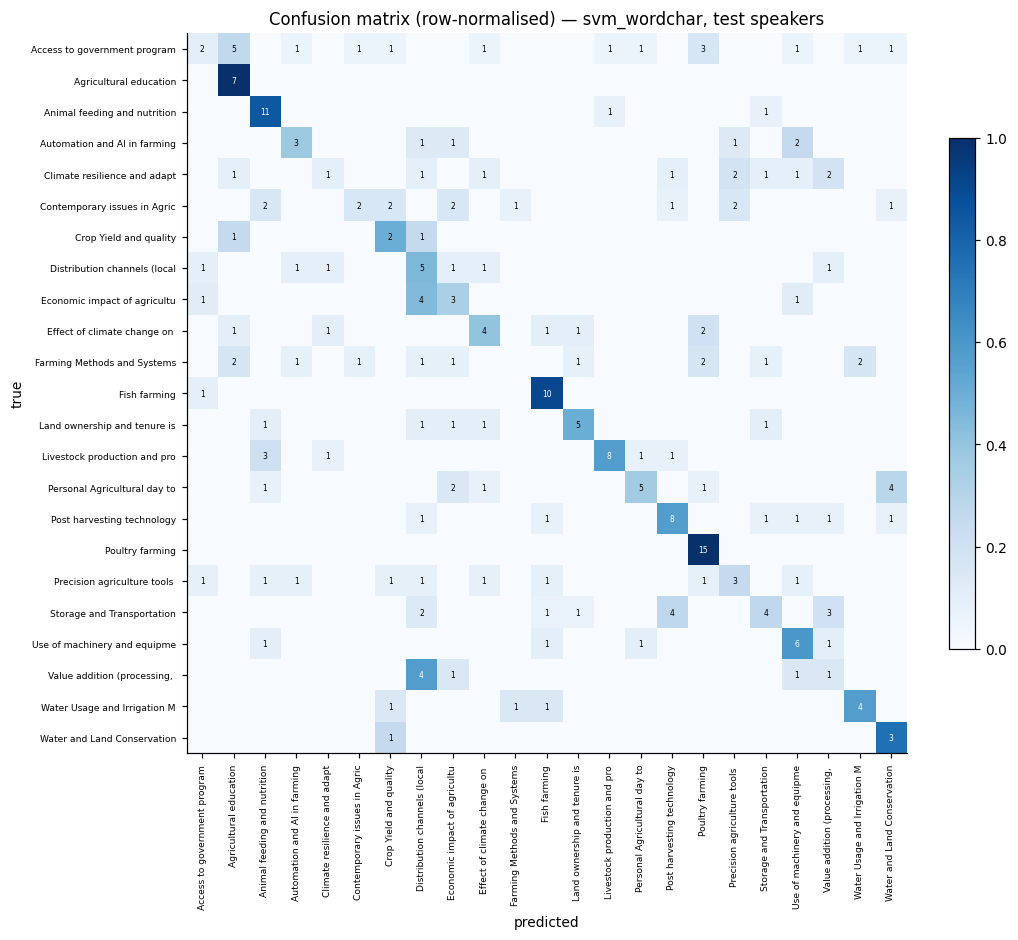

In [38]:
pt_final = PREDS[FINAL_RUN]["test_pred"]; pv_final = PREDS[FINAL_RUN]["val_pred"]
present = np.unique(Y["test"])
rep = pd.DataFrame(classification_report(Y["test"], pt_final, labels=present, target_names=[LABELS[i] for i in present],
                                         output_dict=True, zero_division=0)).T
rep["train_support"] = [int((Y["train"] == LABEL2ID[i]).sum()) if i in LABEL2ID else np.nan for i in rep.index]
display(rep.round(3))
rep.to_csv(OUT / "results" / "final_per_class.csv")
print("Validation:", {k: round(v, 4) for k, v in clf_metrics(Y["val"], pv_final).items()})
print("Test:      ", {k: round(v, 4) for k, v in clf_metrics(Y["test"], pt_final).items()})
if PREDS[FINAL_RUN]["test_proba"] is not None:
    _p = PREDS[FINAL_RUN]["test_proba"]; _c = _p.max(1); _ok = _p.argmax(1) == Y["test"]
    _bins = np.minimum((_c * 10).astype(int), 9)
    ECE = float(sum(abs(_ok[_bins == b].mean() - _c[_bins == b].mean()) * (_bins == b).mean() for b in range(10) if (_bins == b).any()))
    print(f"Calibration on test: mean confidence {_c.mean():.3f} vs accuracy {_ok.mean():.3f}; ECE (10 bins) = {ECE:.3f}")

cm = confusion_matrix(Y["test"], pt_final, labels=LABEL_IDS)
cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_yticks(range(K))
short = [l[:28] for l in LABELS]
ax.set_xticklabels(short, rotation=90, fontsize=6); ax.set_yticklabels(short, fontsize=6)
for i in range(K):
    for j in range(K):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=5, color="white" if cmn[i, j] > 0.5 else "black")
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Confusion matrix (row-normalised) — {FINAL_MODEL}, test speakers")
fig.colorbar(im, ax=ax, fraction=0.03)
savefig(fig, "final_confusion_matrix")
pd.DataFrame(cm, index=LABELS, columns=LABELS).to_csv(OUT / "results" / "final_confusion_matrix.csv")

pd.DataFrame({"file_name": TE["file_name"], "contributor_id": TE["contributor_id"], "gold": [LABELS[i] for i in Y["test"]],
              "pred": [LABELS[i] for i in pt_final],
              "confidence": PREDS[FINAL_RUN]["test_proba"].max(1) if PREDS[FINAL_RUN]["test_proba"] is not None else np.nan}
             ).to_csv(OUT / "results" / "final_test_predictions.csv", index=False)

## 14. Further experiments
### 14.1 Experiment A - how quickly do models improve with more training data?
Training rows are subsampled within each class at 10, 25, 50, 75 and 100%, keeping the validation and test speakers fixed. The classical model and the BiLSTM use all three seeds; the transformer uses one seed because of the GPU budget.

**Result.** All three models are still improving when the data runs out. Logistic regression is the most data-efficient: 0.217 with only 82 examples and 0.396 with all 810, with a last step of +0.027. The BiLSTM rises from 0.070 to 0.307 (last step +0.061). The transformer is useless with fewer than about 200 examples (0.04 at 82, 0.16 at 203) but climbs steeply after that, reaching 0.331 at 408 examples, levelling off at 607 (0.329) and rising again to 0.394 at 810; its last step is the largest of the three (+0.065). Because the transformer curve rests on one seed, its shape between points is noisy, but the overall trend suggests that with more Dholuo data the pretrained model would eventually pull ahead, while at this size the simple models are as good.

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large-114L
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [afroxlmr_large_114L/full/seed 13] epoch 1: loss 17.594  val macro-F1 0.0088  (4s)
  [afroxlmr_large_114L/full/seed 13] epoch 2: loss 17.534  val macro-F1 0.0026  (10s)
  [afroxlmr_large_114L/full/seed 13] epoch 3: loss 17.182  val macro-F1 0.0072  (14s)
  [afroxlmr_large_114L/full/seed 13] epoch 4: loss 16.663  val macro-F1 0.0166  (18s)
  [afroxlmr_large_114L/full/seed 13] epoch 5: loss 16.541  val macro-F1 0.0012  (24s)
  [afroxlmr_large_114L/full/seed 13] epoch 6: loss 16.249  val macro-F1 0.0219  (28s)
  [afroxlmr_large_114L/full/seed 13] epoch 7: loss 15.741  val macro-F1 0.0195  (33s)
  [afroxlmr_large_114L/full/seed 13] epoch 8: loss 15.147  val macro-F1 0.0277  (38s)
  [afroxlmr_large_114L/full/seed 13] epoch 9: loss 14.885  val macro-F1 0.0105  (43s)
  [afroxlmr_large_114L/full/seed 13] epoch 10: loss 14.586  val macro-F1 0.0145  (48s)
  [afroxlmr_large_114L/full/seed 13] epoch 11: loss 13.958  val macro-F1 0.0388  (53s)
  [afroxlmr_large_114L/full/seed 13] epoch 12: loss 1

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large-114L
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

  [afroxlmr_large_114L/full/seed 13] epoch 1: loss 81.813  val macro-F1 0.0175  (18s)
  [afroxlmr_large_114L/full/seed 13] epoch 2: loss 80.633  val macro-F1 0.0210  (36s)
  [afroxlmr_large_114L/full/seed 13] epoch 3: loss 78.874  val macro-F1 0.0182  (55s)
  [afroxlmr_large_114L/full/seed 13] epoch 4: loss 77.427  val macro-F1 0.0575  (73s)
  [afroxlmr_large_114L/full/seed 13] epoch 5: loss 71.963  val macro-F1 0.0997  (92s)
  [afroxlmr_large_114L/full/seed 13] epoch 6: loss 67.259  val macro-F1 0.1250  (110s)
  [afroxlmr_large_114L/full/seed 13] epoch 7: loss 60.034  val macro-F1 0.1556  (129s)
  [afroxlmr_large_114L/full/seed 13] epoch 8: loss 53.980  val macro-F1 0.1783  (148s)
  [afroxlmr_large_114L/full/seed 13] epoch 9: loss 46.348  val macro-F1 0.2582  (167s)
  [afroxlmr_large_114L/full/seed 13] epoch 10: loss 43.805  val macro-F1 0.2700  (186s)
  [afroxlmr_large_114L/full/seed 13] epoch 11: loss 38.156  val macro-F1 0.2686  (205s)
  [afroxlmr_large_114L/full/seed 13] epoch 12:

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-large-114L
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  [afroxlmr_large_114L/full/seed 13] epoch 1: loss 120.963  val macro-F1 0.0311  (25s)
  [afroxlmr_large_114L/full/seed 13] epoch 2: loss 119.572  val macro-F1 0.0345  (51s)
  [afroxlmr_large_114L/full/seed 13] epoch 3: loss 120.196  val macro-F1 0.0219  (79s)
  [afroxlmr_large_114L/full/seed 13] epoch 4: loss 116.513  val macro-F1 0.0379  (105s)
  [afroxlmr_large_114L/full/seed 13] epoch 5: loss 113.690  val macro-F1 0.0758  (132s)
  [afroxlmr_large_114L/full/seed 13] epoch 6: loss 104.620  val macro-F1 0.1583  (159s)
  [afroxlmr_large_114L/full/seed 13] epoch 7: loss 90.983  val macro-F1 0.2385  (186s)
  [afroxlmr_large_114L/full/seed 13] epoch 8: loss 77.156  val macro-F1 0.2578  (212s)
  [afroxlmr_large_114L/full/seed 13] epoch 9: loss 64.521  val macro-F1 0.3185  (239s)
  [afroxlmr_large_114L/full/seed 13] epoch 10: loss 53.386  val macro-F1 0.3628  (266s)
  [afroxlmr_large_114L/full/seed 13] epoch 11: loss 43.397  val macro-F1 0.3622  (293s)
  [afroxlmr_large_114L/full/seed 13] e

n_train  val_f1  val_sd  test_f1  test_sd
model                    frac                                           
bilstm                   0.10     82.0  0.0749  0.0295   0.0702   0.0119
                         0.25    203.0  0.1947  0.0283   0.1780   0.0208
                         0.50    408.0  0.2571  0.0247   0.2442   0.0234
                         0.75    607.0  0.2822  0.0274   0.2454   0.0359
                         1.00    810.0  0.3374  0.0266   0.3066   0.0218
full_afroxlmr_large_114L 0.10     82.0  0.0388     NaN   0.0393      NaN
                         0.25    203.0  0.1539     NaN   0.1551      NaN
                         0.50    408.0  0.3148     NaN   0.3312      NaN
                         0.75    607.0  0.3628     NaN   0.3294      NaN
                         1.00    810.0  0.3447     NaN   0.3942      NaN
lr_word                  0.10     82.0  0.2295  0.0292   0.2173   0.0234
                         0.25    203.0  0.2802  0.0332   0.2881   0.0214
                         0.50    408.0  0.3615  0.0192   0.3550   0.0382
                         0.75    607.0  0.3824  0.0144   0.3689   0.0079
                         1.00    810.0  0.4271  0.0000   0.3957   0.0000

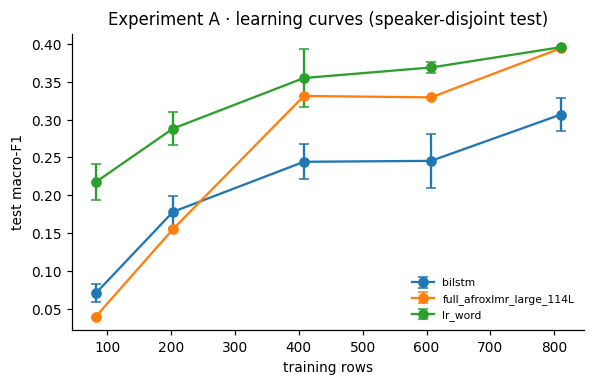

In [39]:
def subsample(frame, frac, seed):
    if frac >= 1:
        return frame
    r = np.random.default_rng(seed); idx = []
    for _, g in frame.groupby("y"):
        n = max(1, int(round(frac * len(g)))); idx += r.choice(g.index.to_numpy(), n, replace=False).tolist()
    return frame.loc[sorted(idx)]

lr_params = TUNED[("lr_word", PRIMARY_VARIANT)]
for frac in CFG["data_fractions"]:
    for seed in CFG["seeds"]:
        sub = subsample(TR, frac, seed)
        pipe = make_tfidf("lr_word", lr_params, cw_main).fit(sub[PCOL], sub["y"])
        log_run("A_data_size", "lr_word", PRIMARY_VARIANT, seed, pipe.predict(VA[PCOL]), pipe.predict(TE[PCOL]),
                extra={"frac": frac, "n_train": len(sub), "tag": f"f{frac}"})
        r = train_bilstm(sub[PCOL].tolist(), sub["y"].tolist(), VA[PCOL].tolist(), VA["y"].tolist(), seed)
        log_run("A_data_size", "bilstm", PRIMARY_VARIANT, seed,
                bilstm_proba(r["model"], r["vocab"], VA[PCOL].tolist()).argmax(1),
                bilstm_proba(r["model"], r["vocab"], TE[PCOL].tolist()).argmax(1),
                extra={"frac": frac, "n_train": len(sub), "tag": f"f{frac}"})
if CFG["run"]["transformers"] and CFG["run"]["transformer_learning_curve"]:
    seed = CFG["seeds"][0]
    for frac in [f for f in CFG["data_fractions"] if f < 1]:
        run_transformer("A_data_size", CFG["transformers"]["primary"], "full", seed, train=subsample(TR, frac, seed),
                        save=False, tag=f"f{frac}", extra_fields={"frac": frac})
    full_name = "full_" + CFG["transformers"]["primary"]
    full_run = runs_df().query("experiment == 'main' and model == @full_name and seed == @seed")
    if len(full_run):
        r0 = full_run.iloc[0].to_dict(); r0.update({"experiment": "A_data_size", "frac": 1.0, "n_train": len(TR),
                                                   "run_id": r0["run_id"] + "|copied_from_main"})
        RUNS.append(r0); pd.DataFrame(RUNS).to_csv(OUT / "results" / "all_runs.csv", index=False)

A = runs_df().query("experiment == 'A_data_size'")
EXP_A = A.groupby(["model", "frac"]).agg(n_train=("n_train", "mean"), val_f1=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
                                         test_f1=("test_macro_f1", "mean"), test_sd=("test_macro_f1", "std")).round(4)
display(EXP_A); EXP_A.to_csv(OUT / "results" / "exp_A_data_size.csv")
fig, ax = plt.subplots(figsize=(6, 3.5))
for m, g in EXP_A.reset_index().groupby("model"):
    ax.errorbar(g["n_train"], g["test_f1"], yerr=g["test_sd"].fillna(0), marker="o", capsize=3, label=m)
ax.set_xlabel("training rows"); ax.set_ylabel("test macro-F1"); ax.set_title("Experiment A · learning curves (speaker-disjoint test)")
ax.legend(frameon=False, fontsize=7)
savefig(fig, "exp_A_learning_curves")

### 14.2 Experiment B (continued) - does normalisation help the BiLSTM?
For a model that learns its own word embeddings, normalisation might matter more than for TF-IDF. It does not: the three text versions score 0.307–0.320 on test, a spread of 0.013 that is smaller than the seed-to-seed variation (about 0.02). For logistic regression the spread is just 0.005. **My conclusion is that careful normalisation neither helps nor harms on this data**, so removing or keeping the code-switch markers is a free choice; I keep the light `normalized` version because it makes the text consistent without discarding information.

In [40]:
for variant, col in TEXT_COL.items():
    for seed in CFG["seeds"]:
        r = train_bilstm(TR[col].tolist(), TR["y"].tolist(), VA[col].tolist(), VA["y"].tolist(), seed)
        log_run("B_preprocessing", "bilstm", variant, seed,
                bilstm_proba(r["model"], r["vocab"], VA[col].tolist()).argmax(1),
                bilstm_proba(r["model"], r["vocab"], TE[col].tolist()).argmax(1))
EXP_B = runs_df().query("experiment == 'B_preprocessing'").groupby(["model", "variant"]).agg(
    runs=("seed", "size"), val_f1=("val_macro_f1", "mean"), val_sd=("val_macro_f1", "std"),
    test_f1=("test_macro_f1", "mean"), test_sd=("test_macro_f1", "std")).round(4)
display(EXP_B); EXP_B.to_csv(OUT / "results" / "exp_B_preprocessing.csv")

runs  val_f1  val_sd  test_f1  test_sd
model   variant                                                  
bilstm  minimal               3  0.3032  0.0324   0.3074   0.0154
        normalized            3  0.3374  0.0266   0.3066   0.0218
        normalized_notags     3  0.3284  0.0154   0.3199   0.0242
lr_word minimal               1  0.4244     NaN   0.3918      NaN
        normalized            1  0.4271     NaN   0.3957      NaN
        normalized_notags     1  0.4230     NaN   0.3911      NaN

### 14.3 Ablation - does class weighting help?
This changes one thing only: whether the loss weights each class by the inverse of its frequency. The regularisation strength is re-tuned on validation for each setting so the comparison is fair. Weighting helps a little and consistently: logistic regression goes from 0.381 to 0.396 macro-F1 and from 0.400 to 0.424 macro-recall; the BiLSTM from 0.297 to 0.307 (within its seed noise). With a largest-to-smallest class ratio of only 3.3, the classes are not imbalanced enough for weighting to make a large difference, but it does help the rarer topics get predicted at all.

In [41]:
for seed in CFG["seeds"]:
    for cw in [True, False]:
        # C is re-tuned on validation for each setting, so the unweighted model is not stuck with C chosen for weighting
        pipe, abl_params = tune_and_fit("lr_word", TR, VA, TE, PCOL, "balanced" if cw else None)
        log_run("ablation_class_weight", "lr_word", PRIMARY_VARIANT, seed, pipe.predict(VA[PCOL]), pipe.predict(TE[PCOL]),
                extra={"class_weighting": cw, "params": json.dumps(abl_params), "tag": f"cw{int(cw)}"})
        r = train_bilstm(TR[PCOL].tolist(), TR["y"].tolist(), VA[PCOL].tolist(), VA["y"].tolist(), seed, class_weighting=cw)
        log_run("ablation_class_weight", "bilstm", PRIMARY_VARIANT, seed,
                bilstm_proba(r["model"], r["vocab"], VA[PCOL].tolist()).argmax(1),
                bilstm_proba(r["model"], r["vocab"], TE[PCOL].tolist()).argmax(1),
                extra={"class_weighting": cw, "tag": f"cw{int(cw)}"})
if CFG["run"]["transformers"] and CFG["run"]["transformer_class_weight_ablation"]:
    run_transformer("ablation_class_weight", CFG["transformers"]["primary"], "full", CFG["seeds"][0],
                    class_weighting=False, save=False, tag="cw0")
ABL = runs_df().query("experiment == 'ablation_class_weight'").groupby(["model", "class_weighting"]).agg(
    val_f1=("val_macro_f1", "mean"), test_f1=("test_macro_f1", "mean"), test_sd=("test_macro_f1", "std"),
    test_macro_r=("test_macro_r", "mean"), test_acc=("test_acc", "mean")).round(4)
display(ABL); ABL.to_csv(OUT / "results" / "ablation_class_weight.csv")

val_f1  test_f1  test_sd  test_macro_r  test_acc
model   class_weighting                                                  
bilstm  False            0.3277   0.2972   0.0280        0.3087    0.3320
        True             0.3374   0.3066   0.0218        0.3328    0.3387
lr_word False            0.3708   0.3809   0.0000        0.4001    0.4240
        True             0.4271   0.3957   0.0000        0.4240    0.4240

### 14.4 Experiment F - how much would a random split have flattered the results?
On the development speakers (training plus validation; the test speakers are untouched), I run the same models with five-fold cross-validation twice: once keeping each speaker's recordings in one fold, once splitting rows at random. **The random split overstates macro-F1 by 0.036 for logistic regression (0.404 vs 0.368) and by 0.020 for the BiLSTM (0.280 vs 0.259).** The effect is real but modest, consistent with the small difference in unseen-word rates seen in §7: speakers share a common agricultural vocabulary, so knowing a speaker helps but is not the main source of signal. Speaker-independent evaluation is still the honest choice, and the out-of-fold predictions from the speaker-grouped runs give every development speaker an unseen-speaker prediction for the subgroup analyses below.

In [42]:
def cv_eval(frame, splitter, groups=None, seed=0, models=("lr_word", "bilstm")):
    oof = {m: np.full(len(frame), -1) for m in models}; fold_scores = defaultdict(list)
    split_iter = splitter.split(frame, frame["y"], groups) if groups is not None else splitter.split(frame, frame["y"])
    for tr_i, ev_i in split_iter:
        tr, ev = frame.iloc[tr_i], frame.iloc[ev_i]
        if "lr_word" in models:
            p = make_tfidf("lr_word", lr_params, cw_main).fit(tr[PCOL], tr["y"]).predict(ev[PCOL])
            oof["lr_word"][ev_i] = p; fold_scores["lr_word"].append(macro_f1(ev["y"].to_numpy(), p))
        if "bilstm" in models:
            # early stopping needs held-out data: use 15% of the training speakers of this fold
            spk = tr["contributor_id"].unique() if groups is not None else None
            if spk is not None and len(spk) > 3:
                es_spk = np.random.default_rng(seed).choice(spk, max(1, int(round(0.15 * len(spk)))), replace=False)
                es_mask = tr["contributor_id"].isin(es_spk)
            else:
                es_mask = pd.Series(np.random.default_rng(seed).random(len(tr)) < 0.15, index=tr.index)
            fit, es = tr[~es_mask], tr[es_mask]
            r = train_bilstm(fit[PCOL].tolist(), fit["y"].tolist(), es[PCOL].tolist(), es["y"].tolist(), seed)
            p = bilstm_proba(r["model"], r["vocab"], ev[PCOL].tolist()).argmax(1)
            oof["bilstm"][ev_i] = p; fold_scores["bilstm"].append(macro_f1(ev["y"].to_numpy(), p))
    return oof, fold_scores

n_spk_dev = DEV["contributor_id"].nunique()
folds = min(CFG["cv_folds"], n_spk_dev)
F_ROWS = []; OOF = {}
for rep_i, seed in enumerate(CFG["seeds"]):
    sgkf = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=seed)
    oof_s, sc_s = cv_eval(DEV, sgkf, DEV["contributor_id"].to_numpy(), seed)
    skf = StratifiedKFold(n_splits=folds, shuffle=True, random_state=seed)
    _, sc_r = cv_eval(DEV, skf, None, seed)
    for m in sc_s:
        F_ROWS.append({"model": m, "seed": seed, "split": "speaker-grouped", "macro_f1_mean": np.mean(sc_s[m]), "macro_f1_sd": np.std(sc_s[m])})
        F_ROWS.append({"model": m, "seed": seed, "split": "random rows", "macro_f1_mean": np.mean(sc_r[m]), "macro_f1_sd": np.std(sc_r[m])})
    if rep_i == 0:
        OOF = oof_s
EXP_F = pd.DataFrame(F_ROWS).groupby(["model", "split"])["macro_f1_mean"].agg(["mean", "std"]).round(4)
display(EXP_F); EXP_F.to_csv(OUT / "results" / "exp_F_speaker_vs_random.csv")
gap = EXP_F["mean"].unstack()
gap["inflation_random_minus_speaker"] = gap["random rows"] - gap["speaker-grouped"]
display(gap.round(4))

mean     std
model   split                          
bilstm  random rows      0.2796  0.0110
        speaker-grouped  0.2593  0.0044
lr_word random rows      0.4041  0.0135
        speaker-grouped  0.3684  0.0216

split,random rows,speaker-grouped,inflation_random_minus_speaker
model,,,
bilstm,0.2796,0.2593,0.0203
lr_word,0.4041,0.3684,0.0357


### 14.5 Experiments D and E - does performance depend on dialect or code-switching?
Both are reported twice: on the official test set (five speakers, so indicative only) and on the speaker-grouped out-of-fold predictions for the 18 development speakers, which rest on many more people.

**Dialect.** On the development speakers there is no dialect gap at all: logistic regression scores 0.373 on Milambo and 0.372 on Nyanduat speakers; the BiLSTM 0.287 and 0.285. On the official test set the two dialects are also within each other's confidence intervals for every model. What does vary is the individual speaker: out-of-fold accuracy ranges from 0.28 to 0.49 across the 18 speakers, far more than any dialect difference. At this scale, who is speaking matters more than which dialect they speak - and with only 9 Milambo speakers in total, a small dialect effect could not be ruled out.

**Code-switching.** Transcripts containing English or Kiswahili words are not systematically harder: logistic regression scores 0.367 on Dholuo-only and 0.355 on code-switched transcripts, and the BiLSTM actually does slightly better on code-switched ones (0.302 vs 0.279). All confidence intervals overlap. Code-switched words are often useful topic cues themselves (*robot*, *drone*, *store*), which may offset the extra difficulty.

In [43]:
def subgroup_table(frame, preds_by_model, col, iters=None):
    rows = []
    for m, p in preds_by_model.items():
        for gval, g_idx in frame.groupby(col).indices.items():
            y = frame["y"].to_numpy()[g_idx]; pp = np.asarray(p)[g_idx]
            if len(y) < 5:
                continue
            lo, hi = bootstrap_ci(y, pp, iters=iters or 500, seed=CFG["seed"])
            rows.append({"model": m, col: gval, "n": len(y), "speakers": frame.iloc[g_idx]["contributor_id"].nunique(),
                         "acc": accuracy_score(y, pp), "macro_f1": macro_f1(y, pp), "macro_f1_95ci": f"[{lo:.3f}, {hi:.3f}]"})
    return pd.DataFrame(rows).round(4)

test_preds_main = {m: PREDS[CI_TABLE.loc[m, "run"]]["test_pred"] for m in EXP_C.index if not m.startswith("dummy")}
EXP_D_test = subgroup_table(TE, test_preds_main, "dialect")
EXP_D_oof = subgroup_table(DEV, {m: p for m, p in OOF.items()}, "dialect")
TE["cs_group"] = np.where(TE["has_cs"], "code-switched", "Dholuo only")
DEV["cs_group"] = np.where(DEV["has_cs"], "code-switched", "Dholuo only")
EXP_E_test = subgroup_table(TE, test_preds_main, "cs_group")
EXP_E_oof = subgroup_table(DEV, {m: p for m, p in OOF.items()}, "cs_group")
for name, t in [("D · dialect · official test", EXP_D_test), ("D · dialect · dev speaker-grouped OOF", EXP_D_oof),
                ("E · code-switching · official test", EXP_E_test), ("E · code-switching · dev speaker-grouped OOF", EXP_E_oof)]:
    display(Markdown(f"**{name}**")); display(t)
pd.concat([EXP_D_test.assign(source="test"), EXP_D_oof.assign(source="dev_oof")]).to_csv(OUT / "results" / "exp_D_dialect.csv", index=False)
pd.concat([EXP_E_test.assign(source="test"), EXP_E_oof.assign(source="dev_oof")]).to_csv(OUT / "results" / "exp_E_code_switching.csv", index=False)

spk_perf = (DEV.assign(hit=(OOF["lr_word"] == DEV["y"].to_numpy()))
            .groupby("contributor_id").agg(dialect=("dialect", "first"), n=("y", "size"), acc_lr_oof=("hit", "mean"),
                                           cs_rate=("has_cs", "mean")).sort_values("acc_lr_oof"))
display(Markdown("**Per-speaker accuracy (TF-IDF-LR, speaker-grouped out-of-fold)** — spread between speakers vs between dialects"))
display(spk_perf.round(3))
spk_perf.to_csv(OUT / "results" / "per_speaker_oof.csv")

**D · dialect · official test**

,model,dialect,n,speakers,acc,macro_f1,macro_f1_95ci
0,svm_wordchar,Milambo,177,3,0.4576,0.4120,"[0.334, 0.470]"
1,svm_wordchar,Nyanduat,73,2,0.4247,0.3948,"[0.309, 0.521]"
2,lora_afroxlmr_large_114L,Milambo,177,3,0.4350,0.4064,"[0.325, 0.453]"
3,lora_afroxlmr_large_114L,Nyanduat,73,2,0.4384,0.4448,"[0.327, 0.546]"
4,lr_word,Milambo,177,3,0.4350,0.3947,"[0.313, 0.446]"
5,lr_word,Nyanduat,73,2,0.3973,0.3949,"[0.307, 0.526]"
6,lr_char,Milambo,177,3,0.4181,0.3698,"[0.299, 0.421]"
7,lr_char,Nyanduat,73,2,0.3836,0.3901,"[0.293, 0.497]"
8,full_afroxlmr_large_114L,Milambo,177,3,0.4463,0.4006,"[0.332, 0.447]"
9,full_afroxlmr_large_114L,Nyanduat,73,2,0.4932,0.4583,"[0.358, 0.591]"


**D · dialect · dev speaker-grouped OOF**

,model,dialect,n,speakers,acc,macro_f1,macro_f1_95ci
0,lr_word,Milambo,258,6,0.4070,0.3733,"[0.310, 0.421]"
1,lr_word,Nyanduat,740,12,0.4203,0.3720,"[0.340, 0.403]"
2,bilstm,Milambo,258,6,0.2946,0.2870,"[0.232, 0.332]"
3,bilstm,Nyanduat,740,12,0.3135,0.2851,"[0.251, 0.311]"


**E · code-switching · official test**

,model,cs_group,n,speakers,acc,macro_f1,macro_f1_95ci
0,svm_wordchar,Dholuo only,198,5,0.4444,0.3939,"[0.315, 0.442]"
1,svm_wordchar,code-switched,52,5,0.4615,0.4496,"[0.318, 0.570]"
2,lora_afroxlmr_large_114L,Dholuo only,198,5,0.4242,0.3940,"[0.314, 0.449]"
3,lora_afroxlmr_large_114L,code-switched,52,5,0.4808,0.4569,"[0.338, 0.591]"
4,lr_word,Dholuo only,198,5,0.4394,0.3961,"[0.320, 0.444]"
5,lr_word,code-switched,52,5,0.3654,0.3648,"[0.233, 0.479]"
6,lr_char,Dholuo only,198,5,0.4091,0.3597,"[0.285, 0.408]"
7,lr_char,code-switched,52,5,0.4038,0.4027,"[0.263, 0.522]"
8,full_afroxlmr_large_114L,Dholuo only,198,5,0.4646,0.4210,"[0.348, 0.476]"
9,full_afroxlmr_large_114L,code-switched,52,5,0.4423,0.3874,"[0.281, 0.531]"


**E · code-switching · dev speaker-grouped OOF**

,model,cs_group,n,speakers,acc,macro_f1,macro_f1_95ci
0,lr_word,Dholuo only,847,18,0.4168,0.3668,"[0.334, 0.393]"
1,lr_word,code-switched,151,18,0.4172,0.3554,"[0.275, 0.426]"
2,bilstm,Dholuo only,847,18,0.3093,0.2791,"[0.251, 0.302]"
3,bilstm,code-switched,151,18,0.3046,0.3019,"[0.223, 0.364]"


**Per-speaker accuracy (TF-IDF-LR, speaker-grouped out-of-fold)** — spread between speakers vs between dialects

,dialect,n,acc_lr_oof,cs_rate
contributor_id,,,,
8495541f,Nyanduat,18,0.278,0.278
89f0a13b,Nyanduat,34,0.294,0.235
0afe28a2,Nyanduat,48,0.312,0.208
18dcbae9,Milambo,48,0.354,0.062
926191c1,Milambo,71,0.380,0.127
4e04ded7,Nyanduat,69,0.391,0.087
d85badbc,Nyanduat,61,0.393,0.098
3be01f17,Nyanduat,50,0.400,0.180
dcbf6f84,Nyanduat,44,0.409,0.068


### 14.6 Experiment H - is the model reading the answer or recognising the question?
Speakers never overlap between splits, but questions can. Because answers echo their questions (§3.3a), a test answer to a question that also appears in training may be easy for the wrong reason. I check this in two ways: by comparing test performance on answers to seen and unseen prompts, and by retraining after removing from the training set every row whose prompt appears in the test set (101 rows), then evaluating on the same test set.

**This is the most important result in the project.** Almost every model does better on answers to prompts it has seen: the SVM 0.501 vs 0.344, word-level logistic regression 0.421 vs 0.361, character n-grams 0.491 vs 0.292, full AfroXLMR 0.507 vs 0.373 and the BiLSTM 0.378 vs 0.234. Removing the shared prompts from training costs logistic regression 0.085 macro-F1 (0.396 → 0.311) and the BiLSTM 0.033 (0.307 → 0.274). Character n-grams, which can match long stretches of a question almost verbatim, show the biggest gap, a sign they rely most on echoed wording.

**One exception.** LoRA AfroXLMR scores *lower* on seen prompts than on unseen ones (0.360 vs 0.416). The two intervals overlap, so this is not conclusive, but it is consistent with the adapter-tuned model relying less on surface wording than the TF-IDF models, and it is the best model on unseen prompts.

**What it means.** Part of every TF-IDF headline score comes from recognising the wording of a question the model has already seen answered. For the deployed SVM the realistic macro-F1 on genuinely new questions is about **0.34** (0.311 for logistic regression retrained without shared prompts), and that is the number a deployment should be judged on. It also points to two practical improvements: split by prompt as well as by speaker in future datasets, or annotate the topic of the answer rather than inheriting it from the question; and, for deployment on new questions, LoRA AfroXLMR is the stronger candidate.

In [44]:
TE["prompt_group"] = np.where(TE["prompt_seen_in_train"], "prompt seen in train", "prompt unseen")
EXP_H_sub = subgroup_table(TE, test_preds_main, "prompt_group")
display(Markdown("**H.1 · test performance by prompt overlap**")); display(EXP_H_sub)

test_prompts = set(TE["prompt_id"].dropna())
TR_pd = TR[~TR["prompt_id"].isin(test_prompts)].reset_index(drop=True)
print(f"Training rows: {len(TR)} -> {len(TR_pd)} after removing prompts that occur in test "
      f"({len(TR) - len(TR_pd)} removed); classes still present: {TR_pd['y'].nunique()}/{K}")
for seed in CFG["seeds"]:
    for name, train_df in [("speaker-disjoint", TR), ("speaker+prompt-disjoint", TR_pd)]:
        pipe = make_tfidf("lr_word", lr_params, cw_main).fit(train_df[PCOL], train_df["y"])
        log_run("H_prompt_overlap", "lr_word", PRIMARY_VARIANT, seed, pipe.predict(VA[PCOL]), pipe.predict(TE[PCOL]),
                extra={"train_set": name, "n_train": len(train_df), "tag": name})
        r = train_bilstm(train_df[PCOL].tolist(), train_df["y"].tolist(), VA[PCOL].tolist(), VA["y"].tolist(), seed)
        log_run("H_prompt_overlap", "bilstm", PRIMARY_VARIANT, seed,
                bilstm_proba(r["model"], r["vocab"], VA[PCOL].tolist()).argmax(1),
                bilstm_proba(r["model"], r["vocab"], TE[PCOL].tolist()).argmax(1),
                extra={"train_set": name, "n_train": len(train_df), "tag": name})
EXP_H = runs_df().query("experiment == 'H_prompt_overlap'").groupby(["model", "train_set"]).agg(
    n_train=("n_train", "first"), test_f1=("test_macro_f1", "mean"), test_sd=("test_macro_f1", "std"),
    test_acc=("test_acc", "mean")).round(4)
display(Markdown("**H.2 · removing prompt overlap from training**")); display(EXP_H)
EXP_H.to_csv(OUT / "results" / "exp_H_prompt_overlap.csv"); EXP_H_sub.to_csv(OUT / "results" / "exp_H_prompt_subgroup.csv", index=False)

**H.1 · test performance by prompt overlap**

,model,prompt_group,n,speakers,acc,macro_f1,macro_f1_95ci
0,svm_wordchar,prompt seen in train,101,5,0.5545,0.5014,"[0.399, 0.587]"
1,svm_wordchar,prompt unseen,149,5,0.3758,0.3436,"[0.273, 0.402]"
2,lora_afroxlmr_large_114L,prompt seen in train,101,5,0.4554,0.3600,"[0.278, 0.442]"
3,lora_afroxlmr_large_114L,prompt unseen,149,5,0.4228,0.4159,"[0.329, 0.483]"
4,lr_word,prompt seen in train,101,5,0.4950,0.4210,"[0.328, 0.509]"
5,lr_word,prompt unseen,149,5,0.3758,0.3606,"[0.275, 0.422]"
6,lr_char,prompt seen in train,101,5,0.5446,0.4913,"[0.384, 0.563]"
7,lr_char,prompt unseen,149,5,0.3154,0.2922,"[0.222, 0.346]"
8,full_afroxlmr_large_114L,prompt seen in train,101,5,0.5644,0.5067,"[0.411, 0.614]"
9,full_afroxlmr_large_114L,prompt unseen,149,5,0.3893,0.3725,"[0.292, 0.436]"


Training rows: 810 -> 709 after removing prompts that occur in test (101 removed); classes still present: 23/23


**H.2 · removing prompt overlap from training**

n_train  test_f1  test_sd  test_acc
model   train_set                                                   
bilstm  speaker+prompt-disjoint    709.0   0.2738   0.0050    0.3013
        speaker-disjoint           810.0   0.3066   0.0218    0.3387
lr_word speaker+prompt-disjoint    709.0   0.3111   0.0000    0.3520
        speaker-disjoint           810.0   0.3957   0.0000    0.4240

### 14.7 Experiment I - do existing tools already solve the task?
If a free machine-translation system plus English NLP could already do this, a Dholuo-specific classifier would not be needed. I test the two most natural ways to build that today:
* **I.1, translate then classify with no Dholuo training data:** NLLB-200 (600M, distilled) translates each transcript into English, and an off-the-shelf English zero-shot classifier (BART-large-MNLI) chooses among the 23 topic names.
* **I.2, translate then train:** the same English translations are used to train and tune the TF-IDF + logistic-regression model exactly as in §9.

Transcripts are translated without tag markers, in chunks of up to 40 words (NLLB is trained on sentences), and re-joined; translating all 1,248 took about four minutes on the T4.

**Result.** The translations read fluently but lose meaning in places. The example printed below keeps the gist, but in §15 an answer about poultry farmers taking farm loans (*hola*) comes out as asking for "a farm fee" to grow "the pig business", and cattle fodder (*lumb dhok*) becomes "the cattle's cattle". The zero-shot route reaches only **0.181** macro-F1, and training on the English translations reaches **0.318**. The Dholuo-trained SVM is significantly better than both (by 0.232 and 0.095; both paired-bootstrap intervals exclude zero). **Existing translation tools do not solve this task; modelling Dholuo directly is both simpler and more accurate.**

In [47]:
def load_mt(name, src_lang):
    from transformers import AutoModelForSeq2SeqLM
    tok = AutoTokenizer.from_pretrained(name, src_lang=src_lang)
    dtype = torch.float16 if DEVICE.type == "cuda" else torch.float32
    model = AutoModelForSeq2SeqLM.from_pretrained(name, dtype=dtype).to(DEVICE).eval()
    return tok, model

def chunk_text(t, max_words):
    out = []
    for sent in re.split(r"(?<=[.?!])\s+", str(t).strip()):
        w = sent.split()
        out += [" ".join(w[i:i + max_words]) for i in range(0, len(w), max_words)]
    return [c for c in out if c] or [str(t)]

@torch.no_grad()
def translate_luo_to_eng(texts):
    tc = CFG["translate"]; tok, model = load_mt(tc["mt_model"], tc["src_lang"])
    pieces, owner = [], []
    for i, t in enumerate(texts):
        for c in chunk_text(t, tc["chunk_words"]):
            pieces.append(c); owner.append(i)
    order = sorted(range(len(pieces)), key=lambda j: len(pieces[j]))
    model.generation_config.max_length = None
    out = [""] * len(pieces); tgt = tok.convert_tokens_to_ids(tc["tgt_lang"])
    for b in range(0, len(order), tc["batch_size"]):
        idx = order[b:b + tc["batch_size"]]
        enc = tok([pieces[j] for j in idx], return_tensors="pt", padding=True, truncation=True,
                  max_length=tc["max_src_tokens"]).to(DEVICE)
        gen = model.generate(**enc, forced_bos_token_id=tgt, num_beams=tc["num_beams"], max_new_tokens=tc["max_new_tokens"])
        for j, txt in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)):
            out[j] = txt
    res = [""] * len(texts)
    for j, i in enumerate(owner):
        res[i] = (res[i] + " " + out[j]).strip()
    free(model)
    return res

def zero_shot_proba(texts):
    from transformers import pipeline
    tc = CFG["translate"]
    zs = pipeline("zero-shot-classification", model=tc["zero_shot_model"], device=0 if DEVICE.type == "cuda" else -1)
    res = zs(list(texts), candidate_labels=LABELS, hypothesis_template=tc["zero_shot_template"], batch_size=16)
    P = np.zeros((len(texts), K))
    for i, r in enumerate(res):
        for lab, sc in zip(r["labels"], r["scores"]):
            P[i, LABEL2ID[lab]] = sc
    free(zs.model); del zs
    return P

In [48]:
if CFG["run"]["translate_baselines"] and DEVICE.type == "cuda" or os.environ.get("DHOLUO_FORCE_TRANSLATE"):
    t0 = time.time()
    cache = PRIVATE / "nllb_translations.json"
    TRANS = json.load(open(cache)) if cache.exists() else {}
    pending = df[~df["file_name"].isin(TRANS)]
    if len(pending):
        TRANS.update(zip(pending["file_name"], translate_luo_to_eng(pending[TEXT_COL["normalized_notags"]].tolist())))
        json.dump(TRANS, open(cache, "w"))
    for part in (TR, VA, TE):
        part["text_en"] = part["file_name"].map(TRANS).fillna("")
    print(f"Translated {len(TRANS)} transcripts in {time.time() - t0:.0f}s. Example (test row 0):")
    print("  DHOLUO :", TE[TEXT_COL['normalized_notags']].iloc[0][:300])
    print("  ENGLISH:", TE["text_en"].iloc[0][:300])

    # I.1 zero-shot on English translations (no Dholuo training data)
    t0 = time.time()
    pv, pt = zero_shot_proba(VA["text_en"].tolist()), zero_shot_proba(TE["text_en"].tolist())
    log_run("I_existing_tools", "nllb+zeroshot_bart", "english_mt", 0, pv.argmax(1), pt.argmax(1), pv, pt,
            extra={"train_time_s": round(time.time() - t0, 1), "n_train": 0})
    # I.2 translate-train TF-IDF + LR, tuned on validation like §9
    pipe_en, params_en = tune_and_fit("lr_word", TR, VA, TE, "text_en", cw_main)
    log_run("I_existing_tools", "nllb+tfidf_lr", "english_mt", 0, pipe_en.predict(VA["text_en"]), pipe_en.predict(TE["text_en"]),
            extra={"params": json.dumps(params_en), "n_train": len(TR)})

    ref = runs_df().query("experiment == 'main' and model in ['lr_word', @FINAL_MODEL]").sort_values("val_macro_f1", ascending=False)
    rows = []
    for _, r in pd.concat([runs_df().query("experiment == 'I_existing_tools'"), ref.drop_duplicates("model")]).iterrows():
        p = PREDS[r["run_id"]]["test_pred"]; lo, hi = bootstrap_ci(Y["test"], p, seed=CFG["seed"])
        rows.append({"system": r["model"], "uses Dholuo training data": r["experiment"] != "I_existing_tools" or r["model"] == "nllb+tfidf_lr",
                     "val_macro_f1": r["val_macro_f1"], "test_macro_f1": r["test_macro_f1"], "test_95ci": f"[{lo:.3f}, {hi:.3f}]",
                     "test_acc": r["test_acc"]})
    EXP_I = pd.DataFrame(rows).round(4)
    display(EXP_I); EXP_I.to_csv(OUT / "results" / "exp_I_existing_tools.csv", index=False)
    I_PAIRED = {}
    for m in ["nllb+zeroshot_bart", "nllb+tfidf_lr"]:
        rid = runs_df().query("experiment == 'I_existing_tools' and model == @m")["run_id"].iloc[0]
        I_PAIRED[f"{FINAL_MODEL} - {m}"] = paired_bootstrap(Y["test"], PREDS[FINAL_RUN]["test_pred"], PREDS[rid]["test_pred"], seed=CFG["seed"])
    display(pd.DataFrame(I_PAIRED).T.round(4))
    json.dump(I_PAIRED, open(OUT / "results" / "exp_I_paired.json", "w"), indent=2)
else:
    EXP_I, I_PAIRED = None, {}
    print("Experiment I skipped (needs GPU; set CFG['run']['translate_baselines']).")

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 4.85MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.3MB            

...

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

,system,uses Dholuo training data,val_macro_f1,test_macro_f1,test_95ci,test_acc
0,nllb+zeroshot_bart,False,0.2438,0.1814,"[0.133, 0.219]",0.224
1,nllb+tfidf_lr,True,0.4232,0.3183,"[0.260, 0.363]",0.364
2,svm_wordchar,True,0.4324,0.4129,"[0.345, 0.459]",0.448
3,lr_word,True,0.4271,0.3957,"[0.329, 0.442]",0.424


,diff,ci_lo,ci_hi,p_a_better
svm_wordchar - nllb+zeroshot_bart,0.2316,0.1607,0.2971,1.0
svm_wordchar - nllb+tfidf_lr,0.0947,0.0351,0.1500,1.0


## 15. Qualitative evaluation
To avoid cherry-picking, two examples are drawn at random (fixed seed) from each of six groups: confident and correct, unsure and correct, confident and wrong, unsure and wrong, code-switched, and short. For each I show the question that was asked, the start of the transcript, an NLLB English translation (which can be wrong), the true and predicted topics, the model's confidence and top three topics, the words whose removal most reduces the predicted topic's probability (occlusion), and objective error flags. My reading of each example follows the table.

In [49]:
# My explanation of each sampled example (read from the question, the transcript and the translation)
WHY = {
    '6a19a865d78c0.wav': 'Correct: the answer is about egg and chicken prices, and the chicken words (gwen, gweno) decide it.',
    '6a0d47c456724.wav': 'Correct: the answer is about spotting sick chickens; gwen and gweno are decisive.',
    '6a0c6db2be23e.wav': 'Correct but unsure: machines that detect crop condition; no single strong cue word, and use of machinery is a close neighbour.',
    '6a0dabd482605.wav': 'Correct but unsure: recognised through first-person verb forms (anyalo, aseyudo, abiro) rather than a topic word.',
    '6a27fc36dae2b.wav': 'Neighbouring topics: keeping livestock feed in sacks (gunia) so it does not spoil is both storage and post-harvest handling; storage is second.',
    '6a181dfbb7031.wav': 'Label follows the question (farm loans), but the answer is almost entirely about chickens, so the poultry words dominate.',
    '6a19a7667ef2c.wav': 'Label follows the question; the answer describes protecting crops from the dry season and pests, closer to climate effects than to government programmes.',
    '6a0c74532aa32.wav': 'Neighbouring topics: preserving cut cattle fodder that starts to spoil is both animal feeding and storage.',
    '6a232c28b4937.wav': 'Correct but unsure: protecting stored food from thieves mixes storage, security and distribution ideas, so several topics score similarly.',
    '6a27f1618e5c6.wav': 'Correct: rech (fish) runs through the answer; the code-switched words do not interfere.',
    '6a27ff7facc3c.wav': 'Correct: a short answer, but rech (fish) is decisive.',
    '6a232bb0c392d.wav': 'Correct: olo pii (draw water), kunyo and soko are clear irrigation cues despite the short answer.',
}

def make_predict_fn(run_id):
    """Return f(list_of_texts_in_primary_variant) -> probabilities (n, K) for any run kind."""
    if run_id in MODEL_OBJECTS:
        obj = MODEL_OBJECTS[run_id]
        if obj[0] == "sklearn":
            return lambda texts: full_proba(obj[1], list(texts))
        if obj[0] == "bilstm":
            return lambda texts: bilstm_proba(obj[1], obj[2], list(texts))
        if obj[0] == "frozen":
            name, clf = obj[1], obj[2]
            def f(texts):
                e = embed_texts(name, list(texts), CFG["transformers"]); out = np.zeros((len(e), K))
                out[:, clf.classes_] = clf.predict_proba(e); return out
            return f
    if run_id in RUN_DIRS:
        d = RUN_DIRS[run_id]; info = json.load(open(d / "run_info.json"))
        tok = AutoTokenizer.from_pretrained(d)
        if info["strategy"] == "lora":
            from peft import PeftModel
            base = load_backbone(info["base_model"], K)
            model = PeftModel.from_pretrained(base, d).merge_and_unload()
        else:
            model = AutoModelForSequenceClassification.from_pretrained(d)
        model.to(DEVICE)
        return lambda texts: tf_proba(model, tok, list(texts), CFG["transformers"])
    raise KeyError(f"No stored model for {run_id}")

FINAL_PREDICT = make_predict_fn(FINAL_RUN)
proba_te = PREDS[FINAL_RUN]["test_proba"]
if proba_te is None:
    proba_te = FINAL_PREDICT(TE[PCOL].tolist())
conf = proba_te.max(1); pred = proba_te.argmax(1); correct = pred == Y["test"]
q_lo, q_hi = np.quantile(conf, [0.33, 0.67])
buckets = {
    "confident & correct": np.where(correct & (conf >= q_hi))[0],
    "unsure & correct": np.where(correct & (conf <= q_lo))[0],
    "confident & wrong": np.where(~correct & (conf >= q_hi))[0],
    "unsure & wrong": np.where(~correct & (conf <= q_lo))[0],
    "code-switched": np.where(TE["has_cs"].to_numpy())[0],
    "short (bottom 15% length)": np.where(TE["n_words"].to_numpy() <= np.quantile(TE["n_words"], 0.15))[0],
}
rq = np.random.default_rng(CFG["seed"]); picks = []
for b, idx in buckets.items():
    for i in (rq.choice(idx, min(2, len(idx)), replace=False) if len(idx) else []):
        picks.append((b, int(i)))

def occlusion(text, cls, f, top=5):
    words = text.split()
    if len(words) < 2:
        return []
    variants = [" ".join(words[:i] + words[i + 1:]) for i in range(len(words))]
    base = f([text])[0, cls]; drops = base - f(variants)[:, cls]
    order = np.argsort(drops)[::-1][:top]
    return [f"{words[i]} ({drops[i]:+.2f})" for i in order]

# objective context for each example (same definitions as the error analysis in §16)
q1_q = np.quantile(TR["n_words"], 0.25)
_sup = TR["y"].value_counts(); low_sup_q = _sup.index[_sup <= np.quantile(_sup, 0.33)]
_cv = TfidfVectorizer(token_pattern=WORD_PATTERN, lowercase=False, min_df=2, sublinear_tf=True).fit(TR[PCOL])
_X = _cv.transform(TR[PCOL])
csim_q = cosine_similarity(np.vstack([np.asarray(_X[TR["y"].to_numpy() == k].mean(0)) if (TR["y"] == k).any()
                                      else np.zeros((1, _X.shape[1])) for k in range(K)]))
sim_hi_q = np.quantile(csim_q[np.triu_indices(K, 1)], 0.75)
QUAL = []
for b, i in picks:
    row = TE.iloc[i]; top3 = np.argsort(proba_te[i])[::-1][:3]
    flags = [f for f, ok in [("prompt unseen in train", not row["prompt_seen_in_train"]),
                             ("gold class low support", Y["test"][i] in set(low_sup_q)),
                             ("code-switched", bool(row["has_cs"])), ("short", row["n_words"] <= q1_q),
                             ("gold & pred lexically close", csim_q[Y["test"][i], pred[i]] >= sim_hi_q and pred[i] != Y["test"][i])] if ok]
    QUAL.append({"bucket": b, "file_name": row["file_name"], "question asked (prompt)": str(row.get("prompt", ""))[:160],
                 "input (first 220 chars)": row[PCOL][:220],
                 "English MT (NLLB; may be wrong)": str(row.get("text_en", ""))[:220] if "text_en" in TE else "",
                 "gold": LABELS[Y["test"][i]], "pred": LABELS[pred[i]], "confidence": round(float(conf[i]), 3),
                 "top3": "; ".join(f"{LABELS[k][:30]} {proba_te[i, k]:.2f}" for k in top3),
                 "words": int(row["n_words"]), "cs": bool(row["has_cs"]), "dialect": row["dialect"],
                 "prompt_seen_in_train": bool(row["prompt_seen_in_train"]),
                 "evidence (occlusion)": ", ".join(occlusion(row[PCOL], int(pred[i]), FINAL_PREDICT)) if CFG["run"]["occlusion_examples"] else "",
                 "objective flags": "; ".join(flags),
                 "why (human)": WHY.get(row["file_name"], "")})
QUAL = pd.DataFrame(QUAL)
display(QUAL)
QUAL.drop(columns=["input (first 220 chars)", "question asked (prompt)", "English MT (NLLB; may be wrong)"]).to_csv(
    OUT / "results" / "qualitative_examples_no_text.csv", index=False)
QUAL.to_csv(PRIVATE / "qualitative_examples_with_text.csv", index=False)

,bucket,file_name,question asked (prompt),input (first 220 chars),English MT (NLLB; may be wrong),gold,pred,confidence,top3,words,cs,dialect,prompt_seen_in_train,evidence (occlusion),objective flags,why (human)
0,confident & correct,6a19a865d78c0.wav,"Ka kwan mar tong' olokore e chiro, ang'o manyalo miyo mano otimre?",kwan mar tong' kolokore e chiro mano gima nyalo kelo mano en niya samoro bei mar gweno oidho malo to japur ok nyal uso tong' gi e bei ma...,the number of eggs in the market may be affected by the fact that the price of the chicken may rise but the farmer cannot sell the eggs ...,Poultry farming,Poultry farming,0.917,"Poultry farming 0.92; Distribution channels (local, 0.01; Crop Yield and quality 0.01",87,False,Nyanduat,False,"gwen (+0.19), gweno (+0.15), gweno (+0.15), onego (+0.01), onego (+0.01)",prompt unseen in train,"Correct: the answer is about egg and chicken prices, and the chicken words (gwen, gweno) decide it."
1,confident & correct,6a0d47c456724.wav,Ang'o ma jopur tiyogo e pogo gwen matuwo gi mago mangima?,"tuo en gima ohingo gwen ahinya, kendo sama jopur ko pidho gwen to oneno ka gwende tuo, nitiere yo ma opogore opogore ma onyalo ng'eyo go...","The disease is more common than that of a chicken, and when a farmer sees that a chicken is sick, there are different ways to identify a...",Poultry farming,Poultry farming,1.000,Poultry farming 1.00; Livestock production and produ 0.00; Precision agriculture tools (d 0.00,90,False,Milambo,False,"gwen (+0.00), gwen (+0.00), gweno (+0.00), gweno (+0.00), pidho (+0.00)",prompt unseen in train,Correct: the answer is about spotting sick chickens; gwen and gweno are decisive.
2,unsure & correct,6a0c6db2be23e.wav,Ere kaka masinde mag fwenyo chal mar cham konyo jopur mondo ong'e chal mar cham?,masinde mag fwenyo chal mar cham konyo jopur mondo ong'e chal mar cham nikech gidhi konyo jopur mondo ong'e ni chm ma gin godo gi nyalo ...,grain detection machines help farmers to detect grain conditions because they will help farmers to know that the amount of chemicals the...,"Precision agriculture tools (drones, GPS, sensors)","Precision agriculture tools (drones, GPS, sensors)",0.278,Precision agriculture tools (d 0.28; Use of machinery and equipment 0.17; Storage and Transportation 0.08,102,False,Milambo,False,"fwenyo (+0.04), nade? (+0.04), romo (+0.02), nade (+0.02), nade (+0.02)",prompt unseen in train,"Correct but unsure: machines that detect crop condition; no single strong cue word, and use of machinery is a close neighbour."
3,unsure & correct,6a0dabd482605.wav,gin paro mage mabecho ma iseyudo ga kaka japur?,paro ma aseyudo kaka japur paro mabecho en ni gin kaka puro chiemo mopogore opogore e puodho achiel toke no to abiro bedo ni anyalo kayo...,"I've learned from a farmer that it's like growing a variety of crops in the same field, but I'll be able to harvest more at once. even i...",Personal Agricultural day to day experience,Personal Agricultural day to day experience,0.267,Personal Agricultural day to d 0.27; Crop Yield and quality 0.09; Water and Land Conservation 0.08,121,False,Milambo,True,"anyalo (+0.04), anyalo (+0.04), aseyudo (+0.03), ariyo, (+0.03), abiro (+0.03)",,"Correct but unsure: recognised through first-person verb forms (anyalo, aseyudo, abiro) rather than a topic word."
4,confident & wrong,6a27fc36dae2b.wav,Ere kaka jopur kano chiemb jamni mondo ngi'ch kik donji?,"jopur kano chiemb jamni e yore ma opogore opogore mondo kik ng'ich mak gi. ma okuongo, inyalo twe gi e gunia, ka osetwe gi e gunia to it...","farmers store their livestock's food in a variety of ways to keep it cool. First, it can be put in a bag, then put in a bag and then put...",Storage and Transportation,Post harvesting technology,0.636,Post harvesting technology 0.64; Storage and Transportation 0.14; Animal feeding and nutrition 0.06,56,False,Milambo,False,"gunia, (+0.11), gunia (+0.10), loo (+0.08), ariyo, (+0.08), ng'ich (+0.07)",prompt unseen in train; gold & pred lexically c

### Reading the examples
My explanations are based on the question asked, the transcript and the English translation; they should be checked by a Dholuo speaker before being quoted as linguistic fact.

**The correct predictions are driven by topic words.** Both poultry answers are recognised mainly through *gweno / gwen* ("chicken"), the fish-farming answers through *rech* ("fish") and the irrigation answer through *olo pii* ("draw water"). The two low-confidence correct answers show what happens without such a word. The precision-agriculture answer about machines that detect the condition of crops is right at only 0.28, with *use of machinery* close behind. The personal-experience answer is recognised through first-person verb forms (*anyalo* "I can", *aseyudo* "I have found", *abiro* "I will"), which is a sensible cue for that topic and not a topic word at all. A code-switched answer about protecting stored food from thieves is also right, but at only 0.18.

**The errors fall into two patterns.**
1. **Neighbouring topics that genuinely overlap.** An answer about keeping livestock feed in sacks (*gunia*) so that it does not spoil is labelled *storage and transportation* but predicted *post-harvest technology* (storage is the second choice). An answer about what to do when cut cattle fodder starts to spoil is labelled *animal feeding* but predicted *storage*, with *post-harvest technology* second. Feeding, preserving and storing are steps of one chain, and these answers mention several of them; the confusion pairs in §16 show the same pattern at scale.
2. **The label belongs to the question, the content to something else.** A question about why poultry farmers should take farm loans (*hola*) is labelled *access to government programmes*, but the answer talks almost entirely about chickens, and the model predicts *poultry farming* with 0.99 confidence, the most confident error in the sample. A question about protecting crops against the dry season (*oro*) and pests is also labelled *access to government programmes*, but the answer describes farming practice, and the model's top three (climate change, personal experience, crop yield) are arguably closer to what was said.

The confident error shows a specific weakness of the linear model: one strong topic word (*gweno*) can outweigh everything else in the answer. None of these errors are random. They point to two concrete improvements: annotating the topic of each answer rather than inheriting it from the question, and merging or redefining sub-domains that describe adjacent stages of the same activity.

## 16. Systematic error analysis
The final model gets 138 of the 250 test answers wrong (55.2%). Each test answer is tagged with objective flags defined before looking at the errors, and for each flag I compare the error rate with and without it (Wilson 95% intervals) and compute the relative risk.

**What raises the error rate.** Answers to prompts never seen in training (relative risk 1.40; 62% vs 45% wrong), the same effect as Experiment H and the only flag whose intervals do not overlap. Topics with little training data (1.22; 64% vs 52%), with overlapping intervals.

**What does not.** Long answers (1.02), code-switching (0.97), dialect (Milambo answers are not more error-prone, 0.94), speaker gender (0.94), whether an editor corrected the transcript (0.90) and a high rate of unseen words (0.89). Short answers (0.76, 21 answers) and answers that barely echo the prompt (0.60, 9 answers) look easier, but these groups are too small for firm conclusions.

In [50]:
EA = TE.copy(); EA["pred"] = pred; EA["error"] = ~correct; EA["confidence"] = conf
train_vocab = set(t for s in TR[PCOL] for t in tokenize(s))
EA["oov_rate"] = EA[PCOL].map(lambda s: np.mean([t not in train_vocab for t in tokenize(s) if re.match(r"[\w']", t)] or [0]))
q1, q3 = np.quantile(TR["n_words"], [0.25, 0.75])
support = TR["y"].value_counts()
low_sup = support.index[support <= np.quantile(support, 0.33)]
pair_counts = Counter(zip(EA.loc[EA.error, "y"], EA.loc[EA.error, "pred"]))
top_pairs = {p for p, _ in pair_counts.most_common(5)}
FLAGS = {
    "short (<= train Q1 words)": EA["n_words"] <= q1,
    "long (>= train Q3 words)": EA["n_words"] >= q3,
    "code-switched": EA["has_cs"],
    "high OOV (> train-median OOV of test)": EA["oov_rate"] > EA["oov_rate"].median(),
    "gold class has low training support": EA["y"].isin(low_sup),
    "prompt unseen in training": ~EA["prompt_seen_in_train"],
    "answer barely echoes prompt (<30% of prompt words)": EA["prompt_coverage"] < 0.3 if "prompt_coverage" in EA else pd.Series(False, index=EA.index),
    "dialect = Milambo": EA["dialect"] == "Milambo",
    "speech-rate outlier (possible transcript issue)": EA["rate_outlier"] if "rate_outlier" in EA else pd.Series(False, index=EA.index),
}
if "was_edited" in EA:
    FLAGS["transcript was editor-corrected"] = EA["was_edited"].astype(str).str.lower().eq("yes")
if "gender" in EA:
    FLAGS["gender = Female"] = EA["gender"] == "Female"
rows = []
for name, m in FLAGS.items():
    m = m.fillna(False).astype(bool).to_numpy(); n_in, n_out = m.sum(), (~m).sum()
    e_in, e_out = EA["error"].to_numpy()[m].sum(), EA["error"].to_numpy()[~m].sum()
    ci_in, ci_out = wilson(e_in, n_in), wilson(e_out, n_out)
    rows.append({"flag": name, "rows_flagged": int(n_in), "err_rate_flagged": e_in / n_in if n_in else np.nan,
                 "ci_flagged": f"[{ci_in[0]:.2f}, {ci_in[1]:.2f}]", "err_rate_rest": e_out / n_out if n_out else np.nan,
                 "ci_rest": f"[{ci_out[0]:.2f}, {ci_out[1]:.2f}]",
                 "relative_risk": (e_in / n_in) / (e_out / n_out) if n_in and n_out and e_out else np.nan,
                 "share_of_all_errors": e_in / max(EA["error"].sum(), 1)})
ERR_FLAGS = pd.DataFrame(rows).sort_values("relative_risk", ascending=False).round(3)
display(ERR_FLAGS); ERR_FLAGS.to_csv(OUT / "results" / "error_flags.csv", index=False)

,flag,rows_flagged,err_rate_flagged,ci_flagged,err_rate_rest,ci_rest,relative_risk,share_of_all_errors
5,prompt unseen in training,149,0.624,"[0.54, 0.70]",0.446,"[0.35, 0.54]",1.401,0.674
4,gold class has low training support,61,0.639,"[0.51, 0.75]",0.524,"[0.45, 0.59]",1.221,0.283
1,long (>= train Q3 words),142,0.556,"[0.47, 0.64]",0.546,"[0.45, 0.64]",1.018,0.572
2,code-switched,52,0.538,"[0.41, 0.67]",0.556,"[0.49, 0.62]",0.969,0.203
7,dialect = Milambo,177,0.542,"[0.47, 0.61]",0.575,"[0.46, 0.68]",0.943,0.696
10,gender = Female,116,0.534,"[0.44, 0.62]",0.567,"[0.48, 0.65]",0.942,0.449
9,transcript was editor-corrected,115,0.522,"[0.43, 0.61]",0.578,"[0.49, 0.66]",0.903,0.435
3,high OOV (> train-median OOV of test),123,0.520,"[0.43, 0.61]",0.583,"[0.50, 0.66]",0.893,0.464
0,short (<= train Q1 words),21,0.429,"[0.24, 0.63]",0.563,"[0.50, 0.63]",0.761,0.065
6,answer barely echoes prompt (<30% of prompt words),9,0.333,"[0.12, 0.65]",0.560,"[0.50, 0.62]",0.595,0.022


In [51]:
# Confusions vs lexical similarity of classes (class centroids of TF-IDF vectors, training split)
cvec = TfidfVectorizer(token_pattern=WORD_PATTERN, lowercase=False, min_df=2, sublinear_tf=True).fit(TR[PCOL])
Xc = cvec.transform(TR[PCOL])
cent = np.vstack([np.asarray(Xc[TR["y"].to_numpy() == k].mean(0)) if (TR["y"] == k).any() else np.zeros((1, Xc.shape[1])) for k in range(K)])
csim = cosine_similarity(cent)
pairs = []
for i in range(K):
    for j in range(i + 1, K):
        n_ij = cm[i, j] + cm[j, i]; denom = cm[i].sum() + cm[j].sum()
        pairs.append({"class_a": LABELS[i], "class_b": LABELS[j], "confusions": int(n_ij),
                      "confusion_rate": n_ij / denom if denom else np.nan, "lexical_similarity": csim[i, j]})
PAIRS = pd.DataFrame(pairs).dropna()
if PAIRS["confusion_rate"].nunique() > 1 and PAIRS["lexical_similarity"].nunique() > 1:
    rho, p_rho = spearmanr(PAIRS["lexical_similarity"], PAIRS["confusion_rate"])
else:
    rho, p_rho = float("nan"), float("nan")
    print("Confusion rates are constant across class pairs (e.g. no errors) — correlation not defined.")
display(PAIRS.sort_values("confusions", ascending=False).head(10).round(3))
print(f"Spearman correlation between class lexical similarity and confusion rate: rho={rho:.3f} (p={p_rho:.3g}, {len(PAIRS)} class pairs)")
PAIRS.to_csv(OUT / "results" / "confusion_pairs.csv", index=False)

# Hard examples: wrong for every main (non-dummy) model
all_wrong = np.ones(len(TE), bool)
for m, p in test_preds_main.items():
    all_wrong &= (np.asarray(p) != Y["test"])
print(f"Test rows misclassified by every model: {all_wrong.sum()} / {len(TE)} ({all_wrong.mean():.1%})")
spk_err = EA.groupby("contributor_id").agg(dialect=("dialect", "first"), n=("y", "size"), error_rate=("error", "mean")).round(3)
display(Markdown("**Error rate per test speaker**")); display(spk_err)

ERROR_SUMMARY = {
    "what_failed": f"{int(EA.error.sum())} of {len(EA)} test transcripts misclassified (error rate {EA.error.mean():.1%})",
    "most_confused_pairs": [f"{LABELS[a]} -> {LABELS[b]} ({n})" for (a, b), n in pair_counts.most_common(5)],
    "highest_relative_risk_flags": ERR_FLAGS.dropna(subset=["relative_risk"]).head(3)[["flag", "relative_risk", "rows_flagged"]].to_dict("records"),
    "similarity_vs_confusion_spearman": {"rho": round(float(rho), 3), "p": float(p_rho)},
    "rows_wrong_for_all_models": int(all_wrong.sum()),
    "per_speaker_error_range": [float(spk_err["error_rate"].min()), float(spk_err["error_rate"].max())],
}
print(json.dumps(ERROR_SUMMARY, indent=1, default=str))
json.dump(ERROR_SUMMARY, open(OUT / "results" / "error_summary.json", "w"), indent=2, default=str)

,class_a,class_b,confusions,confusion_rate,lexical_similarity
0,Access to government programs and subsidies,Agricultural education,5,0.192,0.754
145,"Distribution channels (local, regional, international)","Value addition (processing, packaging)",5,0.278,0.564
227,Post harvesting technology,Storage and Transportation,5,0.172,0.672
133,"Distribution channels (local, regional, international)",Economic impact of agricultural practices,5,0.250,0.645
53,Animal feeding and nutrition,Livestock production and productivity,4,0.148,0.763
224,Personal Agricultural day to day experience,Water and Land Conservation,4,0.222,0.560
15,Access to government programs and subsidies,Poultry farming,3,0.088,0.548
244,Storage and Transportation,"Value addition (processing, packaging)",3,0.136,0.693
185,Farming Methods and Systems,Water Usage and Irrigation Methods,3,0.158,0.631
94,Climate resilience and adaptation strategies,"Precision agriculture tools (drones, GPS, sensors)",2,0.087,0.647


Spearman correlation between class lexical similarity and confusion rate: rho=0.247 (p=7.15e-05, 253 class pairs)
Test rows misclassified by every model: 74 / 250 (29.6%)


**Error rate per test speaker**

,dialect,n,error_rate
contributor_id,,,
2c528070,Nyanduat,63,0.587
44583d89,Nyanduat,10,0.500
58a66fc4,Milambo,71,0.549
5971d88c,Milambo,55,0.582
d3a663cb,Milambo,51,0.490


{
 "what_failed": "138 of 250 test transcripts misclassified (error rate 55.2%)",
 "most_confused_pairs": [
  "Access to government programs and subsidies -> Agricultural education (5)",
  "Personal Agricultural day to day experience -> Water and Land Conservation (4)",
  "Value addition (processing, packaging) -> Distribution channels (local, regional, international) (4)",
  "Storage and Transportation -> Post harvesting technology (4)",
  "Economic impact of agricultural practices -> Distribution channels (local, regional, international) (4)"
 ],
 "highest_relative_risk_flags": [
  {
   "flag": "prompt unseen in training",
   "relative_risk": 1.401,
   "rows_flagged": 149
  },
  {
   "flag": "gold class has low training support",
   "relative_risk": 1.221,
   "rows_flagged": 61
  },
  {
   "flag": "long (>= train Q3 words)",
   "relative_risk": 1.018,
   "rows_flagged": 142
  }
 ],
 "similarity_vs_confusion_spearman": {
  "rho": 0.247,
  "p": 7.146660967694972e-05
 },
 "rows_wrong_fo

**Confusions follow meaning.** The most frequent confusions are between topics that describe related activities: government programmes with agricultural education, distribution channels with value addition and with economic impact, post-harvest technology with storage and transportation, and animal feeding with livestock production (4 to 5 confusions each). Across all 253 pairs of classes, the more vocabulary two classes share in the training data, the more often they are confused (Spearman ρ = 0.25, p < 0.001).

**Some answers are hard for everyone.** 74 of the 250 test answers (30%) are misclassified by every model in the study, from logistic regression to AfroXLMR. Errors that no model avoids are more likely to come from the data (overlapping topic definitions, or answers that do not match their question's label) than from any one model's weakness. Per-speaker error rates are similar across the five test speakers (49–59%), so no single speaker drives the results.

## 17. Export for deployment and reproducibility
The selected model, the TF-IDF + linear SVM pipeline (word and character features), is written to `models/final/` together with the exact preprocessing code (`preprocess.py`), the label map (which also stores the softmax temperature fitted on validation), a command-line `predict.py`, and a model card that reports both the headline score and the unseen-prompt score. All result tables, figures, the resolved configuration and the environment details are written to `results/` and `figures/`. No transcript text is written to the output folder.

In [52]:
import joblib
FINAL_DIR = OUT / "models" / "final"
if FINAL_DIR.exists():
    shutil.rmtree(FINAL_DIR)
FINAL_DIR.mkdir(parents=True)
kind = "transformer" if FINAL_RUN in RUN_DIRS else MODEL_OBJECTS[FINAL_RUN][0]
if kind == "transformer":
    info = json.load(open(RUN_DIRS[FINAL_RUN] / "run_info.json"))
    if info["strategy"] == "lora":
        from peft import PeftModel
        merged = PeftModel.from_pretrained(load_backbone(info["base_model"], K), RUN_DIRS[FINAL_RUN]).merge_and_unload()
        merged.save_pretrained(FINAL_DIR); AutoTokenizer.from_pretrained(RUN_DIRS[FINAL_RUN]).save_pretrained(FINAL_DIR)
        free(merged)
    else:
        for f in RUN_DIRS[FINAL_RUN].iterdir():
            shutil.copy2(f, FINAL_DIR / f.name)
elif kind == "sklearn":
    joblib.dump(MODEL_OBJECTS[FINAL_RUN][1], FINAL_DIR / "model.joblib")
elif kind == "bilstm":
    _, mdl, voc = MODEL_OBJECTS[FINAL_RUN]
    torch.save(mdl.state_dict(), FINAL_DIR / "bilstm.pt")
    json.dump({"itos": voc.itos, "cfg": CFG["bilstm"]}, open(FINAL_DIR / "bilstm_vocab.json", "w"))
    (FINAL_DIR / "bilstm_model.py").write_text(BILSTM_SRC)
elif kind == "frozen":
    joblib.dump(MODEL_OBJECTS[FINAL_RUN][2], FINAL_DIR / "head.joblib")
    json.dump({"encoder": MODEL_OBJECTS[FINAL_RUN][1]}, open(FINAL_DIR / "encoder.json", "w"))
lr_rid = runs_df().query("experiment == 'main' and model == 'lr_word'")["run_id"].iloc[0]
joblib.dump(MODEL_OBJECTS[lr_rid][1], OUT / "models" / "baseline_tfidf_lr.joblib")
shutil.copy2(OUT / "models" / "preprocess.py", FINAL_DIR / "preprocess.py")
_T = getattr(MODEL_OBJECTS[FINAL_RUN][1], "temperature_", 1.0) if kind == "sklearn" else 1.0
json.dump({"labels": LABELS, "label2id": LABEL2ID, "text_variant": PRIMARY_VARIANT, "kind": kind, "run_id": FINAL_RUN, "temperature": _T,
           "max_len": CFG["transformers"]["max_len"] if kind == "transformer" else CFG["bilstm"]["max_len"]},
          open(FINAL_DIR / "label_map.json", "w"), indent=2)

PREDICT_SRC = '''"""Minimal inference for the exported model. Usage: python predict.py "dholuo text" """
import json, sys
from pathlib import Path
import numpy as np
from preprocess import TEXT_VARIANTS

HERE = Path(__file__).parent
META = json.load(open(HERE / "label_map.json"))
NORM = TEXT_VARIANTS[META["text_variant"]]

def load():
    if META["kind"] == "transformer":
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        tok = AutoTokenizer.from_pretrained(HERE); model = AutoModelForSequenceClassification.from_pretrained(HERE).eval()
        def f(texts):
            enc = tok([NORM(t) for t in texts], truncation=True, max_length=META["max_len"], padding=True, return_tensors="pt")
            with torch.no_grad():
                return torch.softmax(model(**enc).logits, -1).numpy()
        return f
    if META["kind"] == "sklearn":
        import joblib
        pipe = joblib.load(HERE / "model.joblib"); clf = pipe.named_steps["clf"]
        def f(texts):
            x = [NORM(t) for t in texts]
            if hasattr(clf, "predict_proba"):
                raw = pipe.predict_proba(x)
            else:
                z = pipe.decision_function(x) / META.get("temperature", 1.0)
                z = z - z.max(1, keepdims=True); raw = np.exp(z) / np.exp(z).sum(1, keepdims=True)
            out = np.zeros((len(x), len(META["labels"]))); out[:, clf.classes_] = raw
            return out
        return f
    raise NotImplementedError("Load this model kind with the notebook code (bilstm/frozen).")

if __name__ == "__main__":
    f = load(); p = f([" ".join(sys.argv[1:])])[0]
    for i in np.argsort(p)[::-1][:3]:
        print(f"{META['labels'][i]}: {p[i]:.3f}")
'''
(FINAL_DIR / "predict.py").write_text(PREDICT_SRC)

final_test = clf_metrics(Y["test"], PREDS[FINAL_RUN]["test_pred"])
final_val = clf_metrics(Y["val"], PREDS[FINAL_RUN]["val_pred"])
ci = CI_TABLE.loc[FINAL_MODEL]
MODEL_CARD = f"""# Dholuo agricultural topic classifier — {FINAL_MODEL}

**What it does:** assigns a Dholuo (Luo, Kenya) agricultural text — written or transcribed speech — to one of {K} agricultural sub-domains and returns class probabilities.

**What it does not do:** it does not transcribe audio, translate, give agricultural advice, or handle topics outside these {K} sub-domains. It always returns one of the {K} labels, even for off-topic input.

**Training data:** Utavu Foundation Dholuo Speech Dataset (MCAA1-MSU/twb_luo_ke, revision {DATASET_REVISION}), freeform-prompts subset, {len(TR)} training transcripts from {TR.contributor_id.nunique()} speakers. Licence NOODL-1.0.

**Evaluation (speaker-disjoint, {len(TE)} test transcripts from {TE.contributor_id.nunique()} unseen speakers):**
macro-F1 {final_test['macro_f1']:.3f} (row bootstrap 95% CI {ci['row_boot_95ci']}, speaker bootstrap {ci['speaker_boot_95ci']}), accuracy {final_test['acc']:.3f}, weighted F1 {final_test['weighted_f1']:.3f}. Validation macro-F1 {final_val['macro_f1']:.3f}.

**Prompt overlap:** {LEAKAGE['test_rows_whose_prompt_appears_in_train']} of {len(TE)} test answers respond to a prompt also answered in training. On the {int((~TE['prompt_seen_in_train']).sum())} test answers to unseen prompts, macro-F1 is {macro_f1(Y['test'][~TE['prompt_seen_in_train'].to_numpy()], PREDS[FINAL_RUN]['test_pred'][~TE['prompt_seen_in_train'].to_numpy()]):.3f} — the more realistic figure for new questions (Experiment H).

**Selection:** chosen by validation macro-F1 with a prefer-simpler rule (see notebook §12); run `{FINAL_RUN}`.

**Labels:** {", ".join(LABELS)}

**Known limitations:** {fa['n_speakers']} speakers in total, most aged 18-29 (dataset card); agriculture only; transcripts from one transcription team with inconsistent spelling and tags; dialect effects cannot be separated from individual speakers at this scale. Not for high-stakes use (e.g. deciding who receives support or subsidies).

**Preprocessing:** `preprocess.py`, variant `{PRIMARY_VARIANT}` — identical to evaluation.
"""
(FINAL_DIR / "MODEL_CARD.md").write_text(MODEL_CARD)

CFG_RESOLVED = dict(CFG, primary_variant=PRIMARY_VARIANT, tuned_tfidf={f"{k[0]}|{k[1]}": v for k, v in TUNED.items()},
                    final_model=FINAL_MODEL, final_run=FINAL_RUN, labels=LABELS, test_speakers=test_spk, val_speakers=val_spk,
                    dataset_revision=DATASET_REVISION, runtime_min=round((time.time() - NOTEBOOK_START) / 60, 1))
json.dump(CFG_RESOLVED, open(OUT / "config_resolved.json", "w"), indent=2, default=str)
print(MODEL_CARD)
print("Exported:", sorted(p.name for p in FINAL_DIR.iterdir()))

# Dholuo agricultural topic classifier — svm_wordchar

**What it does:** assigns a Dholuo (Luo, Kenya) agricultural text — written or transcribed speech — to one of 23 agricultural sub-domains and returns class probabilities.

**What it does not do:** it does not transcribe audio, translate, give agricultural advice, or handle topics outside these 23 sub-domains. It always returns one of the 23 labels, even for off-topic input.

**Training data:** Utavu Foundation Dholuo Speech Dataset (MCAA1-MSU/twb_luo_ke, revision 5cbcd61d844e29e80e5e574fa14a7c54603052c3), freeform-prompts subset, 810 training transcripts from 13 speakers. Licence NOODL-1.0.

**Evaluation (speaker-disjoint, 250 test transcripts from 5 unseen speakers):**
macro-F1 0.413 (row bootstrap 95% CI [0.345, 0.459], speaker bootstrap [0.367, 0.425]), accuracy 0.448, weighted F1 0.414. Validation macro-F1 0.432.

**Prompt overlap:** 101 of 250 test answers respond to a prompt also answered in training. On the 149 test answers 

## 18. Results summary
Every table the report needs, collected in one place and saved to `results/REPORT_TABLES.md`. Nothing here is typed by hand; all values come from the tables above.

In [54]:
def md_table(frame):
    try:
        return frame.to_markdown()
    except Exception:
        return "```\n" + frame.to_string() + "\n```"

summary_md = f"""## Dataset & split
{md_table(SPLIT_SUMMARY.set_index('split'))}

Leakage: speaker overlap 0; test rows whose prompt appears in train: {LEAKAGE['test_rows_whose_prompt_appears_in_train']}/{LEAKAGE['test_rows_total']}; near-duplicate test rows (char cosine > 0.9): {LEAKAGE['test_rows_with_char_cosine_gt_0.9_to_a_train_row']}.

## Experiment C — model family (official test, mean over seeds; CI for best-val run)
{md_table(EXP_C[['runs','val_macro_f1','val_sd','test_macro_f1','test_sd','test_acc','test_weighted_f1','row_boot_95ci','speaker_boot_95ci']].round(4))}

**Selected model:** {FINAL_MODEL} (run `{FINAL_RUN}`)

## Experiment A — data size
{md_table(EXP_A)}

## Experiment B — preprocessing
{md_table(EXP_B)}

## Ablation — class weighting
{md_table(ABL)}

## Experiment F — speaker-grouped vs random CV (dev speakers)
{md_table(gap.round(4))}

## Experiment D — dialect (test)
{md_table(EXP_D_test.set_index('model'))}

## Experiment E — code-switching (test)
{md_table(EXP_E_test.set_index('model'))}

## Experiment H — prompt overlap
{md_table(EXP_H_sub.set_index('model'))}

{md_table(EXP_H)}

Prompt echo (audit): {AUDIT.get('prompt_echo')}
"""
if CFG["run"]["transformers"]:
    fertility_data = globals().get("FERTILITY", {})
    summary_md += f"\n## Experiment G — fine-tuning strategy\n{md_table(EXP_G)}\n\n## Tokenizer fertility\n{md_table(pd.DataFrame(fertility_data).T)}\n"
summary_md += f"\n## Error analysis\n{md_table(ERR_FLAGS.set_index('flag'))}\n\nSpearman(similarity, confusion) = {rho:.3f} (p={p_rho:.3g})\n"
(OUT / "results" / "REPORT_TABLES.md").write_text(summary_md)
display(Markdown(summary_md))
print(f"Total runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} min · runs logged: {len(RUNS)}")

## Dataset & split
| split   |   rows |   speakers |   classes_present |   Nyanduat_spk |   Milambo_spk |   female_spk |   cs_rows |   mean_words |
|:--------|-------:|-----------:|------------------:|---------------:|--------------:|-------------:|----------:|-------------:|
| train   |    810 |         13 |                23 |             10 |             3 |            6 |       113 |         52   |
| val     |    188 |          5 |                23 |              2 |             3 |            2 |        38 |         79.6 |
| test    |    250 |          5 |                23 |              2 |             3 |            3 |        52 |         70.9 |

Leakage: speaker overlap 0; test rows whose prompt appears in train: 101/250; near-duplicate test rows (char cosine > 0.9): 0.

## Experiment C — model family (official test, mean over seeds; CI for best-val run)
| model                      |   runs |   val_macro_f1 |   val_sd |   test_macro_f1 |   test_sd |   test_acc |   test_weighted_f1 | row_boot_95ci   | speaker_boot_95ci   |
|:---------------------------|-------:|---------------:|---------:|----------------:|----------:|-----------:|-------------------:|:----------------|:--------------------|
| svm_wordchar               |      1 |         0.4324 |   0      |          0.4129 |    0      |     0.448  |             0.4144 | [0.345, 0.459]  | [0.367, 0.425]      |
| lora_afroxlmr_large_114L   |      3 |         0.4301 |   0.0177 |          0.4155 |    0.0051 |     0.436  |             0.4198 | [0.352, 0.470]  | [0.394, 0.454]      |
| lr_word                    |      1 |         0.4271 |   0      |          0.3957 |    0      |     0.424  |             0.4087 | [0.329, 0.442]  | [0.375, 0.425]      |
| lr_char                    |      1 |         0.4225 |   0      |          0.3705 |    0      |     0.408  |             0.373  | [0.306, 0.414]  | [0.329, 0.396]      |
| full_afroxlmr_large_114L   |      3 |         0.3604 |   0.014  |          0.4041 |    0.0199 |     0.4307 |             0.4172 | [0.362, 0.472]  | [0.376, 0.453]      |
| bilstm                     |      3 |         0.3374 |   0.0266 |          0.3066 |    0.0218 |     0.3387 |             0.3183 | [0.234, 0.331]  | [0.258, 0.294]      |
| frozen_afroxlmr_large_114L |      1 |         0.2904 |   0      |          0.2273 |    0      |     0.256  |             0.2392 | [0.177, 0.266]  | [0.178, 0.267]      |
| dummy_stratified           |      1 |         0.0386 |   0      |          0.0354 |    0      |     0.048  |             0.0432 | [0.017, 0.055]  | [0.023, 0.045]      |
| full_xlmr_large            |      3 |         0.031  |   0.0179 |          0.0461 |    0.0421 |     0.0893 |             0.0546 | [0.055, 0.119]  | [0.067, 0.103]      |
| dummy_most_frequent        |      1 |         0.0052 |   0      |          0.0046 |    0      |     0.056  |             0.0059 | [0.002, 0.007]  | [0.003, 0.006]      |

**Selected model:** svm_wordchar (run `main|svm_wordchar|normalized|0`)

## Experiment A — data size
|                                    |   n_train |   val_f1 |   val_sd |   test_f1 |   test_sd |
|:-----------------------------------|----------:|---------:|---------:|----------:|----------:|
| ('bilstm', 0.1)                    |        82 |   0.0749 |   0.0295 |    0.0702 |    0.0119 |
| ('bilstm', 0.25)                   |       203 |   0.1947 |   0.0283 |    0.178  |    0.0208 |
| ('bilstm', 0.5)                    |       408 |   0.2571 |   0.0247 |    0.2442 |    0.0234 |
| ('bilstm', 0.75)                   |       607 |   0.2822 |   0.0274 |    0.2454 |    0.0359 |
| ('bilstm', 1.0)                    |       810 |   0.3374 |   0.0266 |    0.3066 |    0.0218 |
| ('full_afroxlmr_large_114L', 0.1)  |        82 |   0.0388 | nan      |    0.0393 |  nan      |
| ('full_afroxlmr_large_114L', 0.25) |       203 |   0.1539 | nan      |    0.1551 |  nan      |
| ('full_afroxlmr_large_114L', 0.5)  |       408 |   0.3148 | nan      |    0.3312 |  nan      |
| ('full_afroxlmr_large_114L', 0.75) |       607 |   0.3628 | nan      |    0.3294 |  nan      |
| ('full_afroxlmr_large_114L', 1.0)  |       810 |   0.3447 | nan      |    0.3942 |  nan      |
| ('lr_word', 0.1)                   |        82 |   0.2295 |   0.0292 |    0.2173 |    0.0234 |
| ('lr_word', 0.25)                  |       203 |   0.2802 |   0.0332 |    0.2881 |    0.0214 |
| ('lr_word', 0.5)                   |       408 |   0.3615 |   0.0192 |    0.355  |    0.0382 |
| ('lr_word', 0.75)                  |       607 |   0.3824 |   0.0144 |    0.3689 |    0.0079 |
| ('lr_word', 1.0)                   |       810 |   0.4271 |   0      |    0.3957 |    0      |

## Experiment B — preprocessing
|                                  |   runs |   val_f1 |   val_sd |   test_f1 |   test_sd |
|:---------------------------------|-------:|---------:|---------:|----------:|----------:|
| ('bilstm', 'minimal')            |      3 |   0.3032 |   0.0324 |    0.3074 |    0.0154 |
| ('bilstm', 'normalized')         |      3 |   0.3374 |   0.0266 |    0.3066 |    0.0218 |
| ('bilstm', 'normalized_notags')  |      3 |   0.3284 |   0.0154 |    0.3199 |    0.0242 |
| ('lr_word', 'minimal')           |      1 |   0.4244 | nan      |    0.3918 |  nan      |
| ('lr_word', 'normalized')        |      1 |   0.4271 | nan      |    0.3957 |  nan      |
| ('lr_word', 'normalized_notags') |      1 |   0.423  | nan      |    0.3911 |  nan      |

## Ablation — class weighting
|                    |   val_f1 |   test_f1 |   test_sd |   test_macro_r |   test_acc |
|:-------------------|---------:|----------:|----------:|---------------:|-----------:|
| ('bilstm', False)  |   0.3277 |    0.2972 |    0.028  |         0.3087 |     0.332  |
| ('bilstm', True)   |   0.3374 |    0.3066 |    0.0218 |         0.3328 |     0.3387 |
| ('lr_word', False) |   0.3708 |    0.3809 |    0      |         0.4001 |     0.424  |
| ('lr_word', True)  |   0.4271 |    0.3957 |    0      |         0.424  |     0.424  |

## Experiment F — speaker-grouped vs random CV (dev speakers)
| model   |   random rows |   speaker-grouped |   inflation_random_minus_speaker |
|:--------|--------------:|------------------:|---------------------------------:|
| bilstm  |        0.2796 |            0.2593 |                           0.0203 |
| lr_word |        0.4041 |            0.3684 |                           0.0357 |

## Experiment D — dialect (test)
| model                      | dialect   |   n |   speakers |    acc |   macro_f1 | macro_f1_95ci   |
|:---------------------------|:----------|----:|-----------:|-------:|-----------:|:----------------|
| svm_wordchar               | Milambo   | 177 |          3 | 0.4576 |     0.412  | [0.334, 0.470]  |
| svm_wordchar               | Nyanduat  |  73 |          2 | 0.4247 |     0.3948 | [0.309, 0.521]  |
| lora_afroxlmr_large_114L   | Milambo   | 177 |          3 | 0.435  |     0.4064 | [0.325, 0.453]  |
| lora_afroxlmr_large_114L   | Nyanduat  |  73 |          2 | 0.4384 |     0.4448 | [0.327, 0.546]  |
| lr_word                    | Milambo   | 177 |          3 | 0.435  |     0.3947 | [0.313, 0.446]  |
| lr_word                    | Nyanduat  |  73 |          2 | 0.3973 |     0.3949 | [0.307, 0.526]  |
| lr_char                    | Milambo   | 177 |          3 | 0.4181 |     0.3698 | [0.299, 0.421]  |
| lr_char                    | Nyanduat  |  73 |          2 | 0.3836 |     0.3901 | [0.293, 0.497]  |
| full_afroxlmr_large_114L   | Milambo   | 177 |          3 | 0.4463 |     0.4006 | [0.332, 0.447]  |
| full_afroxlmr_large_114L   | Nyanduat  |  73 |          2 | 0.4932 |     0.4583 | [0.358, 0.591]  |
| bilstm                     | Milambo   | 177 |          3 | 0.3333 |     0.284  | [0.216, 0.330]  |
| bilstm                     | Nyanduat  |  73 |          2 | 0.3288 |     0.3035 | [0.205, 0.397]  |
| frozen_afroxlmr_large_114L | Milambo   | 177 |          3 | 0.2712 |     0.2245 | [0.167, 0.275]  |
| frozen_afroxlmr_large_114L | Nyanduat  |  73 |          2 | 0.2192 |     0.1973 | [0.117, 0.279]  |
| full_xlmr_large            | Milambo   | 177 |          3 | 0.113  |     0.0803 | [0.047, 0.111]  |
| full_xlmr_large            | Nyanduat  |  73 |          2 | 0.1781 |     0.0855 | [0.042, 0.142]  |

## Experiment E — code-switching (test)
| model                      | cs_group      |   n |   speakers |    acc |   macro_f1 | macro_f1_95ci   |
|:---------------------------|:--------------|----:|-----------:|-------:|-----------:|:----------------|
| svm_wordchar               | Dholuo only   | 198 |          5 | 0.4444 |     0.3939 | [0.315, 0.442]  |
| svm_wordchar               | code-switched |  52 |          5 | 0.4615 |     0.4496 | [0.318, 0.570]  |
| lora_afroxlmr_large_114L   | Dholuo only   | 198 |          5 | 0.4242 |     0.394  | [0.314, 0.449]  |
| lora_afroxlmr_large_114L   | code-switched |  52 |          5 | 0.4808 |     0.4569 | [0.338, 0.591]  |
| lr_word                    | Dholuo only   | 198 |          5 | 0.4394 |     0.3961 | [0.320, 0.444]  |
| lr_word                    | code-switched |  52 |          5 | 0.3654 |     0.3648 | [0.233, 0.479]  |
| lr_char                    | Dholuo only   | 198 |          5 | 0.4091 |     0.3597 | [0.285, 0.408]  |
| lr_char                    | code-switched |  52 |          5 | 0.4038 |     0.4027 | [0.263, 0.522]  |
| full_afroxlmr_large_114L   | Dholuo only   | 198 |          5 | 0.4646 |     0.421  | [0.348, 0.476]  |
| full_afroxlmr_large_114L   | code-switched |  52 |          5 | 0.4423 |     0.3874 | [0.281, 0.531]  |
| bilstm                     | Dholuo only   | 198 |          5 | 0.3283 |     0.2619 | [0.208, 0.302]  |
| bilstm                     | code-switched |  52 |          5 | 0.3462 |     0.3061 | [0.197, 0.431]  |
| frozen_afroxlmr_large_114L | Dholuo only   | 198 |          5 | 0.2626 |     0.2225 | [0.167, 0.265]  |
| frozen_afroxlmr_large_114L | code-switched |  52 |          5 | 0.2308 |     0.211  | [0.107, 0.310]  |
| full_xlmr_large            | Dholuo only   | 198 |          5 | 0.1364 |     0.0782 | [0.049, 0.104]  |
| full_xlmr_large            | code-switched |  52 |          5 | 0.1154 |     0.0904 | [0.031, 0.152]  |

## Experiment H — prompt overlap
| model                      | prompt_group         |   n |   speakers |    acc |   macro_f1 | macro_f1_95ci   |
|:---------------------------|:---------------------|----:|-----------:|-------:|-----------:|:----------------|
| svm_wordchar               | prompt seen in train | 101 |          5 | 0.5545 |     0.5014 | [0.399, 0.587]  |
| svm_wordchar               | prompt unseen        | 149 |          5 | 0.3758 |     0.3436 | [0.273, 0.402]  |
| lora_afroxlmr_large_114L   | prompt seen in train | 101 |          5 | 0.4554 |     0.36   | [0.278, 0.442]  |
| lora_afroxlmr_large_114L   | prompt unseen        | 149 |          5 | 0.4228 |     0.4159 | [0.329, 0.483]  |
| lr_word                    | prompt seen in train | 101 |          5 | 0.495  |     0.421  | [0.328, 0.509]  |
| lr_word                    | prompt unseen        | 149 |          5 | 0.3758 |     0.3606 | [0.275, 0.422]  |
| lr_char                    | prompt seen in train | 101 |          5 | 0.5446 |     0.4913 | [0.384, 0.563]  |
| lr_char                    | prompt unseen        | 149 |          5 | 0.3154 |     0.2922 | [0.222, 0.346]  |
| full_afroxlmr_large_114L   | prompt seen in train | 101 |          5 | 0.5644 |     0.5067 | [0.411, 0.614]  |
| full_afroxlmr_large_114L   | prompt unseen        | 149 |          5 | 0.3893 |     0.3725 | [0.292, 0.436]  |
| bilstm                     | prompt seen in train | 101 |          5 | 0.4356 |     0.3775 | [0.283, 0.457]  |
| bilstm                     | prompt unseen        | 149 |          5 | 0.2617 |     0.234  | [0.173, 0.285]  |
| frozen_afroxlmr_large_114L | prompt seen in train | 101 |          5 | 0.3069 |     0.2284 | [0.159, 0.299]  |
| frozen_afroxlmr_large_114L | prompt unseen        | 149 |          5 | 0.2215 |     0.2144 | [0.150, 0.273]  |
| full_xlmr_large            | prompt seen in train | 101 |          5 | 0.1683 |     0.101  | [0.064, 0.143]  |
| full_xlmr_large            | prompt unseen        | 149 |          5 | 0.1074 |     0.0708 | [0.036, 0.105]  |

|                                        |   n_train |   test_f1 |   test_sd |   test_acc |
|:---------------------------------------|----------:|----------:|----------:|-----------:|
| ('bilstm', 'speaker+prompt-disjoint')  |       709 |    0.2738 |    0.005  |     0.3013 |
| ('bilstm', 'speaker-disjoint')         |       810 |    0.3066 |    0.0218 |     0.3387 |
| ('lr_word', 'speaker+prompt-disjoint') |       709 |    0.3111 |    0      |     0.352  |
| ('lr_word', 'speaker-disjoint')        |       810 |    0.3957 |    0      |     0.424  |

Prompt echo (audit): {'median_share_of_prompt_words_in_transcript': 0.6, 'share_of_transcripts_covering_>=80%_of_prompt_words': 0.149, 'share_of_transcripts_opening_with_the_prompt': 0.335}

## Experiment G — fine-tuning strategy
| model                      |   val_f1 |   val_f1_sd |   test_f1 |   test_f1_sd |   trainable_params |   train_time_s |   peak_gpu_gb |   runs |
|:---------------------------|---------:|------------:|----------:|-------------:|-------------------:|---------------:|--------------:|-------:|
| frozen_afroxlmr_large_114L |   0.2904 |    nan      |    0.2273 |     nan      |    23575           |         58.9   |        nan    |      1 |
| full_afroxlmr_large_114L   |   0.3604 |      0.014  |    0.4041 |       0.0199 |        3.03912e+08 |        577.167 |          7.15 |      3 |
| lora_afroxlmr_large_114L   |   0.4301 |      0.0177 |    0.4155 |       0.0051 |        2.64604e+06 |        346.033 |          4.51 |      3 |

## Tokenizer fertility


## Error analysis
| flag                                               |   rows_flagged |   err_rate_flagged | ci_flagged   |   err_rate_rest | ci_rest      |   relative_risk |   share_of_all_errors |
|:---------------------------------------------------|---------------:|-------------------:|:-------------|----------------:|:-------------|----------------:|----------------------:|
| prompt unseen in training                          |            149 |              0.624 | [0.54, 0.70] |           0.446 | [0.35, 0.54] |           1.401 |                 0.674 |
| gold class has low training support                |             61 |              0.639 | [0.51, 0.75] |           0.524 | [0.45, 0.59] |           1.221 |                 0.283 |
| long (>= train Q3 words)                           |            142 |              0.556 | [0.47, 0.64] |           0.546 | [0.45, 0.64] |           1.018 |                 0.572 |
| code-switched                                      |             52 |              0.538 | [0.41, 0.67] |           0.556 | [0.49, 0.62] |           0.969 |                 0.203 |
| dialect = Milambo                                  |            177 |              0.542 | [0.47, 0.61] |           0.575 | [0.46, 0.68] |           0.943 |                 0.696 |
| gender = Female                                    |            116 |              0.534 | [0.44, 0.62] |           0.567 | [0.48, 0.65] |           0.942 |                 0.449 |
| transcript was editor-corrected                    |            115 |              0.522 | [0.43, 0.61] |           0.578 | [0.49, 0.66] |           0.903 |                 0.435 |
| high OOV (> train-median OOV of test)              |            123 |              0.52  | [0.43, 0.61] |           0.583 | [0.50, 0.66] |           0.893 |                 0.464 |
| short (<= train Q1 words)                          |             21 |              0.429 | [0.24, 0.63] |           0.563 | [0.50, 0.63] |           0.761 |                 0.065 |
| answer barely echoes prompt (<30% of prompt words) |              9 |              0.333 | [0.12, 0.65] |           0.56  | [0.50, 0.62] |           0.595 |                 0.022 |
| speech-rate outlier (possible transcript issue)    |              0 |            nan     | [nan, nan]   |           0.552 | [0.49, 0.61] |         nan     |                 0     |

Spearman(similarity, confusion) = 0.247 (p=7.15e-05)


Total runtime: 166.2 min · runs logged: 91


## 18b. Hyperparameters actually used
One column per model family, with the values chosen on validation where a grid was searched. The same values are saved to `results/hyperparameters.csv`.

In [55]:
tc = CFG["transformers"]; bc = CFG["bilstm"]
HP = pd.DataFrame([
    {"model": "TF-IDF + LR (word)", **{k: str(v) for k, v in TUNED.get(("lr_word", PRIMARY_VARIANT), {}).items()},
     "class_weight": cw_main, "solver": "lbfgs, max_iter 5000", "selection": "grid on validation macro-F1"},
    {"model": "TF-IDF + SVM", **{k: str(v) for k, v in TUNED.get(("svm_wordchar", PRIMARY_VARIANT), {}).items()},
     "class_weight": cw_main, "selection": "grid on validation macro-F1"},
    {"model": "BiLSTM + attention", "emb_dim": bc["emb_dim"], "hidden": bc["hidden"], "dropout": bc["dropout"], "lr": bc["lr"],
     "weight_decay": bc["weight_decay"], "batch_size": bc["batch_size"], "max_epochs": bc["epochs"], "patience": bc["patience"],
     "optimizer": bc["optimizer"], "scheduler": bc["scheduler"], "max_len": bc["max_len"], "min_freq": bc["min_freq"],
     "grad_clip": bc["grad_clip"], "class_weight": cw_main, "seeds": str(CFG["seeds"])},
    {"model": "Transformer full FT", "checkpoint": tc["models"][tc["primary"]], "lr": tc["lr_full"], "batch_size": tc["batch_size"],
     "grad_accum": tc["grad_accum"], "effective_batch": tc["batch_size"] * tc["grad_accum"], "max_epochs": tc["epochs"],
     "patience": tc["patience"], "warmup_ratio": tc["warmup_ratio"], "weight_decay": tc["weight_decay"], "max_len": tc["max_len"],
     "optimizer": tc["optimizer"], "scheduler": tc["scheduler"], "fp16": tc["fp16"], "frozen_input_embeddings": tc["freeze_embeddings"],
     "gradient_checkpointing": tc["gradient_checkpointing"], "class_weight": cw_main, "seeds": str(CFG["seeds"])},
    {"model": "Transformer LoRA", "checkpoint": tc["models"][tc["primary"]], "lr": tc["lr_lora"], "lora_r": tc["lora"]["r"],
     "lora_alpha": tc["lora"]["alpha"], "lora_dropout": tc["lora"]["dropout"], "target_modules": str(tc["lora"]["target_modules"]),
     "max_epochs": tc["epochs"], "patience": tc["patience"], "seeds": str(CFG["seeds"])},
]).set_index("model").T.fillna("")
display(HP); HP.to_csv(OUT / "results" / "hyperparameters.csv")

model,TF-IDF + LR (word),TF-IDF + SVM,BiLSTM + attention,Transformer full FT,Transformer LoRA
ngram,"[1, 1]",,,,
min_df,1,,,,
C,1,0.1,,,
class_weight,balanced,balanced,balanced,balanced,
solver,"lbfgs, max_iter 5000",,,,
selection,grid on validation macro-F1,grid on validation macro-F1,,,
emb_dim,,,128.0,,
hidden,,,128.0,,
dropout,,,0.4,,
lr,,,0.002,0.00002,0.0002


## 18c. Key findings
Each experiment's question, answered from the result tables. The sentences are generated from the numbers, so the wording always matches them; "within noise" means a paired-bootstrap interval includes zero or a gap is smaller than the seed-to-seed variation.

In [56]:
def _get(fn, default="n/a"):
    try:
        return fn()
    except Exception as e:
        return f"n/a ({type(e).__name__})"

def _pb_text(d):
    sig = "interval excludes 0" if (d["ci_lo"] > 0 or d["ci_hi"] < 0) else "interval includes 0 → within noise"
    return f"Δ = {d['diff']:+.3f} (95% CI [{d['ci_lo']:+.3f}, {d['ci_hi']:+.3f}]; {sig})"

F = []
F.append(("C · Does model sophistication pay off?", _get(lambda: (
    f"Best test macro-F1: {EXP_C['test_macro_f1'].drop([i for i in EXP_C.index if i.startswith('dummy')]).idxmax()} "
    f"({EXP_C['test_macro_f1'].drop([i for i in EXP_C.index if i.startswith('dummy')]).max():.3f}); selected on validation: {FINAL_MODEL} "
    f"({EXP_C.loc[FINAL_MODEL, 'test_macro_f1']:.3f}); majority baseline {EXP_C.loc['dummy_most_frequent', 'test_macro_f1']:.3f}. "
    + " · ".join(f"{k}: {_pb_text(v)}" for k, v in comparisons.items())))))
def _a_text():
    parts = []
    for m, g in EXP_A.reset_index().groupby("model"):
        g = g.sort_values("frac"); last = g["test_f1"].diff().iloc[-1]; sd = g["test_sd"].iloc[-1]
        trend = ("still rising — more Dholuo data would likely help" if last > (sd if pd.notna(sd) and sd > 0 else 0.01)
                 else "flat or within noise at the end — more of the same data may help little")
        parts.append(f"{m}: {g['test_f1'].iloc[0]:.3f} at {int(g['n_train'].iloc[0])} rows → {g['test_f1'].iloc[-1]:.3f} at "
                     f"{int(g['n_train'].iloc[-1])} rows; last step {last:+.3f} ({trend})")
    return "; ".join(parts)
F.append(("A · How fast does performance grow with data?", _get(_a_text)))

def _b_text():
    parts = []
    for m, g in EXP_B.reset_index().groupby("model"):
        spread = g["test_f1"].max() - g["test_f1"].min(); sd = g["test_sd"].mean()
        verdict = ("differences are within seed noise" if pd.notna(sd) and spread <= 2 * sd else
                   f"best variant on test: {g.loc[g['test_f1'].idxmax(), 'variant']}")
        parts.append(f"{m}: test macro-F1 {g['test_f1'].min():.3f}–{g['test_f1'].max():.3f} across variants (spread {spread:.3f}; {verdict})")
    return "; ".join(parts) + f". Variant used for all models (chosen on validation): {PRIMARY_VARIANT}."
F.append(("B · Does normalisation help?", _get(_b_text)))

def _abl_text():
    parts = []
    for m, g in ABL.reset_index().groupby("model"):
        g = g.set_index("class_weighting")
        if not {True, False} <= set(g.index):
            continue
        d = g.loc[True, "test_f1"] - g.loc[False, "test_f1"]
        parts.append(f"{m}: {g.loc[False, 'test_f1']:.3f} → {g.loc[True, 'test_f1']:.3f} with weighting ({d:+.3f}); "
                     f"macro recall {g.loc[False, 'test_macro_r']:.3f} → {g.loc[True, 'test_macro_r']:.3f}")
    return "; ".join(parts)
F.append(("Ablation · Does class weighting help?", _get(_abl_text)))

def _f_text():
    parts = [f"{m}: random-row CV {r['random rows']:.3f} vs speaker-grouped {r['speaker-grouped']:.3f} (random minus speaker: {r['inflation_random_minus_speaker']:+.3f})"
             for m, r in gap.iterrows()]
    infl = gap["inflation_random_minus_speaker"]
    verdict = ("a random split overstates performance, so speaker-independent evaluation is necessary" if (infl > 0).all()
               else "no consistent inflation was observed in this data")
    return "; ".join(parts) + f" → {verdict}."
F.append(("F · How much does speaker leakage inflate scores?", _get(_f_text)))

def _d_text():
    parts, gaps = [], []
    for m, g in EXP_D_oof.groupby("model"):
        g = g.set_index("dialect")
        if {"Milambo", "Nyanduat"} <= set(g.index):
            gaps.append(abs(g.loc["Milambo", "macro_f1"] - g.loc["Nyanduat", "macro_f1"]))
            parts.append(f"{m}: Milambo {g.loc['Milambo', 'macro_f1']:.3f} {g.loc['Milambo', 'macro_f1_95ci']} vs "
                         f"Nyanduat {g.loc['Nyanduat', 'macro_f1']:.3f} {g.loc['Nyanduat', 'macro_f1_95ci']}")
    spread = spk_perf["acc_lr_oof"].max() - spk_perf["acc_lr_oof"].min()
    verdict = ("speaker-to-speaker spread is larger than the dialect gap, so individual speakers matter more than dialect at this scale"
               if gaps and spread > max(gaps) else "the dialect gap is as large as the speaker-to-speaker spread")
    return "; ".join(parts) + f" (dev speaker-grouped OOF). Per-speaker accuracy spans {spread:.2f}; {verdict}."
F.append(("D · Does dialect matter?", _get(_d_text)))

def _ci(sv):
    lo, hi = [float(x) for x in sv.strip("[]").split(",")]; return lo, hi

def _e_text():
    parts = []
    for m, g in EXP_E_oof.groupby("model"):
        g = g.set_index("cs_group")
        a, b = _ci(g.loc["Dholuo only", "macro_f1_95ci"]), _ci(g.loc["code-switched", "macro_f1_95ci"])
        overlap = a[0] <= b[1] and b[0] <= a[1]
        parts.append(f"{m}: Dholuo-only {g.loc['Dholuo only', 'macro_f1']:.3f} vs code-switched {g.loc['code-switched', 'macro_f1']:.3f} "
                     f"({'CIs overlap → no systematic failure detected' if overlap else 'CIs do not overlap → a real gap'})")
    return "; ".join(parts) + " (dev speaker-grouped OOF)."
F.append(("E · Does code-switching cause failures?", _get(_e_text)))

F.append(("G · Best fine-tuning strategy?", _get(lambda: "; ".join(
    f"{m}: test {r['test_f1']:.3f} ± {0 if pd.isna(r['test_f1_sd']) else r['test_f1_sd']:.3f}, {int(r['trainable_params']):,} trainable params, "
    f"{r['train_time_s']:.0f}s/run" for m, r in EXP_G.iterrows()) + f" → best test mean: {EXP_G['test_f1'].idxmax()}.")))

def _h_text():
    t = EXP_H_sub.set_index(["model", "prompt_group"])
    seen, unseen = t.loc[(FINAL_MODEL, "prompt seen in train"), "macro_f1"], t.loc[(FINAL_MODEL, "prompt unseen"), "macro_f1"]
    drops = []
    parts = []
    for m, g in EXP_H.reset_index().groupby("model"):
        g = g.set_index("train_set"); d = g.loc["speaker+prompt-disjoint", "test_f1"] - g.loc["speaker-disjoint", "test_f1"]
        drops.append(d); parts.append(f"{m}: {g.loc['speaker-disjoint', 'test_f1']:.3f} → {g.loc['speaker+prompt-disjoint', 'test_f1']:.3f} ({d:+.3f})")
    echo = AUDIT["prompt_echo"]["median_share_of_prompt_words_in_transcript"]
    verdict = ("part of the headline score comes from recognising question wording; report the unseen-prompt figure as the realistic estimate for new questions"
               if seen > unseen and np.mean(drops) < 0 else "no evidence that the score depends on seeing the same prompts in training")
    return (f"{FINAL_MODEL}: macro-F1 {seen:.3f} on answers to prompts seen in training vs {unseen:.3f} on unseen prompts. "
            f"Removing shared prompts from training: " + "; ".join(parts) + f". Median answer repeats {echo:.0%} of its prompt's words → {verdict}.")
F.append(("H · Is the model reading the answer or recognising the question?", _get(_h_text)))

def _i_text():
    if EXP_I is None:
        return "not run"
    beats = all(v["ci_lo"] > 0 for v in I_PAIRED.values())
    return ("; ".join(f"{r['system']}: test {r['test_macro_f1']:.3f} {r['test_95ci']}" for _, r in EXP_I.iterrows())
            + " · " + " · ".join(f"{k}: {_pb_text(v)}" for k, v in I_PAIRED.items())
            + (" → the Dholuo-trained model clearly beats the existing-tools routes, so the task is not already solved by MT + English NLP."
               if beats else " → the existing-tools routes are not clearly worse; discuss this honestly in the report."))
F.append(("I · Do existing tools already solve it?", _get(_i_text)))

def _err_text():
    sim = (f"lexically similar classes are confused more (Spearman ρ = {rho:.2f}, p = {p_rho:.2g})" if pd.notna(rho) and rho > 0 and p_rho < 0.05
           else f"no clear link between class similarity and confusion (Spearman ρ = {rho:.2f}, p = {p_rho:.2g})")
    return (f"Error rate {EA['error'].mean():.1%}. Highest relative risks: "
            + "; ".join(f"{r['flag']} (RR {r['relative_risk']:.2f}, n={r['rows_flagged']}, CI {r['ci_flagged']} vs {r['ci_rest']})"
                        for _, r in ERR_FLAGS.dropna(subset=['relative_risk']).head(3).iterrows())
            + f". {sim[0].upper() + sim[1:]}. {int(all_wrong.sum())} of {len(TE)} test answers are wrong for every model; these are candidates for "
              "label or topic ambiguity.")
F.append(("Errors · What drives mistakes?", _get(_err_text)))
FINDINGS = pd.DataFrame(F, columns=["question", "answer from the data"])
for q, a in F:
    display(Markdown(f"**{q}**  \n{a}"))
FINDINGS.to_csv(OUT / "results" / "key_findings.csv", index=False)
with open(OUT / "results" / "REPORT_TABLES.md", "a") as fh:
    fh.write("\n## Key findings\n" + "\n".join(f"- **{q}** {a}" for q, a in F) + "\n")
    if EXP_I is not None:
        fh.write(f"\n## Experiment I — existing tools\n{md_table(EXP_I.set_index('system'))}\n")
    fh.write(f"\n## Hyperparameters\n{md_table(HP)}\n")

**C · Does model sophistication pay off?**  
Best test macro-F1: lora_afroxlmr_large_114L (0.416); selected on validation: svm_wordchar (0.413); majority baseline 0.005. svm_wordchar - lora_afroxlmr_large_114L: Δ = -0.007 (95% CI [-0.074, +0.056]; interval includes 0 → within noise) · svm_wordchar - lr_word: Δ = +0.017 (95% CI [-0.031, +0.061]; interval includes 0 → within noise) · svm_wordchar - lr_char: Δ = +0.042 (95% CI [+0.006, +0.076]; interval excludes 0) · svm_wordchar - full_afroxlmr_large_114L: Δ = -0.014 (95% CI [-0.073, +0.041]; interval includes 0 → within noise) · svm_wordchar - bilstm: Δ = +0.124 (95% CI [+0.055, +0.187]; interval excludes 0) · svm_wordchar - frozen_afroxlmr_large_114L: Δ = +0.186 (95% CI [+0.120, +0.243]; interval excludes 0) · svm_wordchar - full_xlmr_large: Δ = +0.323 (95% CI [+0.255, +0.379]; interval excludes 0)

**A · How fast does performance grow with data?**  
bilstm: 0.070 at 82 rows → 0.307 at 810 rows; last step +0.061 (still rising — more Dholuo data would likely help); full_afroxlmr_large_114L: 0.039 at 82 rows → 0.394 at 810 rows; last step +0.065 (still rising — more Dholuo data would likely help); lr_word: 0.217 at 82 rows → 0.396 at 810 rows; last step +0.027 (still rising — more Dholuo data would likely help)

**B · Does normalisation help?**  
bilstm: test macro-F1 0.307–0.320 across variants (spread 0.013; differences are within seed noise); lr_word: test macro-F1 0.391–0.396 across variants (spread 0.005; best variant on test: normalized). Variant used for all models (chosen on validation): normalized.

**Ablation · Does class weighting help?**  
bilstm: 0.297 → 0.307 with weighting (+0.009); macro recall 0.309 → 0.333; lr_word: 0.381 → 0.396 with weighting (+0.015); macro recall 0.400 → 0.424

**F · How much does speaker leakage inflate scores?**  
bilstm: random-row CV 0.280 vs speaker-grouped 0.259 (random minus speaker: +0.020); lr_word: random-row CV 0.404 vs speaker-grouped 0.368 (random minus speaker: +0.036) → a random split overstates performance, so speaker-independent evaluation is necessary.

...

**E · Does code-switching cause failures?**  
bilstm: Dholuo-only 0.279 vs code-switched 0.302 (CIs overlap → no systematic failure detected); lr_word: Dholuo-only 0.367 vs code-switched 0.355 (CIs overlap → no systematic failure detected) (dev speaker-grouped OOF).

**G · Best fine-tuning strategy?**  
frozen_afroxlmr_large_114L: test 0.227 ± 0.000, 23,575 trainable params, 59s/run; full_afroxlmr_large_114L: test 0.404 ± 0.020, 303,911,959 trainable params, 577s/run; lora_afroxlmr_large_114L: test 0.415 ± 0.005, 2,646,039 trainable params, 346s/run → best test mean: lora_afroxlmr_large_114L.

**H · Is the model reading the answer or recognising the question?**  
svm_wordchar: macro-F1 0.501 on answers to prompts seen in training vs 0.344 on unseen prompts. Removing shared prompts from training: bilstm: 0.307 → 0.274 (-0.033); lr_word: 0.396 → 0.311 (-0.085). Median answer repeats 60% of its prompt's words → part of the headline score comes from recognising question wording; report the unseen-prompt figure as the realistic estimate for new questions.

**I · Do existing tools already solve it?**  
nllb+zeroshot_bart: test 0.181 [0.133, 0.219]; nllb+tfidf_lr: test 0.318 [0.260, 0.363]; svm_wordchar: test 0.413 [0.345, 0.459]; lr_word: test 0.396 [0.329, 0.442] · svm_wordchar - nllb+zeroshot_bart: Δ = +0.232 (95% CI [+0.161, +0.297]; interval excludes 0) · svm_wordchar - nllb+tfidf_lr: Δ = +0.095 (95% CI [+0.035, +0.150]; interval excludes 0) → the Dholuo-trained model clearly beats the existing-tools routes, so the task is not already solved by MT + English NLP.

**Errors · What drives mistakes?**  
Error rate 55.2%. Highest relative risks: prompt unseen in training (RR 1.40, n=149, CI [0.54, 0.70] vs [0.35, 0.54]); gold class has low training support (RR 1.22, n=61, CI [0.51, 0.75] vs [0.45, 0.59]); long (>= train Q3 words) (RR 1.02, n=142, CI [0.47, 0.64] vs [0.45, 0.64]). Lexically similar classes are confused more (Spearman ρ = 0.25, p = 7.1e-05). 74 of 250 test answers are wrong for every model; these are candidates for label or topic ambiguity.

In [57]:
# Final check: output folder, exported model and library version used for the export
print(OUT, "| model exported:", (FINAL_DIR / "model.joblib").exists(), "| final run:", FINAL_RUN)
import sklearn; print("scikit-learn", sklearn.__version__)

/kaggle/working/dholuo_topic | model exported: True | final run: main|svm_wordchar|normalized|0
scikit-learn 1.6.1


## 19. Responsible use, limitations and next steps
**Who the results describe.** Twenty-three speakers, most of them aged 18–29 and only one over 40, talking about agriculture. The results describe how these speakers talk about farming, not Dholuo in general, and they should not be assumed to transfer to older farmers, other regions or other subjects.

**Dialect.** I found no dialect gap, but with nine Milambo speakers in total, and only three in training, a small one cannot be ruled out. The disagreement between the two dialect fields in the metadata (14 of 23 speakers) is a further reason for caution.

**Labels.** Topics come from the question, not from annotating the answer. Experiment H and §15 show that some "errors" are answers that legitimately touch another topic, and that part of every score comes from question wording. The realistic accuracy for new questions is lower than the headline figure, and the model card says so.

**Privacy and licence.** Voice recordings are biometric data. This project uses only text and pseudonymous speaker IDs and never attempts to identify anyone, as the dataset's conditions require. No transcripts are published; the repository contains code, configuration, split IDs and instructions for obtaining the data. The NOODL-1.0 licence allows open use in developing countries and asks users elsewhere to share benefits with the contributing communities.

**Appropriate use.** A low-stakes routing or search aid with a person in the loop. It should not be used for decisions about people, for example eligibility for subsidies, credit or programmes. Its confidence scores are temperature-scaled on validation speakers (expected calibration error 0.10 on test), but they should be checked again on real user input before anyone relies on them.

**Next steps that follow from the results.** More speakers, especially Milambo speakers and older farmers, since every learning curve was still rising; topic labels annotated on the answers themselves; prompt-disjoint splits in future data collection; a deployment trial of LoRA AfroXLMR, which held up best on unseen prompts; speech recognition on the same speaker split so the system can accept audio directly; domain-adaptive pretraining of AfroXLMR on the unlabelled image-prompt transcripts, 61% of whose word types never appear in the training data; and testing on non-agricultural Dholuo to measure behaviour outside the domain.